# JSTSP numerical study - complete code notebook
**Both original implementations are included below as visible, editable Python code cells.** This is the notebook to send to teammates; it requires no earlier notebook or source download.

The `%%writefile` line at the top of each module cell saves the **code you see immediately below it**. The experiment cells run those exact saved modules. Edit a module cell, rerun it, then run the experiment cell. All simulation code is visible; only saved data/images and documentation are compressed in the setup cell.

- **Suite A:** original grid + Hopper/Walker2d implementation, numerical checks, experiment runners, plotting and tables.
- **Suite B:** supplied "Executed" Grid8 + custom CoupledReach implementation, all baseline code, checks, experiment runners and reporting.

Both suites retain their original algorithms and separate scientific settings. Their results are not pooled. Saved figures/tables remain available. Use the table of contents to jump to the implementation or run controls.

## 1. Configuration
Default `RUN_A=False`, `RUN_B=False` displays saved results and writes the visible source files. Set either flag to `True` to execute that suite using the profile below. The paper profiles have **not** been completed here and do not guarantee convergence.

| Suite | Profile | What runs |
|---|---|---|
| A | `review` | Rebuild reports and grid audits from included records; no training |
| A | `verification` | 5-seed grid / 2-seed control study and selected budget extensions |
| A | `paper` | 10 seeds, 1,200 grid updates, 1,048,576 control interactions |
| B | `quick` | Original smoke-check configuration; not publication evidence |
| B | `review` | Original development study: 3 held-out seeds, 96 grid / 64 control updates |
| B | `paper` | 10 held-out seeds, 240 grid / 160 control updates |

B's original raw-results archive was not supplied, so B's `review` profile **trains**, whereas A's `review` profile reuses included records. B's attached saved outputs are still shown by default.

In [1]:
from pathlib import Path
import os, sys, subprocess, importlib.util, hashlib, json
from IPython.display import display, Image, HTML, FileLink

RUN_A = False
A_PROFILE = "review"  # "review", "verification", "paper"
RUN_B = False
B_PROFILE = "review"  # "quick", "review", "paper"
RUN_TAG = "run_01"  # use a new tag after changing learning code or settings
WORK = (Path.cwd()/"JSTSP_Code_Study").resolve()
A_ROOT = WORK/"A"
B_ROOT = WORK/"B"
for folder in [A_ROOT, B_ROOT, B_ROOT/"src", B_ROOT/"tests", B_ROOT/"docs"]:
    folder.mkdir(parents=True,exist_ok=True)
for key in ["OMP_NUM_THREADS","OPENBLAS_NUM_THREADS","MKL_NUM_THREADS"]:
    os.environ[key]="1"
assert A_PROFILE in {"review","verification","paper"}
assert B_PROFILE in {"quick","review","paper"}
assert RUN_TAG and all(x.isalnum() or x in "_-" for x in RUN_TAG)
print("Visible modules will be written under:", WORK)


Visible modules will be written under: /workspace/scratch/4de2eab25bc8/work/visible_notebook/test_run/JSTSP_Code_Study


## 2. Included records and saved outputs
This cell contains compressed **data and documentation only**. The implementation code starts in Section 3 and is not hidden in this payload. Running this setup restores the shipped evidence; new training uses separate run folders.

In [2]:
import base64, io, zipfile
DATA_PAYLOAD = "..."
DATA_SHA256 = "0493ef65bc885be398bac668e3ac25d32ad23fe5cf782d4ff5e453c0b19b9197"
data=base64.b64decode(DATA_PAYLOAD)
assert hashlib.sha256(data).hexdigest()==DATA_SHA256
with zipfile.ZipFile(io.BytesIO(data)) as z:
    for entry in z.infolist():
        path=(WORK/entry.filename).resolve()
        if not path.is_relative_to(WORK): raise ValueError("Unsafe archive path")
        path.parent.mkdir(parents=True,exist_ok=True)
        path.write_bytes(z.read(entry))
for name,expected in json.loads((WORK/"DATA_MANIFEST.json").read_text()).items():
    assert hashlib.sha256((WORK/name).read_bytes()).hexdigest()==expected,name
print("Saved data restored. Simulation source follows in visible code cells.")


Saved data restored. Simulation source follows in visible code cells.


## 3. Suite A - complete implementation
Original grid and MuJoCo source. Grid uses exact model-based gradients; control uses PPO. The continuous adversary is approximate and baselines are objective-based reimplementations. These are the original source files, not replacement algorithms.

### A: environment, transport, support selection and grid learning
`core.py` - original implementation, shown in full below. Run this cell to write the module used by this suite.

In [3]:
%%writefile {A_ROOT}/core.py
"""Manuscript Algorithms 1/3: feature-metric DRO and conservative support dual."""
import os
for k in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']: os.environ[k]='1'
import numpy as np, pandas as pd, scipy.linalg as linalg
from scipy.optimize import minimize, linprog
from scipy.special import softmax
from dataclasses import dataclass
from pathlib import Path
import json,time,hashlib
@dataclass
class Config:
    gamma:float=.95
    bandwidth:float=.25
    nugget:float=.05
    horizon:int=120
    success_horizon:int=120
class World:
    def __init__(self,size=8,cfg=None):
        self.cfg=cfg or Config();self.n=size;self.gamma=self.cfg.gamma
        self.walls=set()
        if size==12:
            self.walls={(r,4) for r in range(size) if r!=8}|{(r,8) for r in range(size) if r!=3}
        elif size!=8: raise ValueError('Supported layouts: 8 and 12.')
        self.cells=[(r,c) for r in range(size) for c in range(size) if (r,c) not in self.walls]
        self.sid={p:i for i,p in enumerate(self.cells)}
        self.S=len(self.cells);self.D=4*self.S;self.start=self.sid[0,0];self.goal=self.sid[size-1,size-1]
        self.nxt=np.empty((self.S,4),int)
        for s,(r,c) in enumerate(self.cells):
            for a,(dr,dc) in enumerate([(-1,0),(1,0),(0,-1),(0,1)]):
                self.nxt[s,a]=s if s==self.goal else self.sid.get((r+dr,c+dc),s)
        self.bad_cells=[(2,1),(3,1),(4,1),(5,2),(5,3),(6,3)] if size==8 else [
            (4,2),(5,2),(8,5),(7,6),(3,9),(6,10)]
        rs=np.full(self.S,-.02)
        for p in self.bad_cells:rs[self.sid[p]]=-.4
        rs[self.goal]=1.;self.reward=rs[self.nxt].ravel()
        self.flow=np.zeros((self.S,self.D))
        for s in range(self.S):
            for a in range(4):
                self.flow[s,4*s+a]+=1.;self.flow[self.nxt[s,a],4*s+a]-=self.gamma
        self.p0=np.zeros(self.S);self.p0[self.start]=1.;self.rhs=(1-self.gamma)*self.p0
        xy=np.array(self.cells)/(size-1)
        ks=np.exp(-((xy[:,None,:]-xy[None,:,:])**2).sum(2)/(2*self.cfg.bandwidth**2))
        self.K=(1-self.cfg.nugget)*np.kron(ks,np.eye(4))+self.cfg.nugget*np.eye(self.D)
        self.Kinv=linalg.cho_solve(linalg.cho_factor(self.K,check_finite=False),np.eye(self.D),check_finite=False)
        self.good=self.value_iteration(1);self.bad=self.value_iteration(-1)
        self.initial=self.occupancy(np.full((self.S,4),.25))
        self.oracle=self.occupancy(self.good)
        self.oracle_return=float(self.oracle@self.reward/(1-self.gamma))
        self.random_return=float(self.initial@self.reward/(1-self.gamma))
    def value_iteration(self,sign=1):
        r=sign*self.reward.reshape(self.S,4);v=np.zeros(self.S)
        for _ in range(1500):
            q=r+self.gamma*v[self.nxt];vn=q.max(1)
            if np.max(abs(vn-v))<1e-12:break
            v=vn
        else:raise RuntimeError('Value iteration did not converge.')
        return np.eye(4)[q.argmax(1)]
    def transition(self,pi):
        P=np.zeros((self.S,self.S))
        np.add.at(P,(np.repeat(np.arange(self.S),4),self.nxt.ravel()),pi.ravel());return P
    def occupancy(self,pi):
        d=linalg.solve(np.eye(self.S)-self.gamma*self.transition(pi).T,self.rhs,check_finite=False)
        rho=(d[:,None]*pi).ravel()
        if abs(rho.sum()-1)>1e-8 or rho.min() < -1e-9:raise ArithmeticError('Invalid occupancy.')
        return rho
    def policy(self,rho):
        rr=np.maximum(rho.reshape(self.S,4),0.);d=rr.sum(1,keepdims=True)
        return np.divide(rr,d,out=np.full_like(rr,.25),where=d>1e-15)
    def metrics(self,rho,slip=0.):
        pi=(1-slip)*self.policy(rho)+slip/4;rr=self.occupancy(pi)
        dist=self.p0.copy();P=self.transition(pi)
        for _ in range(self.cfg.success_horizon):dist=dist@P
        ret=float(rr@self.reward/(1-self.gamma))
        return dict(return_exact=ret,success=float(dist[self.goal]),
            occupancy_error=float(np.linalg.norm(rr-self.oracle)),
            scaled_return=float((ret-self.random_return)/(self.oracle_return-self.random_return)),
            oracle_return=self.oracle_return,random_return=self.random_return)
    def sample(self,pi,N,seed):
        rng=np.random.default_rng(seed);u=rng.random((N,self.cfg.horizon+1))
        s=np.full(N,self.start,int);hist=np.zeros((self.S,4));counts=np.zeros_like(hist,dtype=np.int64)
        for t in range(self.cfg.horizon+1):
            a=(u[:,t,None]>pi[s].cumsum(1)[:,:-1]).sum(1)
            np.add.at(hist,(s,a),self.gamma**t);np.add.at(counts,(s,a),1);s=self.nxt[s,a]
        hist/=hist.sum()
        return hist.ravel(),counts
    def dataset(self,seed,E=10,q=0.,budget=500,low_fraction=None,low_noise=None):
        if budget%E:raise ValueError('Trajectory budget must be divisible by expert count.')
        N=budget//E;noise=np.linspace(.01,.60,E)
        order=np.random.default_rng(np.random.SeedSequence([seed,991])).permutation(E)
        corrupted=np.zeros(E,bool);corrupted[order[:int(np.ceil(q*E-1e-10))]]=True
        if low_fraction is not None:
            noise[:]=.05;noise[order[:int(np.ceil(low_fraction*E-1e-10))]]=low_noise
        R=[];counts=[];quality=[]
        for e,u in enumerate(noise):
            pi=self.bad if corrupted[e] else (1-u)*self.good+u/4
            h,ct=self.sample(pi,N,np.random.SeedSequence([seed,e,17]))
            R.append(h);counts.append(ct);quality.append(float(self.occupancy(pi)@self.reward/(1-self.gamma)))
        R=np.array(R);counts=np.array(counts)
        return dict(R=R,counts=counts,corrupted=corrupted,quality=np.array(quality),noise=noise,N=N,
            actual_q=float(corrupted.mean()),data_hash=hashlib.sha256(R.tobytes()+counts.tobytes()).hexdigest())

def selector(M,mu,eps,previous=None,C=100.):
    """Eq.56; beta eliminated using beta=sum(alpha); eps_pi=0."""
    E=len(M); d=M-mu; G=d@d.T; eps=np.broadcast_to(eps,E)
    def fun(a):
        ga=G@a; n=np.sqrt(max(a@ga,0)); gap=max(n-a@eps,0)
        return .5*gap**2-2*a.sum(),gap*(ga/max(n,1e-15)-eps)-2
    fit=minimize(fun,np.full(E,C/E/2) if previous is None else previous,jac=True,
        bounds=[(0,C/E)]*E,method='L-BFGS-B',options={'ftol':1e-12,'gtol':1e-8,'maxiter':1000})
    a=np.clip(fit.x,0,C/E); grad=fun(a)[1]
    pg=np.max(abs(a-np.clip(a-grad,0,C/E)))
    if pg>2e-3:
        fit=minimize(fun,a,jac=True,bounds=[(0,C/E)]*E,method='SLSQP',options={'ftol':1e-12,'maxiter':2000})
        a=np.clip(fit.x,0,C/E);grad=fun(a)[1];pg=np.max(abs(a-np.clip(a-grad,0,C/E)))
        if pg>2e-3:raise ArithmeticError(f'Support dual stationarity residual {pg}')
    a[a<1e-7]=0
    if a.sum()<=0:raise ArithmeticError('Empty support: cannot normalize dual weights')
    return a/a.sum(),a,float(pg)

def transport(q,f,cost,radius):
    """Exact finite-support W1 via dual bisection and feasible primal mixing.
    Columns are sources, rows destinations. No TV replacement.
    Returns adversarial distribution, dual value, primal-dual gap, transport cost.
    """
    if radius==0:return q.copy(),float(q@f),0.,0.
    ids=np.flatnonzero(q>1e-14); mass=q[ids]; D=cost[:,ids]
    def choose(eta):
        j=np.argmax(f[:,None]-eta*D,axis=0)
        return j,float(mass@D[j,np.arange(len(ids))])
    j0,c0=choose(0.)
    if c0<=radius:
        r=np.bincount(j0,weights=mass,minlength=len(q));return r,float(r@f),0.,c0
    lo=0.;hi=max(1.,np.ptp(f)/max(cost[cost>1e-10].min(),1e-10)+1.)
    jl,cl=j0,c0;jh,ch=choose(hi)
    for _ in range(35):
        mid=(lo+hi)/2;j,c=choose(mid)
        if c>radius:lo=mid;jl,cl=j,c
        else:hi=mid;jh,ch=j,c
    t=np.clip((radius-ch)/max(cl-ch,1e-30),0,1)
    r=np.bincount(jh,weights=(1-t)*mass,minlength=len(q))+np.bincount(jl,weights=t*mass,minlength=len(q))
    dual=hi*radius+mass@np.max(f[:,None]-hi*D,axis=0)
    gap=float(dual-r@f)
    if gap>1e-6 or gap< -1e-7:raise ArithmeticError(f'Transport duality gap {gap}')
    return r,float(dual),gap,float((1-t)*ch+t*cl)

def fit_grid(w,data,method='Proposed',radius=.15,steps=400,full=False,tau=.005):
    R=data['R']; E=len(R); phi=linalg.cholesky(w.K,lower=True)
    M=R@phi;cost=np.sqrt(np.maximum(2-2*w.K,0));np.fill_diagonal(cost,0)
    pi=np.full((w.S,4),.25);p=w.occupancy(pi);prev=None;lastwt=np.zeros(E)
    hist=[];weights=[];start=time.perf_counter();bytes_=8*E*(w.D+1);calls=0
    # Stored under every run, enabling reward-blind learning and independent reevaluation.
    if method=='BC':
        counts=data['counts'].sum(0)+.01;pi=counts/counts.sum(1,keepdims=True);p=w.occupancy(pi)
        return dict(history=[dict(iteration=0,**w.metrics(p),seconds=time.perf_counter()-start,bytes=0,active=1.,residual=0.,dual_residual=0.,transport_gap=0.,evaluations=0)],weights=[],policy=pi.tolist(),stop='closed_form',iterations=0)
    for t in range(steps+1):
        if method in ['Proposed','Nominal']:
            wt,prev,res=selector(M,p@phi,0 if method=='Nominal' else radius,prev)
        else:wt=np.ones(E)/E;res=0.
        selected=np.flatnonzero(wt>0)
        rad=0 if method in ['Nominal','Uniform nominal'] else radius
        f=.5*(p@w.K@p)+.5-w.K@p
        gaps=[];P=w.transition(pi)
        inverse=linalg.inv(np.eye(w.S)-w.gamma*P,check_finite=False)
        def policy_advantage(cost):
            vv=inverse@(pi*cost.reshape(w.S,4)).sum(1)
            return cost.reshape(w.S,4)+w.gamma*vv[w.nxt]-vv[:,None]
        def local_policy_gradient(e,q):
            # Local boundary: q and adversarial distribution never leave the expert.
            rr,_,gap,_=transport(q,f,cost,rad)
            local_cost=w.K@(p-rr)
            return p.reshape(w.S,4)*policy_advantage(local_cost),gap
        total_gradient=np.zeros_like(pi)
        if method=='Pooled DRO':
            total_gradient,gap=local_policy_gradient(0,R.mean(0));gaps=[gap];count=1
        else:
            ids=range(E) if full else selected
            for e in ids:
                gradient,gap=local_policy_gradient(e,R[e]);total_gradient+=wt[e]*gradient;gaps.append(gap)
            count=len(ids)
        # Natural/exponentiated policy step. Causal-entropy gradient is applied once.
        adv=np.divide(total_gradient,p.reshape(w.S,4),out=np.zeros_like(pi),where=p.reshape(w.S,4)>1e-30)
        adv+=policy_advantage(tau*np.log(np.maximum(pi.ravel(),1e-30)))
        rate=2./np.sqrt(1+t/100);newpi=softmax(np.log(np.maximum(pi,1e-30))-rate*adv,axis=1)
        residual=float(np.sum(p.reshape(w.S,4).sum(1)*np.abs(newpi-pi).sum(1)))
        calls+=count;bytes_+=8*(count*(3*w.D+w.S*w.S)+E*w.D) # policy, occupancy statistic, adjoint matrix, gradient; all-expert broadcast
        if t%5==0 or t==steps:
            hist.append(dict(iteration=t,**w.metrics(p),seconds=time.perf_counter()-start,bytes=bytes_,active=len(selected)/E,residual=residual,dual_residual=res,transport_gap=max(gaps),evaluations=calls))
            weights.append(wt.tolist())
        if t==steps:break
        # Fixed-budget runs preserve matched comparisons. Stability diagnostic, never a convergence guarantee.
        lastwt=wt.copy();pi=newpi;p=w.occupancy(pi)
    return dict(history=hist,weights=weights,policy=pi.tolist(),stop='budget_cap',iterations=steps)

def checks():
    rng=np.random.default_rng(407);passed={}
    for i in range(4):
        x=rng.normal(size=(7,3));C=linalg.norm(x[:,None]-x[None,:],axis=2);q=rng.dirichlet(np.ones(7));f=rng.normal(size=7);eps=.15
        r,d,g,c=transport(q,f,C,eps)
        A=np.zeros((7,49))
        for j in range(7):A[j,j::7]=1
        lp=linprog(-np.repeat(f,7),A_ub=C.reshape(1,-1),b_ub=[eps],A_eq=A,b_eq=q,bounds=(0,None),method='highs')
        assert lp.success and abs(d+lp.fun)<1e-6 and abs(r.sum()-1)<1e-9 and c<=eps+1e-8
    passed['transport_vs_independent_LP']=4
    w=World();p=w.initial;assert np.max(abs(w.flow@p-w.rhs))<1e-10
    passed['occupancy_flow']=True
    # Check conservative primal and dual independently, including free intercept.
    M=rng.normal(size=(5,4));mu=rng.normal(size=4);eps=.15;wt,a,res=selector(M,mu,eps)
    v=a@(M-mu);delta=eps*a.sum();norm=np.linalg.norm(v);ww=max(1-delta/max(norm,1e-30),0)*v
    from scipy.optimize import minimize_scalar
    primal=lambda b:.5*ww@ww+20*np.maximum(1-M@ww-b+eps*np.linalg.norm(ww),0).sum()+100*max(1+mu@ww+b,0)
    b=minimize_scalar(primal,bounds=(-200,200),method='bounded').x
    dual=2*a.sum()-.5*max(norm-delta,0)**2
    passed['support_primal_dual_gap']=float(primal(b)-dual);assert abs(primal(b)-dual)<2e-3
    R=w.dataset(801,E=5,q=.2,budget=50)
    a=fit_grid(w,R,steps=10);b=fit_grid(w,R,steps=10,full=True)
    assert np.max(abs(np.array(a['policy'])-b['policy']))<1e-10
    passed['full_selective_policy_identity']=True
    # Directional derivative of entropy-regularized occupancy loss under softmax logits.
    theta=rng.normal(0,.2,(w.S,4));pi=softmax(theta,axis=1);p=w.occupancy(pi);target=R['R'][0];tau=.005
    cost=w.K@(p-target)+tau*np.log(pi.ravel());v=linalg.solve(np.eye(w.S)-w.gamma*w.transition(pi),(pi*cost.reshape(w.S,4)).sum(1))
    grad=p.reshape(w.S,4)*(cost.reshape(w.S,4)+w.gamma*v[w.nxt]-v[:,None]);direction=rng.normal(size=theta.shape)
    def obj(z):
        pp=softmax(z,axis=1);rr=w.occupancy(pp);return .5*rr@w.K@rr-rr@w.K@target+tau*rr@np.log(pp.ravel())
    fd=(obj(theta+1e-5*direction)-obj(theta-1e-5*direction))/2e-5
    passed['policy_gradient_error']=float(abs(fd-(grad*direction).sum()));assert passed['policy_gradient_error']<1e-6
    return passed

def source_guard(out):
    """Refuse stale result reuse after an algorithm change."""
    root=Path(__file__).parent
    digest=hashlib.sha256(b''.join((root/x).read_bytes() for x in ['core.py','continuous.py','finite_study.py'])).hexdigest()
    out=Path(out);out.mkdir(parents=True,exist_ok=True);p=out/'source_fingerprint.json'
    if p.exists() and json.loads(p.read_text())['sha256']!=digest:
        raise RuntimeError('Algorithm source changed: select a fresh output directory; cached results were not reused.')
    p.write_text(json.dumps({'sha256':digest,'files':['core.py','continuous.py','finite_study.py']}))


Writing /workspace/scratch/4de2eab25bc8/work/visible_notebook/test_run/JSTSP_Code_Study/A/core.py


### A: grid experiments, validation and ablations
`finite_study.py` - original implementation, shown in full below. Run this cell to write the module used by this suite.

In [4]:
%%writefile {A_ROOT}/finite_study.py
from core import *
import argparse
METHODS=['Proposed','Nominal','Uniform DRO','Uniform nominal','Pooled DRO','BC']
def study(out,profile='verification',only_seed=None):
    source_guard(out)
    out=Path(out);(out/'grid').mkdir(parents=True,exist_ok=True)
    seeds=range(10) if profile=='paper' else range(5)
    if only_seed is not None:seeds=[only_seed]
    steps=1200 if profile=='paper' else 400
    def run(group,seed,size=8,q=.2,E=10,method='Proposed',radius=.15,full=False,low=None,noise=None,budget=200,nsteps=None):
        spec=dict(group=group,seed=seed,size=size,q=q,E=E,method=method,radius=radius,full=full,low=low,noise=noise,budget=budget,steps=nsteps or steps)
        key=hashlib.sha256(json.dumps(spec,sort_keys=True).encode()).hexdigest()[:16];path=out/'grid'/f'{key}.json'
        if path.exists():return json.loads(path.read_text())
        w=World(size);data=w.dataset(seed,E=E,q=q,budget=budget,low_fraction=low,low_noise=noise)
        r=fit_grid(w,data,method,radius,spec['steps'],full);r.update(spec);r['quality']=data['quality'].tolist();r['corrupted']=data['corrupted'].tolist();r['data_hash']=data['data_hash'];path.write_text(json.dumps(r));return r
    # Same validation grid and seeds for separate and pooled DRO; evaluation is not used in training.
    tuning=[]
    for m in ['Proposed','Pooled DRO']:
        for rad in [0.,.05,.15,.3]:
            for s in [901,902]:tuning.append(run('validation',s,method=m,radius=rad,q=.2))
    hp={m:max([0.,.05,.15,.3],key=lambda rad:np.mean([r['history'][-1]['return_exact'] for r in tuning if r['method']==m and r['radius']==rad])) for m in ['Proposed','Pooled DRO']}
    (out/'grid_hyperparameters.json').write_text(json.dumps(hp));print('Locked validation radii',hp,flush=True)
    # Always retain manuscript radius separately when validation chooses another radius.
    for s in seeds:
        for size in [8,12]:
            for q in [0.,.2,.4,.6]:
                for m in METHODS:run('benchmark',s,size=size,q=q,method=m,radius=hp.get(m,.15))
        for q in [0.,.2,.4,.6]:
            for rad in [0.,.025,.05,.1,.15,.25,.4]:run('radius',s,q=q,radius=rad)
        for low in [0.,.2,.4,.6,.8]:run('quality',s,q=0,low=low,noise=.8)
        for noise in [0.,.2,.4,.6,.8]:run('action_noise',s,q=0,low=1.,noise=noise)
        for E in [5,10,20,50]:
            for full in [False,True]:run('efficiency',s,E=E,full=full)
        print('Completed grid seed',s,flush=True)
    # Doubling-budget diagnostic, not extrapolated learning curves.
    for s in (range(3) if only_seed is None else []):
        for n in [400,800,1600]:run('budget_check',s,q=.2,nsteps=n)
    (out/'checks.json').write_text(json.dumps(checks(),indent=2))
    return hp
if __name__=='__main__':
    a=argparse.ArgumentParser();a.add_argument('--out',default='results/verification');a.add_argument('--profile',default='verification');a.add_argument('--seed',type=int);v=a.parse_args();study(v.out,v.profile,v.seed)


Writing /workspace/scratch/4de2eab25bc8/work/visible_notebook/test_run/JSTSP_Code_Study/A/finite_study.py


### A: Hopper/Walker2d, PPO, BC, GAIL, RIL-Co and VILD
`continuous.py` - original implementation, shown in full below. Run this cell to write the module used by this suite.

In [5]:
%%writefile {A_ROOT}/continuous.py
"""PPO implementations. GAIL/RIL-Co/VILD objectives follow cited papers.
Continuous local Wasserstein oracle uses bounded multistart PGD; not a global certificate.
"""
from core import *
import torch as th, torch.nn as nn, torch.nn.functional as F, gymnasium as gym
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3.common.callbacks import BaseCallback
th.set_num_threads(1)
def tensor(x):return th.as_tensor(x,dtype=th.float32)
def mlp(d,o=1):return nn.Sequential(nn.Linear(d,64),nn.Tanh(),nn.Linear(64,64),nn.Tanh(),nn.Linear(64,o))
def ap(g):
    a=F.softplus(-g);b=F.softplus(g)
    return .5*a/(a+b)+.5*th.sigmoid(-g)
class StandardObs(gym.ObservationWrapper):
    def __init__(self,env,mean,scale):super().__init__(env);self.mean=mean;self.scale=scale
    def observation(self,x):return np.clip((x-self.mean)/self.scale,-10,10).astype(np.float32)
class Noise(gym.ActionWrapper):
    def __init__(self,e,sigma=0):super().__init__(e);self.sigma=sigma
    def action(self,a):return np.clip(a+self.np_random.normal(0,self.sigma,a.shape),self.action_space.low,self.action_space.high)
def environment(name,mean=None,scale=None,short=False,noise=0):
    e=gym.make(name,max_episode_steps=256 if short else 1000)
    if noise:e=Noise(e,noise)
    if mean is not None:e=StandardObs(e,mean,scale)
    return e

def evaluate(model,name,seed=20000,n=5,mean=None,scale=None,action_noise=0):
    e=environment(name,mean,scale,noise=action_noise);ret=[]
    for i in range(n):
        x,_=e.reset(seed=seed+i);total=0
        for _ in range(1000):
            a,_=model.predict(x,deterministic=True);x,r,done,trunc,_=e.step(a);total+=r
            if done or trunc:break
        ret.append(total)
    e.close();return ret

def make_demos(name,seed,out,expert_steps):
    out=Path(out);out.mkdir(parents=True,exist_ok=True);path=out/f'demos_{name}_{seed}_{expert_steps}.npz'
    if path.exists():return dict(np.load(path))
    policies=[];quality=[];X=[];U=[];IDs=[];W=[]
    # Two independently trained demonstrators; early/middle/final checkpoints each.
    for k in range(2):
        env=environment(name);m=PPO('MlpPolicy',env,n_steps=1024,batch_size=64,n_epochs=10,seed=seed*10+k,verbose=0,device='cpu',policy_kwargs=dict(net_arch=[64,64]))
        for stage in range(3):
            m.learn(total_timesteps=expert_steps//3,reset_num_timesteps=False)
            eid=3*k+stage;qual=evaluate(m,name,seed=12000+seed*10,n=3);quality.append(np.mean(qual))
            for ep in range(8):
                x,_=env.reset(seed=seed*1000+eid*20+ep);xx=[];uu=[]
                for t in range(256):
                    a,_=m.predict(x,deterministic=True);xx.append(x.copy());uu.append(a.copy());x,_,done,trunc,_=env.step(a)
                    if done or trunc:break
                z=.99**np.arange(len(xx));z/=z.sum();X.extend(xx);U.extend(uu);W.extend(z/8);IDs.extend([eid]*len(xx))
            m.save(str(out/f'expert_{name}_{seed}_{eid}'))
        env.close()
    data=dict(obs=np.array(X),act=np.array(U),expert=np.array(IDs),weight=np.array(W),quality=np.array(quality))
    np.savez_compressed(path,**data);print(name,'expert returns',quality,flush=True);return data

class RewardModel:
    def __init__(self,data,method,seed,radius=.15):
        th.manual_seed(seed);self.rng=np.random.default_rng(seed);self.method=method;self.rad=radius;self.E=6
        self.mean=data['obs'].mean(0);self.scale=np.maximum(data['obs'].std(0),.1)
        self.x=np.clip((data['obs']-self.mean)/self.scale,-10,10);self.u=np.clip(data['act'],-1,1);self.ids=data['expert'];self.dw=data['weight'];self.dw=self.dw/self.dw.sum()
        self.z=tensor(np.c_[self.x,self.u]);self.d=self.x.shape[1];self.a=self.u.shape[1]
        self.B=tensor(self.rng.normal(0,.4,(self.d+self.a,16)));self.M=np.array([self.features(self.z[self.ids==e]).detach().numpy().T@(self.dw[self.ids==e]/self.dw[self.ids==e].sum()) for e in range(6)])
        self.prev=None;self.info={};self.local=0
        self.g=mlp(self.d+self.a);self.g2=mlp(self.d+self.a);self.go=th.optim.Adam(self.g.parameters(),lr=3e-4);self.go2=th.optim.Adam(self.g2.parameters(),lr=3e-4)
        self.q=mlp(self.d+2*self.a+self.E,2*self.a) # input contains obs, action, extra action zeros, one-hot expert
        self.qo=th.optim.Adam(self.q.parameters(),lr=3e-4);self.lv=nn.Parameter(th.full((6,self.a),-2.));self.vo=th.optim.Adam([self.lv],lr=3e-4)
        perm=self.rng.permutation(len(self.z));self.halves=[perm[::2],perm[1::2]]
        self.lo=th.full((self.d+self.a,),-10.);self.hi=th.full((self.d+self.a,),10.);self.lo[-self.a:]=-1;self.hi[-self.a:]=1
        if method=='VILD':
            for _ in range(1000):
                idx=self.draw(128);m,ls=self.posterior(idx);loss=F.mse_loss(th.tanh(m),self.z[idx,-self.a:]);self.qo.zero_grad();loss.backward();self.qo.step()
    def features(self,z):
        phase=z@self.B;return th.cat([th.cos(phase),th.sin(phase)],1)/4
    def draw(self,n,ids=None):
        ids=np.arange(len(self.z)) if ids is None else ids;p=self.dw[ids];return self.rng.choice(ids,n,p=p/p.sum())
    def posterior(self,idx):
        z=self.z[idx];one=F.one_hot(th.as_tensor(self.ids[idx]),6).float();out=self.q(th.cat([z,th.zeros((len(idx),self.a)),one],1));m=th.atanh(z[:,-self.a:].clamp(-.999,.999))+.1*out[:,:self.a];ls=out[:,self.a:].clamp(-5,0)-2;return m,ls
    def local_target(self,mu,ids,eps):
        idx=self.draw(64,ids);z0=self.z[idx];base=self.features(z0).detach();eta=th.tensor(.1);best=base.clone();maxchange=0
        # eta minimized by projected descent; inner maximum approximated with multistart PGD.
        for j in range(20):
            candidates=[];values=[]
            for restart in range(2):
                zz=z0.clone() if restart==0 else th.clamp(z0+.15*th.randn_like(z0),self.lo,self.hi)
                for _ in range(8):
                    zz=zz.detach().requires_grad_(True);phi=self.features(zz);dist=(phi-base).norm(dim=1)
                    val=-phi@mu-eta*dist;grad=th.autograd.grad(val.sum(),zz)[0];zz=th.clamp(zz+.1*grad,self.lo,self.hi)
                ph=self.features(zz).detach();val=-ph@mu-eta*(ph-base).norm(dim=1);candidates.append(ph);values.append(val)
            select=values[1]>values[0];best=th.where(select[:,None],candidates[1],candidates[0]);dist=(best-base).norm(dim=1).mean();eta=(eta-.1*(eps-dist)).clamp(min=0)
            maxchange=float(dist)
        self.local+=1
        mix=min(1.,eps/max(maxchange,1e-12));target=(1-mix)*base.mean(0)+mix*best.mean(0)
        return target,float(eta),min(maxchange,eps)
    def update(self,obs,act,occupancy_weights=None):
        z=tensor(np.c_[obs,np.clip(act,-1,1)]);N=len(z)
        if self.method in ['Proposed','Nominal','Uniform DRO','Pooled DRO']:
            weights=tensor(occupancy_weights if occupancy_weights is not None else np.ones(N)/N);mu=(self.features(z)*weights[:,None]).sum(0).detach()
            if self.method in ['Proposed','Nominal']:wt,self.prev,res=selector(self.M,mu.numpy(),0 if self.method=='Nominal' else self.rad,self.prev)
            else:wt=np.ones(6)/6;res=0
            target=th.zeros(32);etas=[];dist=[]
            if self.method=='Pooled DRO':
                target,e,c=self.local_target(mu,np.arange(len(self.z)),self.rad);etas.append(e);dist.append(c)
            else:
                for e in np.flatnonzero(wt>0):
                    if self.method=='Nominal':t=tensor(self.M[e]);et=co=0
                    else:t,et,co=self.local_target(mu,np.flatnonzero(self.ids==e),self.rad)
                    target+=wt[e]*t;etas.append(et);dist.append(co)
            self.direction=(mu-target).detach();self.info=dict(weights=wt.tolist(),dual_residual=res,eta=float(np.mean(etas)),adversary_cost=float(np.mean(dist)),local_calls=self.local)
        else:
            for _ in range(10):
                j=self.rng.choice(N,128,p=occupancy_weights);fake=z[j]
                if self.method=='GAIL':
                    real=self.z[self.draw(128)];loss=F.softplus(-self.g(real)).mean()+F.softplus(self.g(fake)).mean();self.go.zero_grad();loss.backward();self.go.step()
                elif self.method=='RIL-Co':
                    for k,(g,other,opt) in enumerate([(self.g,self.g2,self.go),(self.g2,self.g,self.go2)]):
                        real=self.z[self.draw(128,self.halves[k])];candidate=self.z[self.draw(640,self.halves[1-k])]
                        with th.no_grad():scores=other(candidate).flatten();neg=th.where(scores<0)[0];neg=neg[th.argsort(scores[neg])[:128]]
                        loss=.5*ap(g(real)).mean()+.25*ap(-g(fake)).mean()
                        if len(neg):loss=loss+.25*ap(-g(candidate[neg])).mean()
                        opt.zero_grad();loss.backward();opt.step()
                elif self.method=='VILD':
                    idx=self.draw(128);m,ls=self.posterior(idx);noise=th.randn_like(m);aa=th.tanh(m+ls.exp()*noise);real=th.cat([self.z[idx,:self.d],aa],1);var=self.lv[self.ids[idx]].exp()
                    reconstruction=((self.z[idx,-self.a:]-aa)**2/var).sum(1)/2
                    qloss=-(self.g(real).flatten()-reconstruction+.005*(ls.sum(1)+th.log(1-aa.square()+1e-6).sum(1))).mean();self.qo.zero_grad();qloss.backward();self.qo.step()
                    with th.no_grad():m,ls=self.posterior(idx);aa=th.tanh(m+ls.exp()*noise)
                    var=self.lv[self.ids[idx]].exp();vloss=.5*(((self.z[idx,-self.a:]-aa)**2-1e-6)/var+self.lv[self.ids[idx]]).sum(1).mean();self.vo.zero_grad();vloss.backward();self.vo.step()
                    with th.no_grad():self.lv.clamp_(-8,3)
                    real=th.cat([self.z[idx,:self.d],aa],1).detach();loss=-(self.g(real).mean()-self.g(fake).mean())+.01*(self.g(real).square().mean()+self.g(fake).square().mean());self.go.zero_grad();loss.backward();self.go.step()
            self.info=dict(discriminator_loss=float(loss.detach()))
        with th.no_grad():return self.reward(z).numpy().flatten()
    def reward(self,z):
        if self.method in ['Proposed','Nominal','Uniform DRO','Pooled DRO']:return -self.features(z)@self.direction
        if self.method=='GAIL':return F.softplus(self.g(z))
        if self.method=='RIL-Co':return ap(-self.g(z))
        return self.g(z)

class ImitationPPO(PPO):
    def collect_rollouts(self,*args,**kwargs):
        ok=super().collect_rollouts(*args,**kwargs)
        b=self.rollout_buffer
        starts=b.episode_starts;tt=np.zeros_like(starts)
        for t in range(1,len(tt)):tt[t]=np.where(starts[t]>0,0,tt[t-1]+1)
        weights=(self.gamma**tt).reshape(-1);weights/=weights.sum()
        rew=self.reward_model.update(b.observations.reshape(-1,b.observations.shape[-1]),b.actions.reshape(-1,b.actions.shape[-1]),weights)
        # Ground-truth rewards, including timeout additions, are replaced before learning.
        b.rewards[:]=rew.reshape(b.rewards.shape)
        with th.no_grad():values=self.policy.predict_values(th.as_tensor(self._last_obs,device=self.device))
        b.compute_returns_and_advantage(values,self._last_episode_starts)
        return ok

class Records(BaseCallback):
    def __init__(self,name,seed,rm,out):super().__init__();self.name=name;self.seed=seed;self.rm=rm;self.records=[];self.out=out;self.start=time.perf_counter();self.last=0
    def _on_step(self):
        if self.num_timesteps-self.last>=8192:
            self.last=self.num_timesteps;ret=evaluate(self.model,self.name,30000+self.seed*10,5,self.rm.mean,self.rm.scale)
            self.records.append(dict(steps=self.num_timesteps,mean_return=float(np.mean(ret)),episode_returns=ret,seconds=time.perf_counter()-self.start,**self.rm.info));Path(self.out).write_text(json.dumps(self.records))
        return True

def run_continuous(name,seed,out,steps=65536,expert_steps=196608,condition='mixed',method='Proposed'):
    source_guard(out)
    out=Path(out);out.mkdir(parents=True,exist_ok=True);tag=f'{name}_{seed}_{condition}_{method}_{steps}_{expert_steps}';path=out/(tag+'.json')
    if path.exists():
        cached=json.loads(path.read_text())
        if cached.get('complete') and (method!='VILD' or cached.get('implementation')=='squashed_entropy005'):return cached
    raw=make_demos(name,seed,out/'experts',expert_steps);data={k:v.copy() for k,v in raw.items()}
    if condition=='clean':
        good=np.argsort(raw['quality'])[-2:];X=[];U=[];I=[];W=[];quality=[]
        for e in range(6):
            m=PPO.load(out/'experts'/f'expert_{name}_{seed}_{good[e%2]}');env=environment(name);quality.append(np.mean(evaluate(m,name,14000+seed*10+e,3)))
            for ep in range(8):
                x,_=env.reset(seed=seed*1000+20*e+ep);xx=[];uu=[]
                for t in range(256):
                    a,_=m.predict(x,deterministic=True);xx.append(x.copy());uu.append(a.copy());x,_,d,tr,_=env.step(a)
                    if d or tr:break
                ww=.99**np.arange(len(xx));ww/=ww.sum();X.extend(xx);U.extend(uu);I.extend([e]*len(xx));W.extend(ww/8)
            env.close()
        data.update(obs=np.array(X),act=np.array(U),expert=np.array(I),weight=np.array(W),quality=np.array(quality))
    elif condition=='action_noise':
        # New rollouts under corrupted actions, not post-hoc mislabeled state/action pairs.
        X=[];U=[];I=[];W=[];quality=[]
        for e in range(6):
            m=PPO.load(out/'experts'/f'expert_{name}_{seed}_{e}');env=environment(name);quality.append(np.mean(evaluate(m,name,14000+seed*10+e,3,action_noise=.3)))
            for ep in range(8):
                x,_=env.reset(seed=seed*1000+20*e+ep);xx=[];uu=[]
                for t in range(256):
                    a,_=m.predict(x,deterministic=True);a=np.clip(a+np.random.default_rng(seed*100000+e*10000+ep*256+t).normal(0,.3,a.shape),-1,1);xx.append(x);uu.append(a);x,_,d,tr,_=env.step(a)
                    if d or tr:break
                ww=.99**np.arange(len(xx));ww/=ww.sum();X.extend(xx);U.extend(uu);I.extend([e]*len(xx));W.extend(ww/8)
            env.close()
        data.update(obs=np.array(X),act=np.array(U),expert=np.array(I),weight=np.array(W),quality=np.array(quality))
    rm=RewardModel(data,method,seed);env=DummyVecEnv([lambda:environment(name,rm.mean,rm.scale,short=True,noise=.001 if method=='VILD' else 0) for _ in range(4)])
    cls=PPO if method=='BC' else ImitationPPO
    m=cls('MlpPolicy',env,n_steps=256,batch_size=128,n_epochs=5,gamma=.99,ent_coef=.005,learning_rate=3e-4,seed=seed,verbose=0,device='cpu',policy_kwargs=dict(net_arch=[64,64]))
    cb=Records(name,seed,rm,out/(tag+'_progress.json'));initial=evaluate(m,name,30000+seed*10,5,rm.mean,rm.scale);cb.records.append(dict(steps=0,mean_return=float(np.mean(initial)),episode_returns=initial,seconds=0))
    if method=='BC':
        for t in range(1000):
            idx=rm.draw(128);dist=m.policy.get_distribution(tensor(rm.x[idx]));loss=-dist.log_prob(tensor(rm.u[idx])).mean();m.policy.optimizer.zero_grad();loss.backward();m.policy.optimizer.step()
        stop='1000_supervised_updates'
    else:m.reward_model=rm;m.learn(total_timesteps=steps,callback=cb);stop='budget_cap'
    ret=evaluate(m,name,40000+seed*10,10,rm.mean,rm.scale);r=dict(complete=True,implementation='squashed_entropy005',env=name,seed=seed,method=method,condition=condition,budget=steps,expert_steps=expert_steps,history=cb.records,final_returns=ret,mean_return=float(np.mean(ret)),expert_quality=data['quality'].tolist(),stop=stop,obs_dim=rm.d,action_dim=rm.a,normalization_mean=rm.mean.tolist(),normalization_scale=rm.scale.tolist())
    m.save(str(out/tag));path.write_text(json.dumps(r));env.close();print('Completed',tag,'return',r['mean_return'],flush=True);return r
if __name__=='__main__':
    import argparse
    p=argparse.ArgumentParser();p.add_argument('--env',default='Hopper-v5');p.add_argument('--out',default='results/verification/continuous');p.add_argument('--profile',default='verification');p.add_argument('--test',action='store_true');a=p.parse_args()
    for seed in range(10 if a.profile=='paper' else 2):
        for condition in (['clean','mixed','action_noise'] if a.profile=='paper' else ['mixed']):
            for method in ['BC','Proposed','Nominal','Uniform DRO','Pooled DRO','GAIL','RIL-Co','VILD']:
                run_continuous(a.env,seed,a.out,steps=1048576 if a.profile=='paper' else 65536,expert_steps=1048576 if a.profile=='paper' else 196608,condition=condition,method=method)


Writing /workspace/scratch/4de2eab25bc8/work/visible_notebook/test_run/JSTSP_Code_Study/A/continuous.py


### A: longer-budget control experiments
`extended_check.py` - original implementation, shown in full below. Run this cell to write the module used by this suite.

In [6]:
%%writefile {A_ROOT}/extended_check.py
from pathlib import Path
import shutil
from continuous import run_continuous

def extend(out):
    out=Path(out);dest=out/'continuous_extension';dest.mkdir(exist_ok=True)
    shutil.copytree(out/'continuous/experts',dest/'experts',dirs_exist_ok=True)
    for env in ['Hopper-v5','Walker2d-v5']:
        for method in ['Proposed','GAIL']:
            run_continuous(env,0,dest,steps=131072,expert_steps=196608,condition='mixed',method=method)
if __name__=='__main__':
    import sys
    extend(sys.argv[1] if len(sys.argv)>1 else 'results/verification')


Writing /workspace/scratch/4de2eab25bc8/work/visible_notebook/test_run/JSTSP_Code_Study/A/extended_check.py


### A: implementation tests
`verify.py` - original implementation, shown in full below. Run this cell to write the module used by this suite.

In [7]:
%%writefile {A_ROOT}/verify.py
from core import *
def verify_continuous():
    import torch as th
    from continuous import RewardModel,ap,ImitationPPO,environment,DummyVecEnv
    rng=np.random.default_rng(1)
    data=dict(obs=rng.normal(size=(1200,11)),act=rng.uniform(-1,1,(1200,3)),expert=np.arange(1200)%6,weight=np.ones(1200)/1200)
    results={}
    xx=th.linspace(-20,20,100);assert th.max(abs(ap(xx)+ap(-xx)-1))<1e-6
    results['RIL_AP_symmetry']=True
    for method in ['Proposed','Nominal','Uniform DRO','Pooled DRO','GAIL','RIL-Co','VILD']:
        rm=RewardModel(data,method,123);z=data['obs'][:256];a=data['act'][:256];r=rm.update(z,a)
        assert r.shape==(256,) and np.isfinite(r).all()
        results[method+'_finite_update']=True
    env=DummyVecEnv([lambda:environment('Hopper-v5',short=True)])
    rm=RewardModel(data,'GAIL',123)
    m=ImitationPPO('MlpPolicy',env,n_steps=64,batch_size=32,n_epochs=1,device='cpu',verbose=0);m.reward_model=rm;m.learn(128)
    assert np.isfinite(m.rollout_buffer.rewards).all();results['PPO_reward_replacement_and_update']=True;env.close()
    import gymnasium as gym
    class ZeroReward(gym.RewardWrapper):
        def reward(self,r):return 0.
    policies=[]
    for zero in [False,True]:
        env=DummyVecEnv([lambda:ZeroReward(environment('Hopper-v5',short=True)) if zero else environment('Hopper-v5',short=True)])
        rm=RewardModel(data,'GAIL',123)
        model=ImitationPPO('MlpPolicy',env,n_steps=64,batch_size=32,n_epochs=1,device='cpu',seed=77,verbose=0);model.reward_model=rm;model.learn(128)
        policies.append(th.cat([v.detach().flatten() for v in model.policy.parameters()]));env.close()
    assert th.max(abs(policies[0]-policies[1]))<1e-7
    results['PPO_training_invariant_to_true_reward']=True
    return results
if __name__=='__main__':
    import sys
    ans=checks();ans.update(verify_continuous());Path(sys.argv[1] if len(sys.argv)>1 else 'checks.json').write_text(json.dumps(ans,indent=2));print(json.dumps(ans,indent=2))


Writing /workspace/scratch/4de2eab25bc8/work/visible_notebook/test_run/JSTSP_Code_Study/A/verify.py


### A: independent grid-policy audit
`audit.py` - original implementation, shown in full below. Run this cell to write the module used by this suite.

In [8]:
%%writefile {A_ROOT}/audit.py
from core import *
from collections import Counter

def audit(out,profile='verification'):
    out=Path(out);rs=[json.loads(p.read_text()) for p in (out/'grid').glob('*.json')];errors=[];maxerr=0
    for r in rs:
        w=World(r['size']);pi=np.array(r['policy']);p=w.occupancy(pi)
        assert abs(pi.sum(1)-1).max()<1e-8 and pi.min()>=0
        # Independent Bellman value solve, rather than occupancy dot reward.
        v=linalg.solve(np.eye(w.S)-w.gamma*w.transition(pi),(pi*w.reward.reshape(w.S,4)).sum(1))
        err=abs(v[w.start]-r['history'][-1]['return_exact']);maxerr=max(err,maxerr)
        assert err<1e-7
        if r['weights']:assert abs(np.array(r['weights']).sum(1)-1).max()<1e-8
    pairs=0
    for r in rs:
        if r['group']=='efficiency' and not r['full']:
            p=next(x for x in rs if x['group']=='efficiency' and x['full'] and x['seed']==r['seed'] and x['E']==r['E'])
            assert np.max(abs(np.array(r['policy'])-p['policy']))<1e-6;pairs+=1
    counts=Counter(r['group'] for r in rs)
    ns=10 if profile=='paper' else 5
    expected={'validation':16,'benchmark':48*ns,'radius':28*ns,'quality':5*ns,'action_noise':5*ns,'efficiency':8*ns,'budget_check':9}
    assert dict(counts)==expected,(counts,expected)
    cs=[]
    for p in (out/'continuous').glob('*.json'):
        r=json.loads(p.read_text())
        if isinstance(r,dict) and r.get('complete'):cs.append(r)
    assert len(cs)==(480 if profile=='paper' else 32),len(cs)
    for r in cs:
        if r['method']=='VILD':assert r.get('implementation')=='squashed_entropy005'
        assert len(r['final_returns'])==10 and np.isfinite(r['final_returns']).all()
        if r['method']!='BC':assert r['history'][-1]['steps']==(1048576 if profile=='paper' else 65536)
    ex=[]
    for p in (out/'continuous_extension').glob('*.json'):
        r=json.loads(p.read_text())
        if isinstance(r,dict) and r.get('complete'):ex.append(r)
    assert len(ex)==(0 if profile=='paper' else 4),len(ex)
    ans=dict(grid_policies=len(rs),grid_groups=dict(counts),independent_Bellman_max_error=maxerr,matched_participation_pairs=pairs,continuous_policies=len(cs),extended_continuous_policies=len(ex),expected_records_complete=True)
    (out/'audit.json').write_text(json.dumps(ans,indent=2));return ans
if __name__=='__main__':
    import sys
    print(json.dumps(audit(sys.argv[1]),indent=2))


Writing /workspace/scratch/4de2eab25bc8/work/visible_notebook/test_run/JSTSP_Code_Study/A/audit.py


### A: saved control-policy audit
`audit_control.py` - original implementation, shown in full below. Run this cell to write the module used by this suite.

In [9]:
%%writefile {A_ROOT}/audit_control.py
from continuous import *

def audit_control(out):
    out=Path(out);errors=[];records=[]
    auditfile=out/'saved_control_audit.json'
    prior={r['file']:r for r in json.loads(auditfile.read_text())['records']} if auditfile.exists() else {}
    for folder in ['continuous','continuous_extension']:
        for p in (out/folder).glob('*.json'):
            r=json.loads(p.read_text())
            if not isinstance(r,dict) or not r.get('complete'):continue
            digest=hashlib.sha256(p.with_suffix('.zip').read_bytes()+json.dumps(r['final_returns']).encode()).hexdigest()
            if p.name in prior and prior[p.name].get('sha256')==digest:
                records.append(prior[p.name]);continue
            model=PPO.load(p.with_suffix('.zip'),device='cpu')
            ret=evaluate(model,r['env'],40000+r['seed']*10,2,np.array(r['normalization_mean']),np.array(r['normalization_scale']))
            error=float(np.max(abs(np.array(ret)-r['final_returns'][:2])))
            assert error<.01,(p.name,error)
            records.append(dict(file=p.name,sha256=digest,episodes=2,max_return_error=error))
    ans=dict(policies=len(records),episodes=sum(r['episodes'] for r in records),max_error=max(r['max_return_error'] for r in records),records=records)
    (out/'saved_control_audit.json').write_text(json.dumps(ans,indent=2));return ans
if __name__=='__main__':
    import sys
    print(json.dumps(audit_control(sys.argv[1]),indent=2))


Writing /workspace/scratch/4de2eab25bc8/work/visible_notebook/test_run/JSTSP_Code_Study/A/audit_control.py


### A: all figures, statistics and tables
`presentation.py` - original implementation, shown in full below. Run this cell to write the module used by this suite.

In [10]:
%%writefile {A_ROOT}/presentation.py
from core import *
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import textwrap
from matplotlib.backends.backend_pdf import PdfPages
from scipy.stats import t as student
COLORS={'Proposed':'#176d8f','Nominal':'#d47732','Uniform DRO':'#567b40','Uniform nominal':'#b14c68','Pooled DRO':'#7662a6','BC':'#777777','GAIL':'#aa7550','RIL-Co':'#309a8f','VILD':'#be4b74'}
def style():
    plt.rcParams.update({'font.family':'DejaVu Sans','font.size':9,'axes.spines.top':False,'axes.spines.right':False,'axes.titleweight':'bold','axes.labelcolor':'#283744','text.color':'#283744','axes.edgecolor':'#a4afb6','grid.color':'#dbe3e8','grid.alpha':.55,'axes.grid':True,'figure.facecolor':'white','savefig.facecolor':'white','pdf.fonttype':42,'svg.fonttype':'none'})
def ci(x):
    x=np.asarray(x);m=x.mean(0);e=student.ppf(.975,len(x)-1)*x.std(0,ddof=1)/np.sqrt(len(x)) if len(x)>1 else np.zeros_like(m);return m,e

def report(out):
    out=Path(out);figdir=out/'figures';tabdir=out/'tables';figdir.mkdir(exist_ok=True);tabdir.mkdir(exist_ok=True);style()
    grid=[json.loads(p.read_text()) for p in (out/'grid').glob('*.json')];cont=[]
    if (out/'continuous').exists():
        for p in (out/'continuous').glob('*.json'):
            r=json.loads(p.read_text())
            if isinstance(r,dict) and r.get('complete'):cont.append(r)
    rows=[]
    for r in grid:rows.append({k:r[k] for k in ['group','seed','size','q','E','method','radius','full','low','noise','budget','steps']}|r['history'][-1])
    df=pd.DataFrame(rows);nseed=df[df.group=='benchmark'].seed.nunique();nsteps=int(df[df.group=='benchmark'].steps.max());df.to_csv(out/'grid_runs.csv',index=False)
    curves=[]
    for r in grid:
        for h in r['history']:curves.append({k:r[k] for k in ['group','seed','size','q','E','method','radius','full']}|h)
    pd.DataFrame(curves).to_csv(out/'grid_histories.csv',index=False)
    figs=[]
    def save(fig,name,title,note):
        fig.suptitle(title,fontsize=15,fontweight='bold',x=.06,ha='left');fig.text(.06,.015,textwrap.fill(note,150),fontsize=8,color='#53616d',va='bottom');fig.tight_layout(rect=[0,.10,1,.94])
        for ext in ['pdf','svg','png']:fig.savefig(figdir/f'{name}.{ext}',dpi=200)
        figs.append(fig)
    def band(ax,runs,metric='return_exact',x='iteration',label=None,color=None):
        if not runs:return
        # Fixed matched budgets; no extrapolation and no artificial smoothing.
        n=min(len(r['history']) for r in runs);xs=np.array([[h[x] for h in r['history'][:n]] for r in runs]).mean(0);yy=np.array([[h[metric] for h in r['history'][:n]] for r in runs]);m,e=ci(yy)
        ax.plot(xs,m,label=label,color=color,lw=1.6);ax.fill_between(xs,m-e,m+e,color=color,alpha=.12,linewidth=0)
    fig,axs=plt.subplots(2,3,figsize=(12,6.7))
    for i,size in enumerate([8,12]):
        for j,q in enumerate([0.,.2,.6]):
            ax=axs[i,j]
            for method,color in COLORS.items():
                if method=='BC':continue
                rr=[r for r in grid if r['group']=='benchmark' and r['size']==size and r['q']==q and r['method']==method];band(ax,rr,label=method,color=color)
            ax.set(title=f'{size} × {size}  |  {int(q*100)}% corrupted experts',xlabel='Policy updates',ylabel='Discounted return')
    axs[0,0].legend(fontsize=7,ncol=2)
    save(fig,'01_grid_learning','Learning across geometry and corruption',f'Executed: {nseed} independent seeds; {nsteps} updates; t-based 95% intervals. Validation-selected radius may be zero.')
    fig,axs=plt.subplots(1,3,figsize=(12,4.1))
    rd=df[df.group=='radius'];p=rd.pivot_table(index='q',columns='radius',values='return_exact');im=axs[0].imshow(p.values,origin='lower',aspect='auto',cmap='cividis');axs[0].set_xticks(range(len(p.columns)),[f'{x:g}' for x in p.columns]);axs[0].set_yticks(range(len(p.index)),[f'{x:.0%}' for x in p.index]);axs[0].set(xlabel='Wasserstein radius',ylabel='Corrupted experts',title='A  Radius–corruption map');fig.colorbar(im,ax=axs[0],label='Mean return')
    for q,g in rd.groupby('q'):
        gs=g.groupby('radius');xs=[];ys=[];es=[]
        for x,v in gs:xs.append(x);m,e=ci(v.return_exact);ys.append(m);es.append(e)
        axs[1].errorbar(xs,ys,yerr=es,marker='o',ms=3,label=f'{q:.0%}',capsize=2)
    axs[1].set(xlabel='Wasserstein radius',ylabel='Discounted return',title='B  Sensitivity profiles');axs[1].legend(title='Corruption',fontsize=7)
    for group,key,color in [('quality','low','#176d8f'),('action_noise','noise','#d47732')]:
        xs=[];ys=[];es=[]
        for x,v in df[df.group==group].groupby(key):xs.append(x);m,e=ci(v.return_exact);ys.append(m);es.append(e)
        axs[2].errorbar(xs,ys,yerr=es,marker='s',capsize=2,color=color,label='Low-quality fraction' if group=='quality' else 'Action randomization')
    axs[2].set(xlabel='Fraction / probability',ylabel='Discounted return',title='C  Separate corruption mechanisms');axs[2].legend(fontsize=7)
    save(fig,'02_robustness_maps','Where robustness helps—and where it does not','Fixed radius sweeps, matched seeds. Quality mixtures and random actions are separate interventions.')
    candidates=[r for r in grid if r['group']=='radius' and r['radius']==.15 and r['q']==.2 and r['seed']==0]
    if candidates:
        r=candidates[0];ww=np.array(r['weights']);fig,axs=plt.subplots(1,3,figsize=(12,4.1))
        im=axs[0].imshow(ww.T,aspect='auto',origin='lower',cmap='magma',extent=[0,r['steps'],0,10]);fig.colorbar(im,ax=axs[0],label='Normalized dual weight');axs[0].set(xlabel='Policy updates',ylabel='Expert index',title='A  Early weight evolution',xlim=(0,40));axs[0].grid(False)
        for e in range(10):axs[1].plot([h['iteration'] for h in r['history']],ww[:,e],lw=1,label=str(e))
        axs[1].set(xlabel='Policy updates',ylabel='Dual weight',title='B  Full contribution history')
        for e in range(10):axs[2].scatter(r['quality'][e],ww[:,e].mean(),marker='X' if r['corrupted'][e] else 'o',s=65,color='#b14c68' if r['corrupted'][e] else '#176d8f');axs[2].set_ylim(0,max(.15,float(ww.max())*1.1))
        axs[2].set(xlabel='Actual expert return',ylabel='Mean optimization weight',title='C  Quality–weight relationship')
        save(fig,'03_expert_dynamics','Support selection and weight saturation','One labelled diagnostic seed (0), radius 0.15. Crosses mark corrupted experts. Weights become nearly uniform; this is not evidence of reliability filtering.')
    fig,axs=plt.subplots(2,2,figsize=(12,6.8));axs=axs.ravel()
    for full,color in [(False,'#176d8f'),(True,'#d47732')]:
        rr=[r for r in grid if r['group']=='efficiency' and r['E']==20 and r['full']==full]
        label='All experts' if full else 'Support only'
        for ax,x in zip(axs[:2],['bytes','seconds']):band(ax,rr,x=x,label=label,color=color)
        g=df[(df.group=='efficiency')&(df.full==full)].groupby('E').mean(numeric_only=True)
        axs[2].plot(g.index,g['bytes']/1e6,'o-',color=color,label=label)
        if full and rr:axs[3].plot([h['iteration'] for h in rr[0]['history']],np.ones(len(rr[0]['history'])),color=color,label=label)
        else:band(axs[3],rr,metric='active',label=label,color=color)
    axs[0].set(xlabel='Accounted bytes',ylabel='Discounted return',title='A  Return versus communication');axs[1].set(xlabel='Elapsed compute seconds',ylabel='Discounted return',title='B  Return versus compute');axs[2].set(xlabel='Number of experts',ylabel='Accounted MB',title='C  Fixed total demonstration budget');axs[3].set(xlabel='Policy updates',ylabel='Participating fraction',ylim=(0,1.05),title='D  Actual local participation');axs[0].legend(fontsize=8)
    save(fig,'04_efficiency','The cost of selective participation','Same objective and seeds in both paths. Includes initial embeddings, policy/statistic messages and broadcasts; no network-speedup claim.')
    fig,axs=plt.subplots(1,3,figsize=(12,4.1));w=World();rr=[r for r in grid if r['group']=='benchmark' and r['size']==8 and r['q']==.2 and r['seed']==0]
    for ax,method in zip(axs,['BC','Nominal','Proposed']):
        r=next((r for r in rr if r['method']==method),None)
        if r is None:continue
        pi=np.array(r['policy']);p=w.occupancy(pi).reshape(w.S,4).sum(1).reshape(8,8);im=ax.imshow(np.log10(p+1e-5),cmap='cividis');a=pi.argmax(1);delta=np.array([[-1,0],[1,0],[0,-1],[0,1]])[a];yy,xx=np.mgrid[:8,:8];ax.quiver(xx,yy,delta[:,1].reshape(8,8),-delta[:,0].reshape(8,8),color='white',scale=20,alpha=.8);ax.scatter([0,7],[0,7],s=90,marker='s',facecolors='none',edgecolors='#e9724c',lw=2);ax.set(title=method,xticks=[],yticks=[]);fig.colorbar(im,ax=ax,label='log10 occupancy')
    save(fig,'05_policy_maps','What the learned policies actually do','Grid 8 × 8, seed 0, 20% corrupted experts. Arrows show modal actions; colors show exact discounted state occupancy.')
    if cont:
        cn=len(set(r['seed'] for r in cont));cb=max(r['budget'] for r in cont)
        fig,axs=plt.subplots(2,2,figsize=(12,7))
        for i,env in enumerate(['Hopper-v5','Walker2d-v5']):
            for method,color in COLORS.items():
                rr=[r for r in cont if r['env']==env and r['method']==method and r['condition']=='mixed']
                if method=='BC':
                    if rr:axs[i,0].axhline(np.mean([r['mean_return'] for r in rr]),color=color,ls=':',label='BC')
                else:
                    # Two seeds are displayed individually; no deceptive narrow CI.
                    if len(rr)>=3:band(axs[i,0],rr,metric='mean_return',x='steps',label=method,color=color)
                    for j,r in enumerate(rr if len(rr)<3 else []):axs[i,0].plot([h['steps'] for h in r['history']],[h['mean_return'] for h in r['history']],color=color,alpha=.75,lw=1.4,ls='-' if j==0 else '--',label=method if j==0 else None)
                if rr:axs[i,1].scatter([method]*len(rr),[r['mean_return'] for r in rr],color=color,s=45,alpha=.8)
            axs[i,0].set(title=f'{env}  |  training trajectories',xlabel='Environment interactions',ylabel='Undiscounted episode return');axs[i,1].set(title=f'{env}  |  independent final evaluation',ylabel='Episode return');axs[i,1].tick_params(axis='x',rotation=40)
        axs[0,0].legend(fontsize=7,ncol=3)
        save(fig,'06_continuous_learning','Continuous control with real agent–environment interaction',f'Executed: {cn} training seeds, {cb:,} interactions. Individual lines for two seeds; 95% mean intervals for 3+. PGD-DRO and reimplemented baselines.')
    dd=df[df.group=='budget_check'].set_index(['seed','steps'])[['return_exact','residual','transport_gap']].sort_index()
    dd['return_exact']=dd['return_exact'].map(lambda x:f'{x:.4f}')
    for k in ['residual','transport_gap']:dd[k]=dd[k].map(lambda x:f'{x:.2e}')
    dd.columns=pd.MultiIndex.from_tuples([('Policy','Discounted return'),('Outer iteration','Policy change'),('Local oracle','Primal-dual gap')]);table(dd,'table_budget',tabdir,'Actual grid budget extensions: numerical solver accuracy is distinct from outer convergence')
    ext=[]
    if (out/'continuous_extension').exists():
        for pth in (out/'continuous_extension').glob('*.json'):
            r=json.loads(pth.read_text())
            if isinstance(r,dict) and r.get('complete'):ext.append(r)
    if ext:
        fig,axs=plt.subplots(1,2,figsize=(12,4.3))
        for ax,env in zip(axs,['Hopper-v5','Walker2d-v5']):
            for r in ext:
                if r['env']==env:ax.plot([h['steps'] for h in r['history']],[h['mean_return'] for h in r['history']],label=r['method'],color=COLORS[r['method']],lw=1.7)
            ax.axvline(65536,color='#777777',ls=':',lw=1);ax.set(title=env,xlabel='Environment interactions',ylabel='Evaluation episode return');ax.legend()
        save(fig,'08_control_budget','Does more training change the picture?','Actual 131,072-interaction runs, seed 0. Dotted line marks the benchmark budget; these runs are not extra independent seeds.')
    # Hierarchical benchmark tables; exact same aggregates drive tex, HTML, CSV, PDF.
    bench=df[df.group=='benchmark'];grouped=bench.groupby(['method','size','q']).return_exact
    stats=grouped.agg(['mean','std','count']);stats['ci95']=stats['std']/np.sqrt(stats['count'])*stats['count'].map(lambda n:student.ppf(.975,n-1))
    display=(stats['mean'].map(lambda x:f'{x:.2f}')+' ± '+stats['ci95'].map(lambda x:f'{x:.2f}')).unstack(['size','q']);display.columns=pd.MultiIndex.from_tuples([(f'{n}×{n}',f'{q:.0%} corrupt') for n,q in display.columns]);table(display,'table_grid',tabdir,f'Grid benchmark: mean ± 95% CI ({nseed} independent seeds)')
    erows=[]
    for r in grid:
        if r['group']!='efficiency':continue
        h=r['history'];target=None
        for j in range(2,len(h)):
            if all(x['scaled_return']>=.4 for x in h[j-2:j+1]):target=h[j];break
        erows.append(dict(E=r['E'],full=r['full'],return_exact=h[-1]['return_exact'],MB=h[-1]['bytes']/1e6,seconds=h[-1]['seconds'],participation=1 if r['full'] else h[-1]['active'],calls=h[-1]['evaluations'],target_reached=float(target is not None),target_MB=target['bytes']/1e6 if target else np.nan))
    ef=pd.DataFrame(erows);ef.to_csv(out/'efficiency_targets.csv',index=False)
    ef['Protocol']=np.where(ef['full'],'All experts','Support only');eff=ef.drop(columns='full').groupby(['E','Protocol']).mean();eff.index.names=['Experts','Protocol'];eff.columns=pd.MultiIndex.from_tuples([('Performance','Return'),('Communication','MB'),('Computation','Seconds'),('Selection','Participation'),('Computation','Local calls'),('Target 0.4','Reached fraction'),('Target 0.4','MB if reached')]);table(eff.round(3),'table_efficiency',tabdir,f'Participation / sustained normalized-return target: mean over {nseed} seeds; target MB conditional on reaching')
    if cont:
        pd.DataFrame([{k:r[k] for k in ['env','method','condition','seed','budget','mean_return','expert_steps']} for r in cont]).to_csv(out/'continuous_runs.csv',index=False)
        cf=pd.DataFrame([{k:r[k] for k in ['env','method','condition','seed','mean_return']} for r in cont])
        if cf.seed.nunique()<3:
            ct=cf.pivot_table(index=['condition','method'],columns=['env','seed'],values='mean_return').round(1);ct.columns=pd.MultiIndex.from_tuples([(env,f'Seed {seed}') for env,seed in ct.columns]);caption='Continuous control: per-seed means of 10 evaluation episodes'
        else:
            values=cf.groupby(['condition','method','env']).mean_return.apply(lambda x:f'{ci(x)[0]:.1f} ± {ci(x)[1]:.1f}');ct=values.unstack('env');caption=f'Continuous control: mean ± 95% interval over {cn} training seeds'
        table(ct,'table_continuous',tabdir,caption)
    with PdfPages(out/'Figure_Portfolio.pdf') as pdf:
        for fig in figs:pdf.savefig(fig)
    for fig in figs:plt.close(fig)
    return [str(x) for x in figdir.glob('*.png')]

def table(df,name,out,title):
    df.to_csv(out/f'{name}.csv');df.to_html(out/f'{name}.html');tex=df.to_latex(escape=True,multicolumn=True,multirow=True,caption=title,label='tab:'+name)
    tex=tex.replace('\\begin{tabular}',r'\resizebox{\textwidth}{!}{'+'\n'+r'\begin{tabular}').replace('\\end{tabular}',r'\end{tabular}'+'\n'+'}')
    tex=tex.replace('\\begin{table}','\\begin{table*}').replace('\\end{table}','\\end{table*}');(out/f'{name}.tex').write_text('% Requires booktabs, multirow and graphicx. Unicode ± is replaced below.\n'+tex.replace('±',r'$\pm$').replace('×',r'$\times$'))
    # Independently rendered preview of the same cell data (not a LaTeX compilation).
    fig,ax=plt.subplots(figsize=(max(9,len(df.columns)*1.3),max(3,len(df)*.4+1.7)));ax.axis('off');labels=['\n'.join(map(str,x)) if isinstance(x,tuple) else str(x) for x in df.columns];rowlabels=[' / '.join(map(str,x)) if isinstance(x,tuple) else str(x) for x in df.index]
    t=ax.table(cellText=df.astype(str).values,rowLabels=rowlabels,colLabels=labels,loc='center',cellLoc='center');t.auto_set_font_size(False);t.set_fontsize(8);t.scale(1,1.7)
    for (row,col),cell in t.get_celld().items():
        cell.set_edgecolor('#dbe3e8');cell.set_linewidth(.4)
        if row==0:cell.set_facecolor('#173c50');cell.set_text_props(color='white',weight='bold');cell.set_height(cell.get_height()*1.4)
        elif row%2:cell.set_facecolor('#edf3f6')
    ax.set_title(title,fontweight='bold',pad=20);fig.tight_layout();fig.savefig(out/f'{name}.pdf',bbox_inches='tight');fig.savefig(out/f'{name}.png',dpi=180,bbox_inches='tight');plt.close(fig)
if __name__=='__main__':
    import sys
    report(sys.argv[1] if len(sys.argv)>1 else 'results/verification')


Writing /workspace/scratch/4de2eab25bc8/work/visible_notebook/test_run/JSTSP_Code_Study/A/presentation.py


### A: optional LaTeX compilation
`compile_tables.py` - original implementation, shown in full below. Run this cell to write the module used by this suite.

In [11]:
%%writefile {A_ROOT}/compile_tables.py
"""Optional LaTeX compilation; HTML/PDF previews remain available without TeX."""
from pathlib import Path
import subprocess,re,shutil

def compile_tables(folder):
    folder=Path(folder)
    if not shutil.which('pdflatex'):return {'status':'not_installed','message':'Matplotlib previews retained; .tex files are available.'}
    results={}
    for f in folder.glob('table_*.tex'):
        text=f.read_text();text=text.replace(r'\begin{table*}','').replace(r'\end{table*}','')
        text=re.sub(r'\\caption\{[^\n]*\}\n','',text);text=re.sub(r'\\label\{[^\n]*\}\n','',text)
        wrapper=r'\documentclass[border=8pt]{standalone}'+'\n'+r'\usepackage{booktabs,multirow,graphicx}\usepackage[T1]{fontenc}'+'\n'+r'\begin{document}\begin{minipage}{7.2in}\centering\small'+'\n'+text+'\n'+r'\end{minipage}\end{document}'
        work=folder/'latex_build';work.mkdir(exist_ok=True);p=work/f.name;p.write_text(wrapper)
        r=subprocess.run(['pdflatex','-interaction=nonstopmode','-halt-on-error',p.name],cwd=work,capture_output=True,text=True)
        results[f.name]={'returncode':r.returncode}
        if r.returncode==0:shutil.copy2(work/f.with_suffix('.pdf').name,folder/(f.stem+'_typeset.pdf'))
        else:results[f.name]['error_tail']=r.stdout[-1600:]
    return results
if __name__=='__main__':
    import sys,json
    print(json.dumps(compile_tables(sys.argv[1]),indent=2))


Writing /workspace/scratch/4de2eab25bc8/work/visible_notebook/test_run/JSTSP_Code_Study/A/compile_tables.py


### A: executable study workflow
This orchestration cell calls the visible modules above. It adds no learning algorithm. The original training budgets and validation/audit functions are retained. `review` regenerates reports from shipped records. For a modified algorithm, train into a new `RUN_TAG` folder rather than relabeling old results.

In [12]:
%%writefile {A_ROOT}/run_visible_study.py
from pathlib import Path
import argparse, subprocess, sys, importlib.util, json

def main():
    parser=argparse.ArgumentParser()
    parser.add_argument("--profile",choices=["review","verification","paper"],required=True)
    parser.add_argument("--out",required=True)
    args=parser.parse_args()
    requirements={"numpy":"numpy","scipy":"scipy","pandas":"pandas","matplotlib":"matplotlib","jinja2":"jinja2"}
    if args.profile!="review":
        requirements.update({"torch":"torch","gymnasium":"gymnasium[mujoco]","stable_baselines3":"stable-baselines3"})
    missing=[pkg for module,pkg in requirements.items() if importlib.util.find_spec(module) is None]
    if missing: subprocess.check_call([sys.executable,"-m","pip","install",*missing])
    root=Path(__file__).resolve().parent
    out=Path(args.out).resolve()
    from core import checks
    print("Numerical checks:",json.dumps(checks()),flush=True)
    from finite_study import study
    if args.profile!="review":
        study(out,args.profile)
        for env in ["Hopper-v5","Walker2d-v5"]:
            subprocess.check_call([sys.executable,str(root/"continuous.py"),"--env",env,"--out",str(out/"continuous"),"--profile",args.profile])
        if args.profile=="verification":
            from extended_check import extend
            extend(out)
    from audit import audit
    print("Grid audit:",json.dumps(audit(out,"verification" if args.profile=="review" else args.profile)),flush=True)
    if args.profile!="review":
        from audit_control import audit_control
        print("Control audit:",audit_control(out),flush=True)
    from presentation import report
    report(out)
    print("Finished:",out,flush=True)

if __name__=="__main__":
    main()


Writing /workspace/scratch/4de2eab25bc8/work/visible_notebook/test_run/JSTSP_Code_Study/A/run_visible_study.py


In [13]:
# Stream subprocess output while isolating the suites' same-named modules.
def execute_visible(command, cwd):
    process=subprocess.Popen(command,cwd=str(cwd),stdout=subprocess.PIPE,
                             stderr=subprocess.STDOUT,text=True,env=os.environ.copy())
    for line in process.stdout:
        print(line,end="",flush=True)
    if process.wait():
        raise RuntimeError("Study failed; inspect the output above.")

A_OUT = A_ROOT/"results"/"verification" if A_PROFILE=="review" else WORK/"runs"/"A"/A_PROFILE/RUN_TAG
if RUN_A:
    execute_visible([sys.executable,str(A_ROOT/"run_visible_study.py"),
                     "--profile",A_PROFILE,"--out",str(A_OUT)],A_ROOT)
else:
    print("A training/report rerun disabled. Saved outputs are shown below.")


A training/report rerun disabled. Saved outputs are shown below.


### A: results
Saved verification: five grid seeds at 400 updates; two control seeds at 65,536 interactions, plus selected budget extensions. Capped runs do not prove convergence. Zero selected grid radii and support saturation remain visible. If RUN_A is enabled, this cell displays that run's generated figures/tables instead.

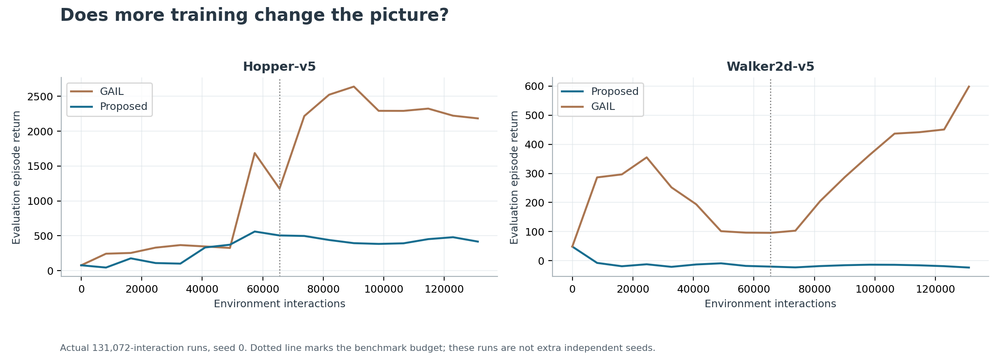

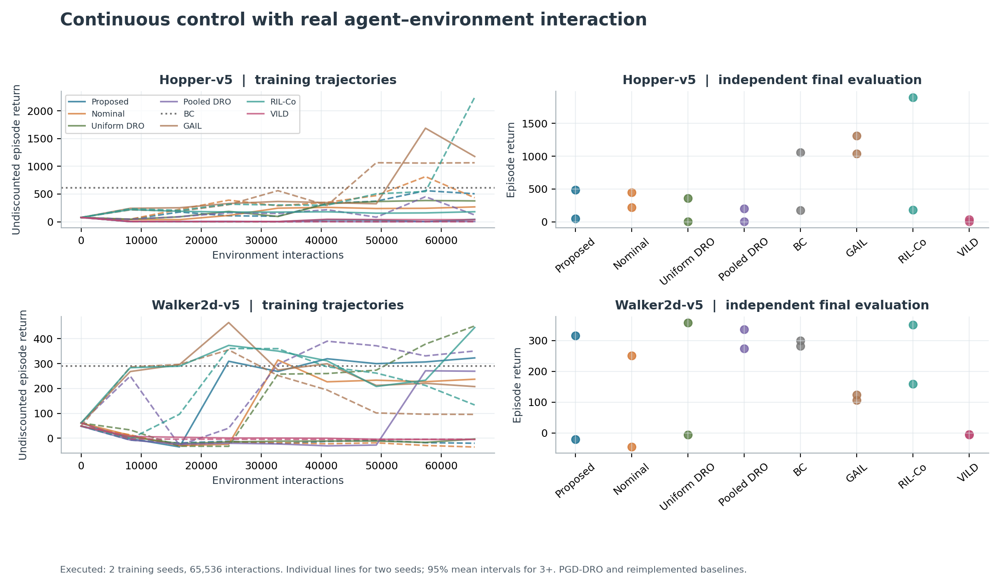

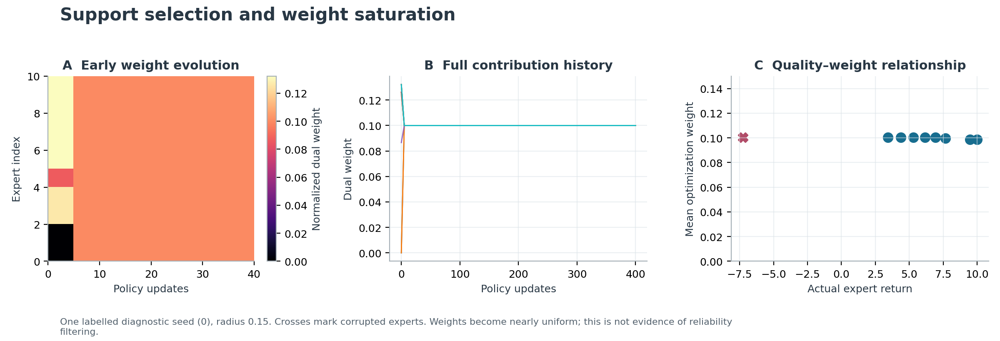

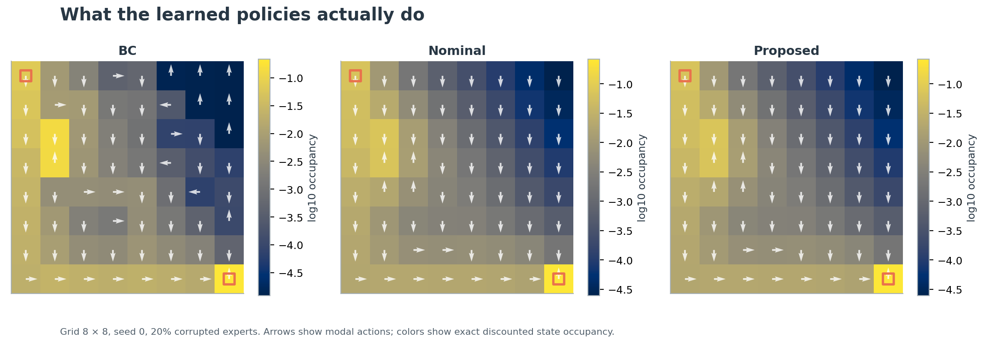

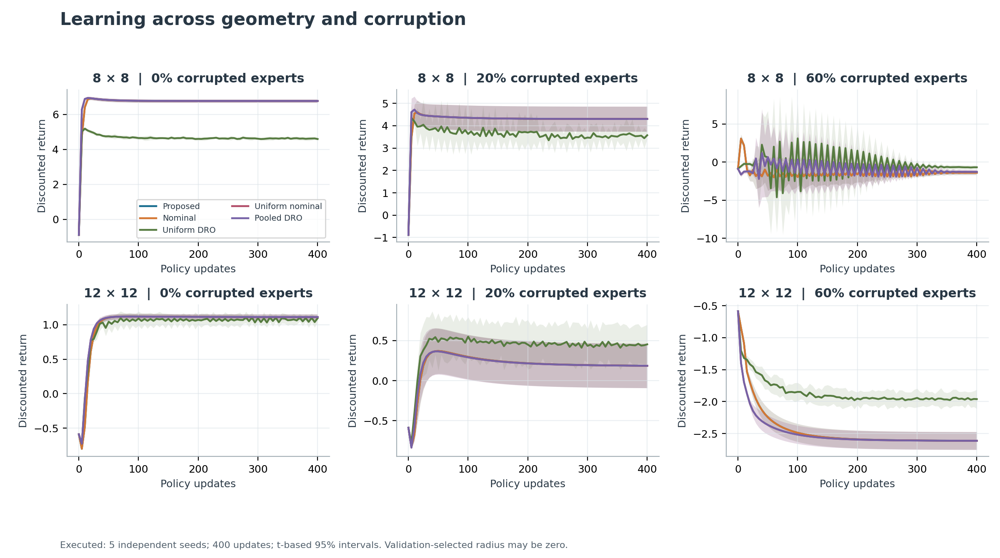

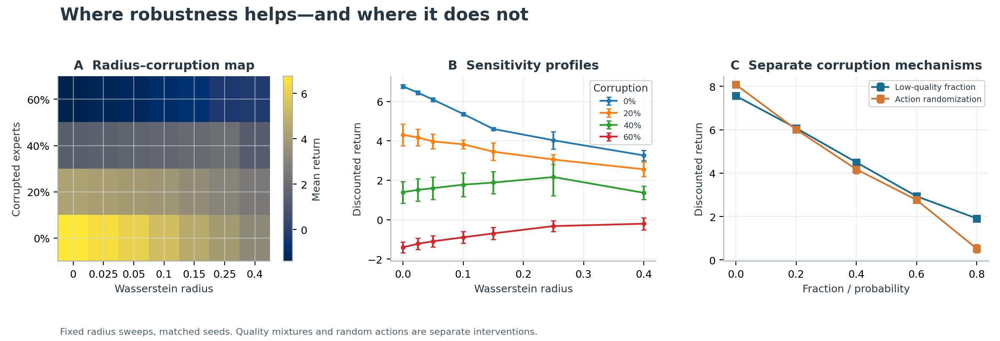

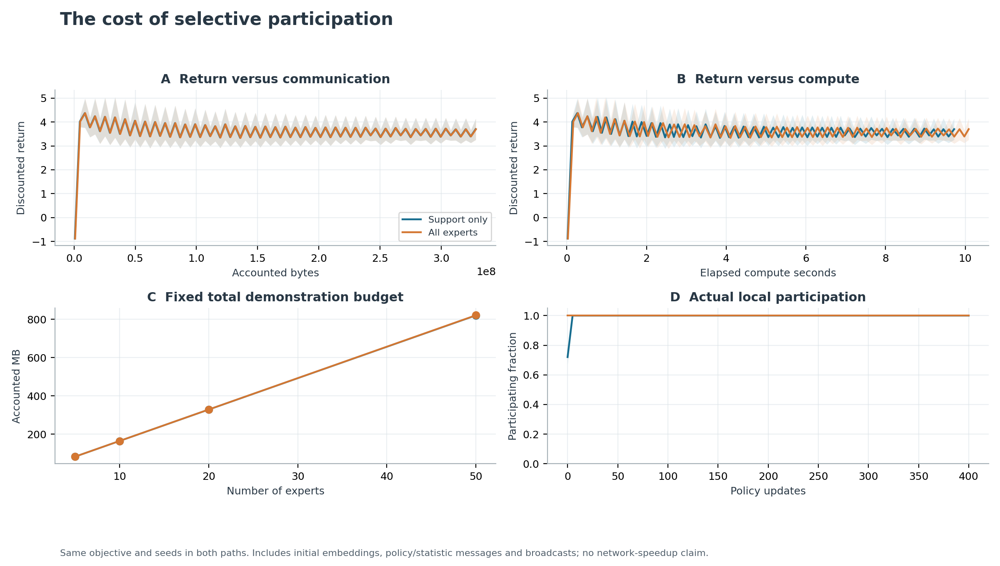

In [14]:
if RUN_A:
    figure_files=sorted((A_OUT/"figures").glob("*.png"))
    table_files=sorted((A_OUT/"tables").glob("*.html"))
else:
    figure_files=sorted((WORK/"saved_outputs/A").glob("figure_*.png"))
    table_files=sorted((WORK/"saved_outputs/A").glob("table_*.html"))
for path in figure_files: display(Image(filename=str(path)))
for path in table_files: display(HTML(path.read_text()))


## 4. Suite B - complete implementation
Original code extracted from the attached Executed notebook. Continuous tasks are custom CoupledReach plants, with known-dynamics pathwise policy gradients; these are not MuJoCo experiments. All modules, reporting infrastructure, tests and the original command-line entry point are visible below.

### B: feature transport and conservative support selector
`src/core.py` - original implementation, shown in full below. Run this cell to write the module used by this suite.

In [15]:
%%writefile {B_ROOT}/src/core.py
"""Manuscript-faithful finite-feature robust selection and W1 inner problems.
The robust margin is the conservative RKHS-norm counterpart in Response 1.9.
The local loss is explicitly ell(mu,z)=gain*(||mu||^2/2+1/2-<mu,phi(z)>).
It is affine in the expert law; it is NOT robust KL, JS, or squared MMD.
"""
from __future__ import annotations
import os
for key in ('OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS','NUMEXPR_NUM_THREADS'):
    os.environ.setdefault(key,'1')
import json, time, hashlib, warnings
from dataclasses import dataclass, asdict
from pathlib import Path
import numpy as np
from scipy.optimize import minimize, linprog
from scipy.stats import t as student_t
from threadpoolctl import threadpool_limits
threadpool_limits(1)
VERSION='jstsp-verified-review-2026-10-v2'


def save_json(path, value):
    p=Path(path);p.parent.mkdir(parents=True,exist_ok=True)
    t=p.with_suffix(p.suffix+'.tmp')
    t.write_text(json.dumps(value,indent=2,allow_nan=False,default=lambda x:x.tolist() if isinstance(x,np.ndarray) else float(x)),encoding='utf8');t.replace(p)


def stable_seed(*parts):
    return int.from_bytes(hashlib.sha256('|'.join(map(str,parts)).encode()).digest()[:4],'little')


def array_hash(*arrays):
    h=hashlib.sha256()
    for a in arrays:
        x=np.ascontiguousarray(a);h.update(str(x.shape).encode());h.update(str(x.dtype).encode());h.update(x.tobytes())
    return h.hexdigest()


def mean_ci(x,level=.95):
    x=np.asarray(x,float);x=x[np.isfinite(x)]
    if not len(x):return (float('nan'),)*3
    m=float(x.mean());h=float(student_t.ppf((1+level)/2,len(x)-1)*x.std(ddof=1)/np.sqrt(len(x))) if len(x)>1 else 0.
    return m,m-h,m+h


class SupportSelector:
    """Exact numerical dual of the conservative margin problem; no screening.
    alpha_e<=C_E, beta=sum(alpha)<=C_pi; both variants retain a free intercept.
    A recovered primal supplies a primal-dual certificate every call.
    """
    def __init__(self, embeddings, radii, C_E=1., C_pi=1., eps_pi=0.,tol=2e-6):
        self.M=np.asarray(embeddings,np.float64)
        self.eps=np.broadcast_to(np.asarray(radii,float),(len(self.M),)).copy()
        self.CE=float(C_E);self.Cp=float(C_pi);self.ep=float(eps_pi);self.tol=tol
        if min(self.CE,self.Cp)<=0 or min(self.eps)<0 or self.ep<0 or not np.isfinite(self.M).all() or not np.isfinite(self.eps).all():raise ValueError('Invalid margin embeddings, penalties or radii')
        self.prev=np.full(len(self.M), min(self.CE,self.Cp/len(self.M))/2)

    def solve(self, mu):
        D=self.M-np.asarray(mu,float);rad=self.eps+self.ep
        def fg(a):
            v=a@D;nv=np.linalg.norm(v);r=max(nv-a@rad,0.)
            f=.5*r*r-2*a.sum()
            g=r*((D@v)/max(nv,1e-30)-rad)-2.
            return f,g
        best=None
        for attempt in range(3):
            init=self.prev if attempt==0 else np.full(len(D),min(self.CE,self.Cp/len(D))*(1 if attempt==1 else .1))
            res=minimize(fg,init,jac=True,method='SLSQP',bounds=[(0,self.CE)]*len(D),
                constraints={'type':'ineq','fun':lambda a:self.Cp-a.sum(),'jac':lambda a:-np.ones(len(a))},
                options={'ftol':1e-12,'maxiter':800})
            a=np.clip(res.x,0,self.CE);a[a<1e-9]=0.
            if a.sum()>self.Cp:a*=self.Cp/a.sum()
            beta=a.sum();v=a@D;delta=a@rad;nv=np.linalg.norm(v)
            w=v*max(1-delta/max(nv,1e-30),0.);nw=np.linalg.norm(w)
            A=1-self.M@w+self.eps*nw;B=1+np.dot(mu,w)+self.ep*nw
            candidates=np.r_[A,-B,0.]
            objectives=self.CE*np.maximum(A[:,None]-candidates[None,:],0).sum(0)+self.Cp*np.maximum(B+candidates,0)
            jj=objectives.argmin();primal=.5*nw*nw+objectives[jj]
            dual=2*beta-.5*max(nv-delta,0.)**2;gap=float(primal-dual)
            row=dict(alpha=a,weights=a/max(beta,1e-30),w=w,b=float(candidates[jj]),beta=float(beta),
                gap=gap,relative_gap=gap/max(1.,abs(primal)),primal=float(primal),dual=float(dual),
                zero_separator=bool(nw<1e-8),w_norm=float(nw),support=a>0,
                solver_success=bool(res.success),iterations=int(res.nit))
            if best is None or row['relative_gap']<best['relative_gap']:best=row
            if row['relative_gap']<self.tol and beta>0:break
        if best['beta']<=0 or best['relative_gap']>self.tol or best['relative_gap'] < -self.tol:
            raise RuntimeError(f"SVE certificate failed: gap={best['relative_gap']:.3g}")
        self.prev=best['alpha'].copy();return best


def finite_transport(values, q, costs, radius, max_eta=None, tol=1e-8, iterations=32):
    """Exact finite-support W1 supremum to a numerical primal/dual gap.
    costs: destination x source. q: source mass. values: destination loss.
    Mixture of two optimal maps at the dual breakpoint enforces the budget.
    """
    v=np.asarray(values,float);q=np.asarray(q,float);C=np.asarray(costs,float)
    if not (np.isfinite(v).all() and np.isfinite(q).all() and np.isfinite(C).all() and np.isfinite(radius)) or np.min(C)<-1e-12 or np.min(q)<-1e-12 or abs(q.sum()-1)>1e-7 or radius<0:raise ValueError('Invalid transport instance')
    if C.shape!=(len(v),len(q)):raise ValueError('Cost matrix shape mismatch')
    if radius<=1e-14:
        ids=np.where(C<=1e-12,v[:,None],-np.inf).argmax(0)
        if np.max(C[ids,np.arange(len(q))])>1e-8:raise ValueError('Zero-radius support must contain every source')
        out=np.bincount(ids,weights=q,minlength=len(v));return dict(mass=out,value=float(out@v),eta=float(max_eta or 0),gap=0.,cost=0.,iterations=0)
    j=np.arange(len(q))
    if np.ptp(v)<1e-14:
        ids=C.argmin(0);cost=float(q@C[ids,j])
        if cost<=radius+tol:
            mass=np.bincount(ids,weights=q,minlength=len(v))
            return dict(mass=mass,value=float(mass@v),eta=0.,gap=0.,cost=cost,iterations=0)
    def at(eta):
        scores=v[:,None]-eta*C;idx=scores.argmax(0)
        cost=float(q@C[idx,j]);value=float(q@v[idx]);dual=float(eta*radius+q@scores[idx,j])
        return idx,cost,value,dual
    low=at(0.)
    if low[1]<=radius+tol:
        mass=np.bincount(low[0],weights=q,minlength=len(v));return dict(mass=mass,value=low[2],eta=0.,gap=0.,cost=low[1],iterations=0)
    lo=0.;hi=max(float(max_eta if max_eta is not None else max(np.ptp(v),1.)),1e-12)
    high=at(hi)
    for _ in range(60):
        if high[1]<=radius:break
        hi*=2;high=at(hi)
    else:raise RuntimeError('Transport dual bracket failed')
    for it in range(iterations):
        eta=(lo+hi)/2;mid=at(eta)
        if mid[1]>radius:lo=eta;low=mid
        else:hi=eta;high=mid
        lam=np.clip((radius-high[1])/max(low[1]-high[1],1e-30),0,1)
        primal=lam*low[2]+(1-lam)*high[2]
        gap=max(0,min(low[3],high[3])-primal)
        if gap<=tol:break
    mass=lam*np.bincount(low[0],weights=q,minlength=len(v))+(1-lam)*np.bincount(high[0],weights=q,minlength=len(v))
    return dict(mass=mass,value=float(mass@v),eta=float(hi),gap=float(gap),cost=float(lam*low[1]+(1-lam)*high[1]),iterations=it+1)


def packet_bytes(E,D,P,active,server_extra=0,dtype_bytes=8):
    """Accounted unicast payload, not measured network throughput.
    Policy broadcast to all E; mu and the policy-Jacobian/statistics to active.
    Each active expert returns a P-vector gradient plus one local scalar.
    """
    init=E*(D+1)*dtype_bytes
    broadcast=E*P*dtype_bytes
    requests=active*(D+server_extra)*dtype_bytes
    responses=active*(P+1)*dtype_bytes
    return dict(initial=init,broadcast=broadcast,requests=requests,responses=responses,total=broadcast+requests+responses)


Writing /workspace/scratch/4de2eab25bc8/work/visible_notebook/test_run/JSTSP_Code_Study/B/src/core.py


### B: grid environment and all grid learners
`src/finite.py` - original implementation, shown in full below. Run this cell to write the module used by this suite.

In [16]:
%%writefile {B_ROOT}/src/finite.py
"""Finite-state experiment: exact transition-gradient estimator and W1 oracles.
Expert occupancies stay in LocalExpert. The server receives embeddings, radii,
and policy-gradient vectors. Exact model-based evaluation is not counted as
model-free environment-interaction efficiency.
"""
from __future__ import annotations
import time, json
from pathlib import Path
import numpy as np
from scipy import linalg
from scipy.special import softmax, expit
from core import SupportSelector,finite_transport,packet_bytes,stable_seed,array_hash

class GridWorld:
    def __init__(self,size=8,gamma=.9,horizon=41,bandwidth=.25):
        self.n=size;self.gamma=gamma;self.horizon=horizon
        self.cells=[(r,c) for r in range(size) for c in range(size)]
        self.S=size*size;self.A=4;self.P=self.S*4;self.start=0;self.goal=self.S-1
        self.nxt=np.empty((self.S,4),int)
        for s,(r,c) in enumerate(self.cells):
            for a,(dr,dc) in enumerate([(-1,0),(1,0),(0,-1),(0,1)]):
                self.nxt[s,a]=s if s==self.goal else min(size-1,max(0,r+dr))*size+min(size-1,max(0,c+dc))
        self.bad_cells=[(2,1),(3,1),(4,1),(5,2),(5,3),(6,3)] if size==8 else [(size//2,c) for c in range(1,size-2)]
        rs=np.full(self.S,-.02)
        for r,c in self.bad_cells:rs[r*size+c]=-.4
        rs[self.goal]=1.;self.r=rs[self.nxt]
        xy=np.array(self.cells,float)/(size-1)
        ks=np.exp(-np.sum((xy[:,None]-xy[None,:])**2,axis=-1)/(2*bandwidth**2))
        ka=.1+.9*np.eye(4)
        self.K=.95*np.kron(ks,ka)+.05*np.eye(self.P)
        self.F=linalg.cholesky(self.K,lower=True,check_finite=False)
        self.C=np.sqrt(np.maximum(2-2*self.K,0));np.fill_diagonal(self.C,0)
        self.good=self.optimal(1);self.bad=self.optimal(-1)
        self.oracle=self.statistics(self.good)['p'];self.uniform=np.full((self.S,4),.25)
        self.oracle_return=self.metrics(self.good)['return'];self.random_return=self.metrics(self.uniform)['return']
    def optimal(self,sign):
        v=np.zeros(self.S)
        for it in range(2000):
            q=sign*self.r+self.gamma*v[self.nxt];vn=q.max(1)
            if np.max(abs(vn-v))<1e-12:break
            v=vn
        else:raise RuntimeError('Grid value iteration failed')
        return np.eye(4)[q.argmax(1)]
    def statistics(self,pi):
        P=np.zeros((self.S,self.S));np.add.at(P,(np.repeat(np.arange(self.S),4),self.nxt.ravel()),pi.ravel())
        R=linalg.solve(np.eye(self.S)-self.gamma*P,np.eye(self.S),check_finite=False)
        d=(1-self.gamma)*R[self.start];p=(d[:,None]*pi).ravel()
        return dict(pi=pi,P=P,R=R,d=d,p=p,mu=p@self.F)
    def gradient(self,cost,stats):
        c=np.asarray(cost).reshape(self.S,4);pi=stats['pi']
        v=stats['R']@(pi*c).sum(1)
        return stats['d'][:,None]*pi*(c+self.gamma*v[self.nxt]-v[:,None])
    def metrics(self,pi,slip=0.):
        pi=(1-slip)*pi+slip/4;st=self.statistics(pi);p=st['p'];d0=np.zeros(self.S);d0[0]=1
        for _ in range(120):d0=d0@st['P']
        return dict(return_=float(p@self.r.ravel()/(1-self.gamma)), **{'return':float(p@self.r.ravel()/(1-self.gamma))},
            success=float(d0[self.goal]),occupancy_error=float(np.linalg.norm(p-self.oracle)) if hasattr(self,'oracle') else 0.,
            entropy=float(-(p.reshape(self.S,4)*np.log(np.maximum(pi,1e-300))).sum()))
    def sample(self,pi,N,seed):
        rng=np.random.default_rng(seed);u=rng.random((N,self.horizon));s=np.zeros(N,dtype=int)
        hist=np.zeros(self.P);counts=np.zeros(self.P,dtype=int);halves=np.zeros((2,self.P))
        weights=self.gamma**np.arange(self.horizon);weights/=weights.sum()
        for t in range(self.horizon):
            a=(u[:,t,None]>pi[s].cumsum(1)[:,:-1]).sum(1);ids=4*s+a
            np.add.at(hist,ids,weights[t]/N);np.add.at(counts,ids,1)
            for k in (0,1):
                mask=np.arange(N)%2==k
                if mask.any():np.add.at(halves[k],ids[mask],weights[t]/mask.sum())
            s=self.nxt[s,a]
        return hist,counts,halves
    def dataset(self,seed,E=10,budget=500,q=0.,noise_max=.30):
        if budget%E:raise ValueError('Fixed trajectory budget must divide E')
        N=budget//E;noise=np.linspace(.01,noise_max,E)
        order=np.random.default_rng(stable_seed('corruption',seed)).permutation(E)
        mask=np.zeros(E,bool);mask[order[:int(np.ceil(E*q-1e-10))]]=True
        occ=[];counts=[];halves=[];quality=[]
        for e in range(E):
            pi=self.bad if mask[e] else (1-noise[e])*self.good+noise[e]/4
            h,c,hh=self.sample(pi,N,stable_seed('grid_demo',seed,e,N));occ.append(h);counts.append(c);halves.append(hh)
            quality.append(self.metrics(pi)['return'])
        occ=np.array(occ);counts=np.array(counts);halves=np.array(halves)
        return dict(occupancies=occ,counts=counts,halves=halves,noise=noise,corrupted=mask,quality=np.array(quality),
            hash=array_hash(occ,counts),seed=seed,E=E,N=N,budget=budget,q=float(q),noise_max=float(noise_max))

class LocalGridExpert:
    def __init__(self,world,q,eps):
        self.world=world;self.q=q;self.eps=eps;self.ids=np.flatnonzero(q>0);self.support_mass=q[self.ids]
        self.mu=q@world.F;self.costs=world.C[:,self.ids]
    def message(self,stats,gain):
        w=self.world
        if self.eps>0:
            tr=finite_transport(-w.F@stats['mu'],self.support_mass,self.costs,self.eps,max_eta=np.linalg.norm(stats['mu']),tol=2e-8,iterations=30)
            target=tr['mass']@w.F
            loss=gain*(.5*np.dot(stats['mu'],stats['mu'])+.5+tr['value'])
        else:
            target=self.mu;tr={'gap':0.,'eta':0.,'cost':0.};loss=gain*(.5*np.dot(stats['mu'],stats['mu'])+.5-np.dot(stats['mu'],target))
        grad=w.gradient(gain*(w.F@(stats['mu']-target)),stats)
        return grad,dict(loss=float(loss),transport_gap=float(tr['gap']),eta=float(tr['eta']),transport_cost=float(tr['cost']))

class AdamArray:
    def __init__(self,shape,lr):self.m=np.zeros(shape);self.v=np.zeros(shape);self.t=0;self.lr=lr
    def step(self,x,g):
        self.t+=1;self.m=.9*self.m+.1*g;self.v=.999*self.v+.001*g*g
        return x-self.lr*(self.m/(1-.9**self.t))/(np.sqrt(self.v/(1-.999**self.t))+1e-8)


def ap_loss(x):
    n=np.logaddexp(0,-x);p=np.logaddexp(0,x)
    return .5*n/(n+p)+.5*expit(-x)

def ap_deriv(x):
    n=np.logaddexp(0,-x);p=np.logaddexp(0,x);dn=-expit(-x);dp=expit(x)
    return .5*(dn*(n+p)-n*(dn+dp))/(n+p)**2-.5*expit(x)*expit(-x)


def fit_grid(world,data,method='dr_sve',radius=.03,gain=100.,updates=160,lr=.1,participation='selected',record_every=1):
    if method not in ('dr_sve','nominal_sve','uniform_dro','uniform_nominal','pooled_dro','bc','gail','rilco'):
        raise ValueError(f'Unknown grid method: {method}')
    if updates < 1 or gain <= 0 or lr <= 0 or radius < 0 or participation not in ('selected','full'):
        raise ValueError('Invalid training budget, gain, radius, learning rate or protocol')
    start=time.perf_counter()
    E=data['E'];P=world.P;D=world.F.shape[1]
    eps=radius if method in ('dr_sve','uniform_dro','pooled_dro') else 0.
    occ=data['occupancies'];qpool=occ.mean(0)
    if method=='pooled_dro':occ=qpool[None,:];Etrain=1
    else:Etrain=E
    clients=[LocalGridExpert(world,q,eps) for q in occ]
    selector=SupportSelector(np.stack([c.mu for c in clients]),np.full(Etrain,eps))
    init_rng=np.random.default_rng(stable_seed('grid_init',data['seed']))
    theta=.005*init_rng.normal(size=(world.S,4));adam=AdamArray(theta.shape,lr)
    rng=np.random.default_rng(stable_seed('grid_adversary',data['seed'],method))
    disc=np.zeros((2,P));dopt=[AdamArray((P,),.05) for _ in (0,1)]
    halves=data['halves'].mean(0);halves/=halves.sum(1,keepdims=True)
    traces=[];expert_log=[];solver_log=[];cum_bytes=Etrain*(D+1)*8;cum_local=0
    initial_bytes=cum_bytes;selector_time=0.;local_time=0.;server_time=0.
    for step in range(updates+1):
        t0=time.perf_counter();pi=softmax(theta,axis=1);st=world.statistics(pi)
        server_time+=time.perf_counter()-t0
        if step%record_every==0 or step==updates:
            met=world.metrics(pi);traces.append(dict(step=step,**met,bytes=cum_bytes,local_evaluations=cum_local,
                seconds=time.perf_counter()-start,selector_seconds=selector_time,local_seconds=local_time,server_seconds=server_time,
                interaction_budget=0,gradient_budget=step))
        if step==updates:break
        entropy_cost=np.log(np.maximum(pi,1e-300));gH=world.gradient(entropy_cost,st)
        if method=='bc':
            pooled=data['counts'].sum(0).reshape(world.S,4);den=pooled.sum(1,keepdims=True)
            pi=np.divide(pooled,den,out=np.full_like(pooled,.25,dtype=float),where=den>0)
            theta=np.log(np.maximum(pi,1e-30));continue
        if method in ('gail','rilco'):
            # Common known-MDP policy-gradient optimizer; sampled discriminator updates.
            B=1024
            for disc_step in range(4):
                if method=='gail':
                    ireal=rng.choice(P,B,p=qpool);ifake=rng.choice(P,B,p=st['p'])
                    grad=(np.bincount(ireal,weights=expit(disc[0,ireal])-1,minlength=P)+np.bincount(ifake,weights=expit(disc[0,ifake]),minlength=P))/B
                    disc[0]=dopt[0].step(disc[0],grad+1e-4*disc[0])
                else:
                    old=disc.copy()
                    for k in (0,1):
                        own=rng.choice(P,B,p=halves[k]);other=rng.choice(P,5*B,p=halves[1-k]);fake=rng.choice(P,B,p=st['p'])
                        pred=old[1-k,other];ix=np.where(pred<0)[0];ps=other[ix[np.argsort(pred[ix])[:B]]]
                        grad=.5*np.bincount(own,weights=ap_deriv(disc[k,own]),minlength=P)/B
                        fake_weight=.25 if len(ps) else .5
                        grad-=fake_weight*np.bincount(fake,weights=ap_deriv(-disc[k,fake]),minlength=P)/B
                        if len(ps):grad-=.25*np.bincount(ps,weights=ap_deriv(-disc[k,ps]),minlength=P)/len(ps)
                        disc[k]=dopt[k].step(disc[k],grad+1e-4*disc[k])
            reward=np.logaddexp(0,disc[0]) if method=='gail' else ap_loss(-disc[0])
            g=world.gradient(-gain*reward,st)+gH
        else:
            ts=time.perf_counter()
            if method in ('dr_sve','nominal_sve'):
                sel=selector.solve(st['mu']);weights=sel['weights'];support=sel['support']
                solver_log.append(dict(step=step,gap=sel['gap'],zero_separator=sel['zero_separator'],support=int(support.sum()),w_norm=sel['w_norm']))
            else:
                weights=np.full(Etrain,1/Etrain);support=np.ones(Etrain,bool);sel=dict(zero_separator=False,gap=0.,w_norm=0.)
            selector_time+=time.perf_counter()-ts
            active=np.arange(Etrain) if participation=='full' else np.flatnonzero(support)
            grads=[];g=np.zeros_like(theta);risk=0.;maxgap=0.;tl=time.perf_counter()
            for e in active:
                gg,info=clients[e].message(st,gain);g+=weights[e]*gg;risk+=weights[e]*info['loss'];maxgap=max(maxgap,info['transport_gap']);cum_local+=1
            local_time+=time.perf_counter()-tl;g+=gH
            pb=packet_bytes(Etrain,D,P,len(active),server_extra=world.S*world.S+world.S)
            cum_bytes+=pb['total']
            for e in range(Etrain):
                expert_log.append(dict(step=step,expert=e,weight=float(weights[e]),support=bool(support[e]),participated=bool(e in active),
                    zero_separator=bool(sel['zero_separator']),quality=float(data['quality'][e]) if Etrain==E else float(data['quality'].mean()),
                    corrupted=bool(data['corrupted'][e]) if Etrain==E else False))
            if traces and traces[-1]['step']==step:traces[-1].update(risk=risk,transport_gap=maxgap,dual_gap=sel['gap'],support_fraction=float(support.mean()))
        if not np.isfinite(g).all():raise ArithmeticError('Nonfinite grid gradient')
        theta=adam.step(theta,g);theta-=theta.mean(1,keepdims=True);theta=np.clip(theta,-40,40)
    met=world.metrics(pi)
    return dict(policy=pi,metrics=met,trace=traces,experts=expert_log,solvers=solver_log,
        data_hash=data['hash'],config=dict(method=method,radius=radius,gain=gain,updates=updates,lr=lr,participation=participation),
        initial_bytes=initial_bytes,total_bytes=cum_bytes,local_evaluations=cum_local,elapsed=time.perf_counter()-start)


Writing /workspace/scratch/4de2eab25bc8/work/visible_notebook/test_run/JSTSP_Code_Study/B/src/finite.py


### B: CoupledReach and continuous learners, including BC/GAIL/RIL-Co/VILD
`src/continuous.py` - original implementation, shown in full below. Run this cell to write the module used by this suite.

In [17]:
%%writefile {B_ROOT}/src/continuous.py
"""Interactive nonlinear continuous-control tests with a common pathwise optimizer.
These are explicitly custom differentiable benchmarks, NOT MuJoCo evaluations.
The learner uses simulator derivatives and demonstrations, never the true reward.
GAIL, RIL-Co and VILD implement their published imitation objectives with the
same model-based policy-gradient backbone; they are not official-score reproductions.
"""
from __future__ import annotations
import time,math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as TF
from core import SupportSelector,finite_transport,packet_bytes,stable_seed,array_hash

torch.set_num_threads(1)
DT=torch.float64

class CoupledReach:
    """d coupled actuators: 2d continuous states, d Gaussian command actions.
    Actual bounded torque is tanh(command). Known stochastic dynamics are
    differentiable. Reward is exposed ONLY through evaluate/reward functions.
    """
    def __init__(self,d=2,horizon=48,gamma=.95):
        self.d=d;self.state_dim=2*d;self.action_dim=d;self.horizon=horizon;self.gamma=gamma
        self.name=f'CoupledReach-{d}';self.dt=.12
        L=2*np.eye(d)-np.roll(np.eye(d),1,axis=0)-np.roll(np.eye(d),-1,axis=0)
        if d==2:L=np.array([[1,-1],[-1,1.]])
        self.L=torch.as_tensor(L,dtype=DT);self.mass=torch.linspace(.85,1.15,d,dtype=DT)
        self.weights=torch.as_tensor(gamma**np.arange(horizon),dtype=DT);self.weights/=self.weights.sum()
        self.start_mean=torch.tensor([.9 if j%2==0 else -.9 for j in range(d)],dtype=DT)
    def noise(self,N,seed):
        rng=np.random.default_rng(seed)
        q=torch.as_tensor(rng.normal(size=(N,self.d))*.25,dtype=DT)+self.start_mean
        v=torch.as_tensor(rng.normal(size=(N,self.d))*.12,dtype=DT)
        return dict(x0=torch.cat([q,v],1),action_noise=torch.as_tensor(rng.normal(size=(N,self.horizon,self.d)),dtype=DT),
                    process_noise=torch.as_tensor(rng.normal(size=(N,self.horizon,self.d)),dtype=DT),
                    auxiliary_action_noise=torch.as_tensor(rng.normal(size=(N,self.horizon,self.d)),dtype=DT))
    def transition(self,x,a,eps,mass_scale=1.,disturbance=0.):
        q,v=x[:,:self.d],x[:,self.d:]
        force=2*torch.tanh(a)-.3*torch.sin(q)-.15*(q@self.L.T)-.32*v
        vn=v+self.dt*force/(self.mass*mass_scale)+(.012+disturbance)*eps
        qn=q+self.dt*vn
        return torch.cat([qn.clamp(-3.,3.),vn.clamp(-3.,3.)],1)
    def teacher(self,x,gain=1.,bad=False):
        q,v=x[:,:self.d],x[:,self.d:]
        if bad:return .85*q-.2*v
        return gain*(-1.2*q-.9*v+.15*torch.sin(q)+.075*(q@self.L.T))
    def rollout(self,actor,noise,extra_action_noise=0.,mass_scale=1.,disturbance=0.):
        x=noise['x0'];zs=[]
        for t in range(self.horizon):
            a=actor.mean(x)+actor.logstd.exp()*noise['action_noise'][:,t]
            zs.append(torch.cat([x,a],1))
            # VILD's fixed small Sigma perturbation is separate from policy covariance.
            extra=extra_action_noise*noise['auxiliary_action_noise'][:,t] if extra_action_noise else 0.
            x=self.transition(x,a+extra,noise['process_noise'][:,t],mass_scale,disturbance)
        return torch.stack(zs,1),x
    def reward(self,z):
        q=z[...,:self.d];v=z[...,self.d:2*self.d];a=z[...,2*self.d:]
        return 1-(q*q+.1*v*v+.01*torch.tanh(a)**2).mean(-1)
    def evaluate(self,actor,seed,N=128,mass_scale=1.,disturbance=0.):
        with torch.no_grad():
            z,last=self.rollout(actor,self.noise(N,seed),mass_scale=mass_scale,disturbance=disturbance)
            ret=(self.reward(z)*self.weights).sum(1)
            success=(torch.sqrt((last[:,:self.d]**2).mean(1))<.18).double()
        return dict(return_=float(ret.mean()),**{'return':float(ret.mean())},return_std=float(ret.std()),
                    success=float(success.mean()),endpoint_rmse=float(torch.sqrt((last[:,:self.d]**2).mean())),episodes=N)
    def dataset(self,seed,E=10,budget=200,q=0.,noise_max=.5):
        if budget%E:raise ValueError('Demonstration budget must divide E')
        N=budget//E;order=np.random.default_rng(stable_seed(seed,'ct_corruption')).permutation(E)
        mask=np.zeros(E,bool);mask[order[:int(np.ceil(q*E-1e-10))]]=True
        sigmas=np.linspace(.05,noise_max,E);zall=[];quality=[];gains=[]
        for e in range(E):
            ns=self.noise(N,stable_seed(seed,self.d,e,'demos'));x=ns['x0'];zs=[]
            gain=.9+.2*np.random.default_rng(stable_seed(seed,e,'teacher_gain')).random();gains.append(gain)
            for t in range(self.horizon):
                a=self.teacher(x,gain,bad=bool(mask[e]))+sigmas[e]*ns['action_noise'][:,t]
                zs.append(torch.cat([x,a],1));x=self.transition(x,a,ns['process_noise'][:,t])
            zz=torch.stack(zs,1);zall.append(zz)
            # Quality is evaluation-only, not passed to any gradient/selector.
            quality.append(float((self.reward(zz)*self.weights).sum(1).mean()))
        zz=torch.stack(zall)
        return dict(z=zz,quality=np.array(quality),corrupted=mask,noise=sigmas,gains=np.array(gains),E=E,N=N,
            hash=array_hash(zz.numpy()),seed=seed,q=q,budget=budget,noise_max=noise_max)

class Actor(nn.Module):
    def __init__(self,state_dim,action_dim,hidden=32):
        super().__init__();self.net=nn.Sequential(nn.Linear(state_dim,hidden),nn.Tanh(),nn.Linear(hidden,hidden),nn.Tanh(),nn.Linear(hidden,action_dim)).to(dtype=DT)
        self.logstd=nn.Parameter(torch.full((action_dim,),-.9,dtype=DT))
        with torch.no_grad():self.net[-1].weight.mul_(.02);self.net[-1].bias.zero_()
    def mean(self,x):return self.net(x)
    def entropy(self):return (self.logstd+.5*math.log(2*math.pi*math.e)).sum()
    def nll(self,s,a):
        return (.5*((a-self.mean(s))/self.logstd.exp())**2+self.logstd+.5*math.log(2*math.pi)).sum(-1)
    def constrain(self):
        with torch.no_grad():self.logstd.clamp_(-4.,.5)

class FourierFeatures(nn.Module):
    """Unit-norm feature map, inducing k=<phi,phi'> and kappa=||phi-phi'||."""
    def __init__(self,d,M=24,bandwidth=.6,seed=4421):
        super().__init__();self.d=d;self.M=M
        rng=np.random.default_rng(stable_seed(seed,d,M));W=rng.normal(size=(3*d,M))/(bandwidth*np.sqrt(3*d))
        self.register_buffer('W',torch.tensor(W,dtype=DT))
    def forward(self,z):
        x=torch.cat([z[...,:2*self.d]/1.5,torch.tanh(z[...,2*self.d:])],-1)
        phase=x@self.W
        return torch.cat([torch.cos(phase),torch.sin(phase)],-1)/np.sqrt(self.M)


def discount_embedding(z,features,weights):
    return (features(z)*weights[None,:,None]).sum(1).mean(0)

class ContinuousLocalExpert:
    def __init__(self,z,feature,weights,radius):
        self.z=z.reshape(-1,z.shape[-1]).detach();self.feature=feature;self.radius=radius
        self.prob=np.tile(weights.numpy(),z.shape[0])/z.shape[0]
        with torch.no_grad():self.embedding=(feature(self.z)*torch.tensor(self.prob,dtype=DT)[:,None]).sum(0).numpy()
    def adversary(self,mu,seed,batch=64,search_steps=6):
        """Sampled inner oracle with projected-ascent candidate enrichment.
        The finite candidate transport is certified. For continuous support,
        nominal+epsilon*||mu|| is a valid global upper bound for THIS batch.
        Sampling error relative to the full empirical expectation is separate.
        """
        rng=np.random.default_rng(seed);ids=rng.choice(len(self.z),batch,p=self.prob)
        source=self.z[ids];fsource=self.feature(source).detach().numpy();base=-fsource@mu
        if self.radius<=0:return fsource.mean(0),dict(batch_lower=float(base.mean()),batch_upper=float(base.mean()),inner_gap=0.,transport_gap=0.,cost=0.)
        z=source.clone().detach().requires_grad_(True);mu_t=torch.tensor(mu,dtype=DT)
        # Deterministic gradient ascent enriches the destination cloud; raw source
        # points are retained so every transport problem is feasible at radius 0.
        candidates=[source]
        for j in range(search_steps):
            score=-(self.feature(z)*mu_t).sum(1).sum()
            g=torch.autograd.grad(score,z)[0];g=g/(g.norm(dim=1,keepdim=True)+1e-12)
            z=(z+.16*g).detach();z[:,:2*self.feature.d].clamp_(-3,3);z[:,2*self.feature.d:].clamp_(-5,5)
            if j in (1,search_steps-1):candidates.append(z.clone())
            z.requires_grad_(True)
        dst=torch.cat(candidates).detach();fd=self.feature(dst).detach().numpy()
        C=np.sqrt(np.maximum(((fd[:,None,:]-fsource[None,:,:])**2).sum(-1),0))
        C[np.arange(batch),np.arange(batch)]=0.
        tr=finite_transport(-fd@mu,np.full(batch,1/batch),C,self.radius,max_eta=np.linalg.norm(mu),tol=1e-8,iterations=30)
        target=tr['mass']@fd
        upper=min(float(base.mean()+self.radius*np.linalg.norm(mu)),float(np.linalg.norm(mu)))
        return target,dict(batch_lower=tr['value'],batch_upper=upper,inner_gap=max(0.,upper-tr['value']),
            transport_gap=tr['gap'],cost=tr['cost'])

class Discriminator(nn.Module):
    def __init__(self,input_dim):
        super().__init__();self.net=nn.Sequential(nn.Linear(input_dim,64),nn.Tanh(),nn.Linear(64,64),nn.Tanh(),nn.Linear(64,1)).to(dtype=DT)
    def forward(self,z):return self.net(z).squeeze(-1)


def tensor_ap(x):
    n=TF.softplus(-x);p=TF.softplus(x)
    return .5*n/(n+p)+.5*torch.sigmoid(-x)


def gradient_penalty(net,real,fake,gen,coefficient=1.):
    b=min(len(real),len(fake));t=torch.rand((b,1),generator=gen,dtype=DT)
    x=(t*real[:b]+(1-t)*fake[:b]).detach().requires_grad_(True)
    y=net(x);g=torch.autograd.grad(y.sum(),x,create_graph=True)[0]
    return coefficient*((g.norm(dim=1)-1)**2).mean()

class AdversarialBaseline:
    """GAIL logistic loss, or RIL-Co AP loss (Eqs.16,17,21, Algorithm 1)."""
    def __init__(self,method,z,prob,seed,disc_lr=1e-3,gp_coefficient=1.):
        self.gp_coefficient=gp_coefficient
        self.method=method;self.z=z;self.prob=prob/np.sum(prob);self.rng=np.random.default_rng(stable_seed(seed,method,'disc'))
        torch.manual_seed(stable_seed(seed,method,'disc_init'));self.nets=[Discriminator(z.shape[1]) for _ in range(2 if method=='rilco' else 1)]
        self.opts=[torch.optim.Adam(n.parameters(),lr=disc_lr) for n in self.nets]
        perm=self.rng.permutation(len(z));self.halves=np.array_split(perm,2)
        self.gen=torch.Generator().manual_seed(stable_seed(seed,method,'gp'))
    def draw(self,n,half=None):
        ids=np.arange(len(self.z)) if half is None else self.halves[half]
        p=self.prob[ids];p/=p.sum();return self.z[self.rng.choice(ids,n,p=p)]
    def update(self,fake,steps=4,batch=192):
        for _ in range(steps):
            ff=fake[self.rng.choice(len(fake),batch)]
            real=[self.draw(batch,k if self.method=='rilco' else None) for k in range(len(self.nets))]
            pseudos=[]
            if self.method=='rilco':
                for k in (0,1):
                    other=self.draw(5*batch,1-k)
                    with torch.no_grad():pred=self.nets[1-k](other);ix=torch.where(pred<0)[0];ix=ix[torch.argsort(pred[ix])[:batch]]
                    pseudos.append(other[ix])
            for k,(net,opt) in enumerate(zip(self.nets,self.opts)):
                if self.method=='gail':loss=TF.softplus(-net(real[k])).mean()+TF.softplus(net(ff)).mean()
                else:
                    loss=.5*tensor_ap(net(real[k])).mean()
                    if len(pseudos[k]):loss+=.25*tensor_ap(-net(pseudos[k])).mean()+.25*tensor_ap(-net(ff)).mean()
                    else:loss+=.5*tensor_ap(-net(ff)).mean()
                loss+=gradient_penalty(net,real[k],ff,self.gen,coefficient=self.gp_coefficient)
                opt.zero_grad();loss.backward();opt.step()
    def reward(self,z):
        g=self.nets[0](z)
        return TF.softplus(g) if self.method=='gail' else tensor_ap(-g)

class VILD:
    """VILD (IS): Gaussian posterior/noise models and Eq.13/14 saddle objective.
    The actor uses the SAME pathwise optimizer as all continuous methods.
    Rewards are bounded for numerical regularization; no expert-quality labels.
    """
    def __init__(self,data,seed,disc_lr=1e-3,pretrain=1000,gp_coefficient=1.):
        self.gp_coefficient=gp_coefficient
        z=data['z'];self.E=z.shape[0];self.d=z.shape[-1]//3;self.z=z.reshape(-1,z.shape[-1]);self.per=len(self.z)//self.E
        self.rng=np.random.default_rng(stable_seed(seed,'vild'));torch.manual_seed(stable_seed(seed,'vild_net'))
        self.reward_net=Discriminator(3*self.d)
        self.posterior=nn.Sequential(nn.Linear(3*self.d+self.E,64),nn.Tanh(),nn.Linear(64,64),nn.Tanh(),nn.Linear(64,self.d)).to(dtype=DT)
        self.post_logstd=nn.Parameter(torch.full((self.d,),-2.,dtype=DT));self.noise_logvar=nn.Parameter(torch.full((self.E,self.d),math.log(.25),dtype=DT))
        self.po=torch.optim.Adam(list(self.posterior.parameters())+[self.post_logstd],lr=disc_lr)
        self.no=torch.optim.Adam([self.noise_logvar],lr=disc_lr);self.ro=torch.optim.Adam(self.reward_net.parameters(),lr=disc_lr)
        self.gen=torch.Generator().manual_seed(stable_seed(seed,'vild_antithetic'))
        self.weights=np.tile((.95**np.arange(z.shape[2]))/(.95**np.arange(z.shape[2])).sum(),z.shape[1]);self.weights/=self.weights.sum()
        self.Sigma=1e-6
        for _ in range(pretrain):
            ids,e=self.draw(128);zz=self.z[ids];mean=self.post_mean(zz,e)
            loss=((mean-zz[:,2*self.d:])**2).mean();self.po.zero_grad();loss.backward();self.po.step()
    def draw(self,batch,worker_prob=None):
        p=np.full(self.E,1/self.E) if worker_prob is None else worker_prob
        e=self.rng.choice(self.E,batch,p=p);within=self.rng.choice(self.per,batch,p=self.weights)
        return e*self.per+within,torch.tensor(e,dtype=torch.long)
    def post_mean(self,z,e):
        one=TF.one_hot(e,num_classes=self.E).to(dtype=DT);return self.posterior(torch.cat([z,one],-1))
    def reward(self,z):return 5*torch.tanh(self.reward_net(z)/5)
    def update(self,fake,steps=4,batch=192):
        for _ in range(steps):
            ids,e=self.draw(batch);zz=self.z[ids];u=zz[:,2*self.d:];s=zz[:,:2*self.d]
            m=self.post_mean(zz,e);sd=self.post_logstd.exp();xi=torch.randn(m.shape,generator=self.gen,dtype=DT)
            ap=m+sd*xi;am=m-sd*xi;C=self.noise_logvar[e].exp().detach()
            r=.5*(self.reward(torch.cat([s,ap],1))+self.reward(torch.cat([s,am],1)))
            rec=.5*(((u-m)**2+sd**2)/C).sum(1)
            loss=(rec-r).mean()-self.post_logstd.sum()
            self.po.zero_grad();loss.backward();self.po.step()
            with torch.no_grad():self.post_logstd.clamp_(-5.,.5)
            with torch.no_grad():m=self.post_mean(zz,e);second=(u-m)**2+self.post_logstd.exp()**2
            C=self.noise_logvar[e].exp()
            nloss=.5*((second-self.Sigma)/C+self.noise_logvar[e]).sum(1).mean()
            self.no.zero_grad();nloss.backward();self.no.step()
            with torch.no_grad():self.noise_logvar.clamp_(-8.,3.)
            # Truncated IS exactly as Eq.14: nu_tilde proportional to L1 precision.
            precision=self.noise_logvar.detach().exp().reciprocal().sum(1).numpy();wp=precision/precision.sum()
            ids,e=self.draw(batch,wp);zz=self.z[ids]
            with torch.no_grad():
                m=self.post_mean(zz,e);xi=torch.randn(m.shape,generator=self.gen,dtype=DT);a=m+self.post_logstd.exp()*xi
                latent=torch.cat([zz[:,:2*self.d],a],1)
            ff=fake[self.rng.choice(len(fake),batch)]
            iw=torch.tensor(np.minimum((1/self.E)/wp[e.numpy()],1),dtype=DT)
            rloss=-(iw*self.reward(latent)).mean()+self.reward(ff).mean()
            rloss+=gradient_penalty(self.reward_net,latent,ff,self.gen,coefficient=self.gp_coefficient)
            self.ro.zero_grad();rloss.backward();self.ro.step()


def fit_cont(env,data,method='dr_sve',radius=.03,gain=200.,updates=160,lr=.003,participation='selected',batch_trajectories=16,
             feature_count=24,eval_every=4,eval_episodes=128,eval_final=512,inner_batch=64,inner_steps=6,pretrain_vild=1000,evaluate=True,disc_steps=4,disc_lr=1e-3,gp_coefficient=1.):
    if method not in ('dr_sve','nominal_sve','uniform_dro','uniform_nominal','pooled_dro','bc','gail','rilco','vild'):
        raise ValueError(f'Unknown continuous method: {method}')
    if updates < 1 or gain <= 0 or lr <= 0 or radius < 0 or participation not in ('selected','full'):
        raise ValueError('Invalid training budget, gain, radius, learning rate or protocol')
    start=time.perf_counter()
    seed=data['seed'];d=env.d;E=data['E'];torch.manual_seed(stable_seed(seed,d,'actor'))
    actor=Actor(2*d,d);opt=torch.optim.Adam(actor.parameters(),lr=lr)
    feature=FourierFeatures(d,M=feature_count);D=2*feature_count
    eps=radius if method in ('dr_sve','uniform_dro','pooled_dro') else 0.
    zz=data['z'];Etrain=1 if method=='pooled_dro' else E
    clientdata=[zz.reshape(-1,env.horizon,3*d)] if Etrain==1 else list(zz)
    clients=[ContinuousLocalExpert(z,feature,env.weights,eps) for z in clientdata]
    selector=SupportSelector(np.stack([c.embedding for c in clients]),np.full(Etrain,eps))
    zpool=zz.reshape(-1,3*d);prob=np.tile(env.weights.numpy(),len(zpool)//env.horizon);prob/=prob.sum()
    baseline=None
    if method in ('gail','rilco'):baseline=AdversarialBaseline(method,zpool,prob,seed,disc_lr=disc_lr,gp_coefficient=gp_coefficient)
    elif method=='vild':baseline=VILD(data,seed,pretrain=pretrain_vild,disc_lr=disc_lr,gp_coefficient=gp_coefficient)
    params=list(actor.parameters());P=sum(x.numel() for x in params)
    trace=[];elog=[];oracles=[];cumlocal=0;cumbytes=Etrain*(D+1)*8;initial_bytes=cumbytes
    setup_seconds=time.perf_counter()-start;tsel=tlocal=tserver=0.;lastgap=0.;lastsupport=1.
    for step in range(updates+1):
        if evaluate and (step%eval_every==0 or step==updates):
            evseed=stable_seed(seed,d,'eval',step) if step<updates else stable_seed(seed,d,'final_eval')
            met=env.evaluate(actor,evseed,N=eval_final if step==updates else eval_episodes)
            trace.append(dict(step=step,interactions=step*batch_trajectories*env.horizon if method!='bc' else 0,**met,
                bytes=cumbytes,local_evaluations=cumlocal,seconds=time.perf_counter()-start,selector_seconds=tsel,
                local_seconds=tlocal,server_seconds=tserver,inner_gap=lastgap,support_fraction=lastsupport))
        if not all(torch.isfinite(p).all() for p in params):
            raise FloatingPointError(f'{method}: nonfinite actor at step {step}')
        if step==updates:break
        ns=env.noise(batch_trajectories,stable_seed(seed,d,'rollout',step))
        ts=time.perf_counter()
        if method=='bc':
            rng=np.random.default_rng(stable_seed(seed,d,'bc_batch',step))
            # BC uses unweighted pooled demonstrations, with four optimizer steps
            # per outer index. Its actual supervised update count is exported.
            for _ in range(4):
                iz=rng.integers(0,len(zpool),512);z=zpool[iz]
                loss=actor.nll(z[:,:2*d],z[:,2*d:]).mean();opt.zero_grad();loss.backward();torch.nn.utils.clip_grad_norm_(params,10);opt.step();actor.constrain()
            tserver+=time.perf_counter()-ts;continue
        z,last=env.rollout(actor,ns,extra_action_noise=.001 if method=='vild' else 0.)
        mu=discount_embedding(z,feature,env.weights);mu_np=mu.detach().numpy();tserver+=time.perf_counter()-ts
        if method in ('gail','rilco','vild'):
            # Discount-correct sample of learner transitions for discriminator updates.
            rr=np.random.default_rng(stable_seed(seed,d,'fake_batch',step));pp=np.tile(env.weights.numpy(),batch_trajectories)/batch_trajectories
            fake=z.detach().reshape(-1,3*d)[rr.choice(batch_trajectories*env.horizon,1024,p=pp)]
            ta=time.perf_counter();baseline.update(fake,steps=disc_steps)
            rew=baseline.reward(z.reshape(-1,3*d)).reshape(batch_trajectories,env.horizon)
            # gain rescales the declared learned imitation cost, entropy stays 1.
            loss=-gain*(rew*env.weights).sum(1).mean()-actor.entropy()
            opt.zero_grad();loss.backward();torch.nn.utils.clip_grad_norm_(params,10);opt.step();actor.constrain()
            tserver+=time.perf_counter()-ta
        else:
            ts=time.perf_counter()
            if method in ('dr_sve','nominal_sve'):
                sel=selector.solve(mu_np);weights=sel['weights'];support=sel['support']
            else:weights=np.full(Etrain,1/Etrain);support=np.ones(Etrain,bool);sel=dict(gap=0.,zero_separator=False,w_norm=0.)
            tsel+=time.perf_counter()-ts;active=np.arange(Etrain) if participation=='full' else np.flatnonzero(support)
            gs=[torch.zeros_like(p) for p in params];lastgap=0.;lastsupport=float(support.mean());tl=time.perf_counter()
            for e in active:
                target,info=clients[e].adversary(mu_np,stable_seed(seed,d,step,e,'local'),batch=inner_batch,search_steps=inner_steps)
                # Local VJP; a remote client can replay the disclosed simulator
                # with policy, x0, and exogenous-noise arrays. No expert data leave.
                g=torch.autograd.grad(mu,params,grad_outputs=gain*torch.tensor(mu_np-target,dtype=DT),retain_graph=True,allow_unused=True)
                for j,x in enumerate(g):
                    if x is not None:gs[j]+=float(weights[e])*x.detach()
                lastgap=max(lastgap,info['inner_gap']);cumlocal+=1
                oracles.append(dict(step=step,expert=int(e),**info))
            ent=torch.autograd.grad(-actor.entropy(),params,allow_unused=True)
            for j,x in enumerate(ent):
                if x is not None:gs[j]+=x.detach()
            tlocal+=time.perf_counter()-tl
            opt.zero_grad()
            for p,g in zip(params,gs):p.grad=g
            torch.nn.utils.clip_grad_norm_(params,10);opt.step();actor.constrain()
            extra=ns['x0'].numel()+ns['action_noise'].numel()+ns['process_noise'].numel()
            pb=packet_bytes(Etrain,D,P,len(active),server_extra=extra);cumbytes+=pb['total']
            for e in range(Etrain):
                elog.append(dict(step=step,expert=e,weight=float(weights[e]),support=bool(support[e]),participated=bool(e in active),
                    zero_separator=bool(sel['zero_separator']),dual_gap=float(sel['gap']),w_norm=float(sel['w_norm']),
                    quality=float(data['quality'][e]) if Etrain==E else float(data['quality'].mean()),
                    corrupted=bool(data['corrupted'][e]) if Etrain==E else False))
    final={k:trace[-1][k] for k in ('return_','return','return_std','success','endpoint_rmse','episodes')} if evaluate else {}
    weights={k:v.detach().numpy() for k,v in actor.state_dict().items()}
    return dict(policy=weights,metrics=final,trace=trace,experts=elog,oracles=oracles,data_hash=data['hash'],
        config=dict(method=method,radius=radius,gain=gain,updates=updates,lr=lr,participation=participation,model_based=True,
            batch_trajectories=batch_trajectories,inner_batch=inner_batch,inner_steps=inner_steps,feature_count=feature_count,
            supervised_updates=4*updates if method=='bc' else 0,pretrain_vild=pretrain_vild if method=='vild' else 0,
            disc_steps=disc_steps,disc_lr=disc_lr,gp_coefficient=gp_coefficient,setup_seconds=setup_seconds),
        initial_bytes=initial_bytes,total_bytes=cumbytes,local_evaluations=cumlocal,elapsed=time.perf_counter()-start,
        vild_covariance=baseline.noise_logvar.detach().exp().numpy() if method=='vild' else None)


def restore_actor(env,state):
    a=Actor(env.state_dim,env.action_dim);a.load_state_dict({k:torch.tensor(v,dtype=DT) for k,v in state.items()});return a


Writing /workspace/scratch/4de2eab25bc8/work/visible_notebook/test_run/JSTSP_Code_Study/B/src/continuous.py


### B: numerical checks
`src/verify.py` - original implementation, shown in full below. Run this cell to write the module used by this suite.

In [18]:
%%writefile {B_ROOT}/src/verify.py
"""Independent numerical checks; exceptions stop the experimental pipeline."""
from pathlib import Path
import time,json
import numpy as np
from scipy.optimize import linprog
from scipy.special import softmax
import torch
from core import *
from finite import *
from continuous import *


def run_checks(destination=None):
    checks=[];start=time.perf_counter()
    def ck(name,condition,value=None,tolerance=None):
        if not bool(condition):raise AssertionError(f'{name}: {value}, tolerance={tolerance}')
        checks.append(dict(name=name,passed=True,value=float(value) if value is not None else None,tolerance=tolerance))
    rng=np.random.default_rng(8481)
    # W1 oracle compared to a full independent transport linear program.
    for n in (5,9):
        F=rng.normal(size=(n,4));F/=np.linalg.norm(F,axis=1,keepdims=True)
        C=np.linalg.norm(F[:,None]-F[None,:],axis=-1);q=rng.dirichlet(np.ones(n));v=rng.normal(size=n)
        A=np.zeros((n,n*n))
        for j in range(n):A[j,np.arange(n)*n+j]=1
        for eps in (0.,.07,.4,2.):
            tr=finite_transport(v,q,C,eps,tol=1e-9,iterations=48)
            lp=linprog(-np.repeat(v,n),A_ub=C.reshape(1,-1),b_ub=[eps],A_eq=A,b_eq=q,bounds=(0,None),method='highs')
            ck(f'transport_LP_n{n}_r{eps}',lp.success and abs(tr['value']+lp.fun)<2e-7,abs(tr['value']+lp.fun),2e-7)
            ck(f'transport_budget_n{n}_r{eps}',tr['cost']<=eps+1e-9 and abs(tr['mass'].sum()-1)<1e-10,tr['cost']-eps,1e-9)
    tr=finite_transport(np.zeros(3),np.ones(3)/3,np.ones((3,3))-np.eye(3),.1,max_eta=0.)
    ck('constant_loss_zero_multiplier',tr['gap']==0 and tr['cost']==0)
    M=rng.normal(size=(7,6));M/=np.linalg.norm(M,axis=1,keepdims=True)
    for eps in (0.,.1,2.):
        so=SupportSelector(M,np.full(7,eps));r=so.solve(rng.normal(size=6)*.2)
        ck(f'margin_certificate_{eps}',-1e-8<=r['gap']<2e-6,abs(r['gap']),2e-6)
        ck(f'margin_balance_box_{eps}',abs(r['beta']-r['alpha'].sum())<1e-12 and r['alpha'].max()<=1 and r['beta']<=1+1e-10)
    w=GridWorld();dat=w.dataset(71,budget=100,q=.3)
    ck('occupancies_normalized',np.max(abs(dat['occupancies'].sum(1)-1))<1e-12)
    ck('RKHS_kernel_gram',np.max(abs(w.F@w.F.T-w.K))<1e-12)
    ck('feature_ground_cost',np.max(abs(w.C-np.linalg.norm(w.F[:,None]-w.F[None,:],axis=-1)))<3e-8)
    theta=rng.normal(size=(w.S,4))*.1;st=w.statistics(softmax(theta,axis=1));direction=rng.normal(size=theta.shape);direction/=np.linalg.norm(direction)
    client=LocalGridExpert(w,dat['occupancies'][0],.03);g,info=client.message(st,100.)
    analytic=float((g*direction).sum());h=2e-5
    vals=[]
    for sign in (-1,1):
        _,ii=client.message(w.statistics(softmax(theta+sign*h*direction,axis=1)),100.)
        vals.append(ii['loss'])
    numeric=(vals[1]-vals[0])/(2*h)
    ck('finite_robust_Danskin_gradient',abs(analytic-numeric)<2e-4,abs(analytic-numeric),2e-4)
    def ent(th):
        pi=softmax(th,axis=1);ss=w.statistics(pi);return float((ss['p']*np.log(pi.ravel())).sum())
    ge=w.gradient(np.log(st['pi']),st);num=(ent(theta+h*direction)-ent(theta-h*direction))/(2*h)
    ck('finite_causal_entropy_gradient',abs((ge*direction).sum()-num)<1e-6,abs((ge*direction).sum()-num),1e-6)
    # Discounted flow equation, independently from sampled trajectories.
    flow=st['d']-(1-w.gamma)*np.eye(w.S)[0]-w.gamma*st['d']@st['P']
    ck('discounted_flow',abs(flow).max()<1e-12,abs(flow).max(),1e-12)
    r1=fit_grid(w,dat,updates=12,participation='selected');r2=fit_grid(w,dat,updates=12,participation='full')
    ck('finite_selected_equals_full',np.max(abs(r1['policy']-r2['policy']))<1e-12,np.max(abs(r1['policy']-r2['policy'])),1e-12)
    ck('finite_selected_not_more_bytes',r1['total_bytes']<=r2['total_bytes'])
    nom=fit_grid(w,dat,method='nominal_sve',updates=8);zero=fit_grid(w,dat,method='dr_sve',radius=0.,updates=8)
    ck('zero_radius_is_nominal',np.max(abs(nom['policy']-zero['policy']))<1e-12)
    d2=w.dataset(71,budget=100,q=.6)
    ck('nested_corruption',np.all(d2['corrupted'][dat['corrupted']]))
    xx=np.linspace(-20,20,101);ck('AP_symmetric',np.max(abs(ap_loss(xx)+ap_loss(-xx)-1))<1e-12)
    ck('AP_derivative',np.max(abs(ap_deriv(xx)-(ap_loss(xx+1e-5)-ap_loss(xx-1e-5))/2e-5))<1e-8)
    en=CoupledReach(2,horizon=16);dt=en.dataset(91,E=5,budget=25,q=.2)
    feat=FourierFeatures(2,M=12);z=dt['z'][0]
    ck('continuous_unit_features',float((feat(z).norm(dim=-1)-1).abs().max())<1e-12)
    torch.manual_seed(13);actor=Actor(4,2);ns=en.noise(4,31);params=list(actor.parameters())
    zz,_=en.rollout(actor,ns);mu=discount_embedding(zz,feat,en.weights);target=torch.tensor(rng.normal(size=24),dtype=DT)
    obj=.5*(mu@mu)-mu@target-actor.entropy()/100
    gg=torch.autograd.grad(obj,params);directions=[torch.tensor(rng.normal(size=p.shape),dtype=DT) for p in params]
    norm=torch.sqrt(sum((x*x).sum() for x in directions));directions=[x/norm for x in directions]
    an=float(sum((g*d).sum() for g,d in zip(gg,directions)));base=[p.detach().clone() for p in params]
    vals=[]
    for sign in (-1,1):
        with torch.no_grad():
            for p,b,d in zip(params,base,directions):p.copy_(b+sign*1e-5*d)
        zz,_=en.rollout(actor,ns);mm=discount_embedding(zz,feat,en.weights)
        vals.append(float((.5*(mm@mm)-mm@target-actor.entropy()/100).detach()))
    nu=(vals[1]-vals[0])/2e-5
    ck('continuous_pathwise_gradient',abs(an-nu)<1e-6,abs(an-nu),1e-6)
    cli=ContinuousLocalExpert(dt['z'][0],feat,en.weights,.03)
    mu=mm.detach().numpy();tar,oi=cli.adversary(mu,31,batch=24,search_steps=4)
    ck('continuous_oracle_bracket',oi['batch_lower']<=oi['batch_upper']+1e-8 and oi['transport_gap']<2e-7,oi['inner_gap'])
    a=fit_cont(en,dt,updates=4,feature_count=12,inner_batch=16,inner_steps=3,evaluate=False,participation='selected')
    b=fit_cont(en,dt,updates=4,feature_count=12,inner_batch=16,inner_steps=3,evaluate=False,participation='full')
    err=max(np.max(abs(a['policy'][k]-b['policy'][k])) for k in a['policy'])
    ck('continuous_selected_equals_full',err<1e-10,err,1e-10)
    changed=dict(dt,quality=np.full(5,-1e9),corrupted=~dt['corrupted'])
    en.reward=lambda z:torch.full(z.shape[:-1],1e9,dtype=DT)
    c=fit_cont(en,changed,updates=4,feature_count=12,inner_batch=16,inner_steps=3,evaluate=False)
    err=max(np.max(abs(a['policy'][k]-c['policy'][k])) for k in a['policy'])
    ck('no_reward_or_quality_label_leakage',err<1e-12,err,1e-12)
    # Analytic VILD noise optimum C = second moment - Sigma (when positive).
    C=torch.tensor([.4],dtype=DT,requires_grad=True);moment=torch.tensor([.400001],dtype=DT)
    nl=.5*((moment-1e-6)/C+torch.log(C));dv=torch.autograd.grad(nl,C)[0]
    ck('VILD_trace_term_sign',float(abs(dv))<1e-12,float(abs(dv)),1e-12)
    result=dict(passed=True,count=len(checks),seconds=time.perf_counter()-start,checks=checks)
    if destination:save_json(destination,result)
    return result

if __name__=='__main__':
    import argparse
    p=argparse.ArgumentParser();p.add_argument('--output',default='verification.json');a=p.parse_args()
    r=run_checks(a.output);print(f"PASS: {r['count']} checks ({r['seconds']:.2f} s)")


Writing /workspace/scratch/4de2eab25bc8/work/visible_notebook/test_run/JSTSP_Code_Study/B/src/verify.py


### B: validation, experiment scheduling and all study configurations
`src/experiments.py` - original implementation, shown in full below. Run this cell to write the module used by this suite.

In [19]:
%%writefile {B_ROOT}/src/experiments.py
"""Paired-seed experiments, validation-only tuning, resumable provenance checks."""
from __future__ import annotations
import os,json,gzip,time,hashlib,platform,sys
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor,as_completed
import numpy as np
import pandas as pd
from core import *

GRID_METHODS=['dr_sve','nominal_sve','uniform_dro','uniform_nominal','pooled_dro','bc','gail','rilco']
CONT_METHODS=GRID_METHODS+['vild']
NAMES={'dr_sve':'DR-SVE','nominal_sve':'Zero-radius SVE','uniform_dro':'Uniform DRO','uniform_nominal':'Uniform nominal','pooled_dro':'Pooled DRO','bc':'Pooled BC','gail':'GAIL','rilco':'RIL-Co','vild':'VILD'}

def source_hash():
    h=hashlib.sha256();root=Path(__file__).parent
    for name in ('core.py','finite.py','continuous.py'):
        h.update(name.encode());h.update((root/name).read_bytes())
    return h.hexdigest()

def configuration(profile='paper'):
    if profile not in ('paper','review','quick'):raise ValueError('Use paper, review or quick')
    quick=profile=='quick'
    c = dict(profile=profile,validation_seeds=[101,102] if quick else [101,102,103,104],
        heldout_seeds=[1001,1002] if quick else list(range(1001,1011)),
        grid_updates=24 if quick else 240,cont_updates=16 if quick else 160,
        validation_grid_updates=24 if quick else 160,validation_cont_updates=16 if quick else 120,
        grid_budget=100 if quick else 500,cont_budget=50 if quick else 200,
        dimensions=[2,6] if quick else [2,6,12],corruption=[0.,.3,.6],
        grid_corruption=[0.,.3,.6] if quick else [0.,.1,.2,.3,.4,.5,.6],
        radii=[0.,.03,.15] if quick else [0.,.005,.015,.03,.06,.10,.15],
        E_grid=[5,10] if quick else [5,10,20,50],eval_episodes=32 if quick else 128,
        eval_final=64 if quick else 512,cont_eval_every=2,workers=min(2 if quick else 5,os.cpu_count() or 1),
        validation_conditions=[0.,.3],control_horizon=48,control_gamma=.95,
        grid_gamma=.9,grid_horizon=41,grid_noise_max=.60,cont_noise_max=.5,
        policy_budget_note='Matched outer updates and learner transitions; BC has four supervised steps per index and zero training transitions.',
        continuous_scope='Custom known-dynamics CoupledReach; model-based gradient; not MuJoCo scores.')
    if profile == 'review':
        c.update(validation_seeds=[101,102], heldout_seeds=[1001,1002,1003],
                 grid_updates=96, cont_updates=64,
                 validation_grid_updates=48, validation_cont_updates=32,
                 grid_budget=200, cont_budget=100, dimensions=[2,6,12],
                 grid_corruption=[0.,.3,.6], radii=[0.,.03,.15],
                 E_grid=[5,10,20,50], eval_episodes=64, eval_final=128,
                 workers=min(3,os.cpu_count() or 1))
    c['result_status'] = ('FULL PRESCRIBED BUDGET; inspect convergence before publication'
                          if profile == 'paper' else
                          'EXECUTED DEVELOPMENT RESULTS; NOT FINAL JOURNAL ESTIMATES')
    return c


def key(job):
    return hashlib.sha256(json.dumps(dict(job=job,source=source_hash()),sort_keys=True).encode()).hexdigest()[:24]

def run_job(job,root):
    """One independent fit. Only source/config-identical checkpoints are reused."""
    root=Path(root);runid=key(job);folder=root/'runs';folder.mkdir(parents=True,exist_ok=True)
    p=folder/f'{runid}.json.gz';meta=dict(job=job,source_hash=source_hash(),run_id=runid)
    if p.exists():
        with gzip.open(p,'rt') as f:r=json.load(f)
        if r['source_hash']!=meta['source_hash'] or r['job']!=job:raise RuntimeError('Checkpoint provenance mismatch')
        return dict(id=runid,cached=True,job=job,metrics=r['result']['metrics'])
    if job['family']=='grid':
        from finite import GridWorld,fit_grid
        env=GridWorld(size=job.get('size',8));data=env.dataset(job['seed'],E=job.get('E',10),budget=job['budget'],q=job['q'],noise_max=job.get('noise_max',.6))
        result=fit_grid(env,data,method=job['method'],radius=job['radius'],gain=job['gain'],updates=job['updates'],lr=job['lr'],participation=job.get('participation','selected'))
        result['reference']=dict(oracle=env.oracle_return,random=env.random_return,expert_mean=float(data['quality'].mean()))
    else:
        from continuous import CoupledReach,fit_cont
        env=CoupledReach(job['d']);data=env.dataset(job['seed'],E=job.get('E',10),budget=job['budget'],q=job['q'],noise_max=job.get('noise_max',.5))
        result=fit_cont(env,data,method=job['method'],radius=job['radius'],gain=job['gain'],updates=job['updates'],lr=job['lr'],
            participation=job.get('participation','selected'),eval_every=job.get('eval_every',2),eval_episodes=job.get('eval_episodes',128),
            eval_final=job.get('eval_final',512),inner_batch=48,inner_steps=4,
            disc_steps=job.get('disc_steps',4),disc_lr=job.get('disc_lr',1e-3),gp_coefficient=job.get('gp',1.))
        result['reference']=dict(expert_mean=float(data['quality'].mean()))
    result['expert_quality']=data['quality'];result['corrupted']=data['corrupted'];result['noise']=data['noise']
    record=dict(**meta,result=result)
    temp=p.with_suffix('.tmp')
    with gzip.open(temp,'wt') as f:json.dump(record,f,allow_nan=False,default=lambda x:x.tolist() if isinstance(x,np.ndarray) else float(x))
    temp.replace(p)
    return dict(id=runid,cached=False,job=job,metrics=result['metrics'])

def execute(jobs,root,workers=4,label='experiments'):
    root=Path(root);root.mkdir(parents=True,exist_ok=True)
    save_json(root/f'jobs_{label}.json',jobs)
    t=time.perf_counter();rows=[]
    def log(msg):
        line=time.strftime('%H:%M:%S')+' '+msg;print(line,flush=True)
        with (root/'progress.log').open('a') as f:f.write(line+'\n')
    log(f'{label}: {len(jobs)} fits; workers={workers}')
    if workers==1:
        iterator=(run_job(j,root) for j in jobs)
        for i,r in enumerate(iterator,1):
            rows.append(r)
            if i%10==0 or i==len(jobs):log(f'{label}: {i}/{len(jobs)} complete')
    else:
        with ProcessPoolExecutor(max_workers=workers,mp_context=__import__('multiprocessing').get_context('spawn')) as pool:
            fs={pool.submit(run_job,j,str(root)):j for j in jobs}
            for i,f in enumerate(as_completed(fs),1):
                try:r=f.result()
                except Exception as exc:
                    save_json(root/'failure.json',dict(job=fs[f],error=repr(exc)));raise
                rows.append(r)
                if i%20==0 or i==len(jobs):log(f'{label}: {i}/{len(jobs)} complete')
    receipt=root/f'index_{label}.json'
    if receipt.exists() and all(r['cached'] for r in rows):receipt=root/'replay'/receipt.name
    save_json(receipt,dict(records=rows,elapsed=time.perf_counter()-t,source_hash=source_hash()))
    return rows

def base_job(c,family,seed,q,method,phase):
    j=dict(family=family,seed=int(seed),q=float(q),method=method,phase=phase,E=10,participation='selected')
    if family=='grid':j.update(budget=c['grid_budget'],noise_max=c['grid_noise_max'],size=8,updates=c['grid_updates'],gain=300.,lr=.06,radius=.03)
    else:j.update(budget=c['cont_budget'],noise_max=c['cont_noise_max'],d=6,updates=c['cont_updates'],gain=1200.,lr=.003,radius=.03,
        eval_every=c['cont_eval_every'],eval_episodes=c['eval_episodes'],eval_final=c['eval_final'],gp=1.,disc_lr=.001,disc_steps=4)
    return j

def candidates(family,method):
    if family=='grid':
        if method=='bc':return [dict(gain=100.,lr=.1)]
        return [dict(gain=100.,lr=.08),dict(gain=300.,lr=.06),dict(gain=1000.,lr=.04)]
    if method=='bc':return [dict(gain_per_action=200.,lr=x,gp=1.) for x in (.001,.003,.01)]
    if method in ('gail','rilco','vild'):
        return [dict(gain_per_action=50.,lr=.001,gp=1.),dict(gain_per_action=200.,lr=.003,gp=1.),dict(gain_per_action=200.,lr=.001,gp=10.)]
    return [dict(gain_per_action=50.,lr=.003,gp=1.),dict(gain_per_action=200.,lr=.003,gp=1.),dict(gain_per_action=800.,lr=.001,gp=1.)]

def validation_jobs(c,family):
    js=[];methods=GRID_METHODS if family=='grid' else CONT_METHODS
    for method in methods:
        for ci,candidate in enumerate(candidates(family,method)):
            for seed in c['validation_seeds']:
                for q in c['validation_conditions']:
                    j=base_job(c,family,seed,q,method,'validation_optimizer');j['candidate']=ci
                    j['updates']=c[f'validation_{"grid" if family=="grid" else "cont"}_updates']
                    cand=dict(candidate)
                    if 'gain_per_action' in cand:j['gain']=cand.pop('gain_per_action')*j['d']
                    j.update(cand);js.append(j)
    return js

def select_optimizers(rows,c,family):
    df=pd.DataFrame([dict(method=r['job']['method'],candidate=r['job']['candidate'],seed=r['job']['seed'],q=r['job']['q'],value=r['metrics']['return']) for r in rows])
    scores=df.groupby(['method','candidate'])['value'].mean();chosen={}
    for m in (GRID_METHODS if family=='grid' else CONT_METHODS):
        ci=int(scores.loc[m].idxmax());chosen[m]=dict(candidates(family,m)[ci],candidate=ci,validation_mean=float(scores.loc[(m,ci)]))
    return chosen,df

def apply_choice(j,choice):
    z={k:v for k,v in choice.items() if k not in ('candidate','validation_mean')}
    if 'gain_per_action' in z:j['gain']=z.pop('gain_per_action')*j['d']
    j.update(z);return j

def radius_jobs(c,family,chosen):
    js=[]
    for m in ('dr_sve','uniform_dro','pooled_dro'):
        for radius in c['radii']:
            for seed in c['validation_seeds']:
                for q in c['validation_conditions']:
                    j=apply_choice(base_job(c,family,seed,q,m,'validation_radius'),chosen[m]);j['radius']=radius
                    j['updates']=c[f'validation_{"grid" if family=="grid" else "cont"}_updates'];js.append(j)
    return js

def select_radii(rows):
    df=pd.DataFrame([dict(method=r['job']['method'],radius=r['job']['radius'],seed=r['job']['seed'],q=r['job']['q'],value=r['metrics']['return']) for r in rows])
    out={}
    for m,g in df.groupby('method'):out[m]=float(g.groupby('radius')['value'].mean().idxmax())
    return out,df

def main_jobs(c,choices):
    js=[]
    for family in ('grid','continuous'):
        methods=GRID_METHODS if family=='grid' else CONT_METHODS
        qs=c['grid_corruption'] if family=='grid' else c['corruption'];dims=[None] if family=='grid' else c['dimensions']
        for dim in dims:
            for q in qs:
                for seed in c['heldout_seeds']:
                    for m in methods:
                        j=base_job(c,family,seed,q,m,'main')
                        if dim is not None:j['d']=dim
                        apply_choice(j,choices[family]['optimizer'][m]);j['radius']=choices[family]['radii'].get(m,0.)
                        js.append(j)
    return js

def sensitivity_jobs(c,choices):
    js=[]
    for radius in c['radii']:
        for q in c['grid_corruption']:
            for seed in c['heldout_seeds']:
                j=apply_choice(base_job(c,'grid',seed,q,'dr_sve','radius_sensitivity'),choices['grid']['optimizer']['dr_sve']);j['radius']=radius;js.append(j)
    return js

def matched_jobs(c,choices):
    js=[]
    for family in ('grid','continuous'):
        qs=c['corruption'] if family=='grid' else [.3]
        for q in qs:
            for seed in c['heldout_seeds']:
                for m in ('dr_sve','nominal_sve','uniform_dro','uniform_nominal'):
                    j=apply_choice(base_job(c,family,seed,q,m,'matched_controls'),choices[family]['optimizer']['dr_sve'])
                    j['radius']=choices[family]['radii']['dr_sve'] if m in ('dr_sve','uniform_dro') else 0.
                    js.append(j)
    return js

def quality_jobs(c,choices):
    js=[]
    # All-high-quality sources are separate from the manuscript's mixed-quality
    # q=0 group. No difficult mixed-quality condition is removed.
    for seed in c['heldout_seeds']:
        for m in GRID_METHODS:
            j=apply_choice(base_job(c,'grid',seed,0.,m,'high_quality'),choices['grid']['optimizer'][m])
            j.update(noise_max=.1,radius=choices['grid']['radii'].get(m,0.));js.append(j)
    # Action noise and bad-policy replacement are separate interventions.
    for noise in ([.05,.5] if c['profile'] in ('quick','review') else [.05,.2,.5,1.]):
        for seed in c['heldout_seeds']:
            for m in ('dr_sve','pooled_dro','bc','gail','rilco','vild'):
                j=apply_choice(base_job(c,'continuous',seed,0.,m,'action_noise'),choices['continuous']['optimizer'][m])
                j.update(noise_max=noise,radius=choices['continuous']['radii'].get(m,0.));js.append(j)
    return js

def fixed_radius_jobs(c,choices):
    """Prespecified manuscript radius, not chosen after seeing held-out results.
    Kept alongside independently validation-tuned (possibly zero-radius) rows.
    """
    jobs=[]
    for d in c['dimensions']:
        for q in c['corruption']:
            for seed in c['heldout_seeds']:
                for method in ('dr_sve','uniform_dro','pooled_dro'):
                    j=base_job(c,'continuous',seed,q,method,'fixed_radius')
                    j['d']=d;apply_choice(j,choices['continuous']['optimizer'][method]);j['radius']=.15
                    jobs.append(j)
    return jobs


def efficiency_jobs(c,choices):
    # Executed serially after all parallel experiments; alternated protocol order.
    js=[]
    for E in c['E_grid']:
        for seed in c['heldout_seeds']:
            order=['selected','full'] if seed%2 else ['full','selected']
            for protocol in order:
                j=apply_choice(base_job(c,'grid',seed,.4,'dr_sve','efficiency'),choices['grid']['optimizer']['dr_sve'])
                j.update(E=E,participation=protocol,radius=choices['grid']['radii']['dr_sve']);js.append(j)
    return js

def load_record(root,runid):
    with gzip.open(Path(root)/'runs'/f'{runid}.json.gz','rt') as f:return json.load(f)

def records(root,phase=None):
    for p in sorted((Path(root)/'runs').glob('*.json.gz')):
        with gzip.open(p,'rt') as f:r=json.load(f)
        if phase is None or r['job']['phase']==phase:yield r


def guard_environment(root):
    """Do not silently combine newly trained results from different runtimes."""
    import importlib.metadata,sys,platform
    root=Path(root);path=root/'execution_environment.json'
    hardware_path=root/'hardware.json'
    if not hardware_path.exists():
        h={'platform':platform.platform(),'logical_host_cpus':os.cpu_count(),
           'parallel_fit_workers':json.loads((root/'configuration.json').read_text())['workers'],
           'serial_efficiency_workers':1,'linear_algebra_threads_per_fit':1,'torch_threads_per_fit':1}
        for name,fp in [('cpu_quota','/sys/fs/cgroup/cpu.max'),('memory_limit_bytes','/sys/fs/cgroup/memory.max')]:
            h[name]=Path(fp).read_text().strip() if Path(fp).exists() else 'unavailable'
        ci=Path('/proc/cpuinfo')
        if ci.exists():h['cpu_model']=next((line.split(':',1)[1].strip() for line in ci.read_text().splitlines() if line.startswith('model name')),'unknown')
        save_json(hardware_path,h)
    current={'python':platform.python_version(),'versions':{p:importlib.metadata.version(p) for p in ('numpy','scipy','torch','pandas')},'platform':platform.platform()}
    if not path.exists():save_json(path,current);return
    previous=json.loads(path.read_text())
    if previous['python']!=current['python'] or previous['versions']!=current['versions']:
        if not (root/'verification_manifest.json').exists():
            raise RuntimeError('This incomplete results folder was trained with different Python/package versions. Use a fresh output folder rather than mix runtimes.')
        from release import assert_complete
        assert_complete(root)
        print('Complete validated archive: read-only checkpoint replay across runtimes; original training versions and times are retained.',flush=True)


def run_pipeline(output,profile='paper',stage='all'):
    c=configuration(profile);root=Path(output);root.mkdir(parents=True,exist_ok=True)
    config_file=root/'configuration.json'
    if config_file.exists():
        previous=json.loads(config_file.read_text())
        if previous != c:
            raise RuntimeError('Configuration differs from this results directory. Use a new output directory; do not mix experimental budgets.')
    previous_selection=root/'selected_hyperparameters.json'
    if previous_selection.exists() and json.loads(previous_selection.read_text()).get('source_hash') != source_hash():
        raise RuntimeError('Learning code changed since these fitted policies were created. Use a fresh output directory rather than mix algorithms.')
    save_json(config_file,c)
    guard_environment(root)
    if stage in ('all','validate'):
        from verify import run_checks
        run_checks(root/'preflight.json');choices={}
        for family in ('grid','continuous'):
            rows=execute(validation_jobs(c,family),root,c['workers'],f'validation_{family}_optimizer')
            selected,df=select_optimizers(rows,c,family);df.to_csv(root/f'validation_{family}_optimizer.csv',index=False)
            rows=execute(radius_jobs(c,family,selected),root,c['workers'],f'validation_{family}_radius')
            radii,df=select_radii(rows);df.to_csv(root/f'validation_{family}_radius.csv',index=False)
            choices[family]=dict(optimizer=selected,radii=radii)
            save_json(root/'selected_hyperparameters.json',dict(source_hash=source_hash(),choices=choices,validation_seeds=c['validation_seeds']))
    else:
        selection=json.loads((root/'selected_hyperparameters.json').read_text())
        if selection['source_hash']!=source_hash():raise RuntimeError('Changed algorithm after validation: rerun validation')
        choices=selection['choices']
    if stage in ('all','main'):
        execute(main_jobs(c,choices),root,c['workers'],'main')
        execute(sensitivity_jobs(c,choices),root,c['workers'],'sensitivity')
        execute(matched_jobs(c,choices),root,c['workers'],'matched_controls')
        execute(quality_jobs(c,choices),root,c['workers'],'quality')
        execute(efficiency_jobs(c,choices),root,1,'efficiency')
    if stage in ('all','main','reference'):
        execute(fixed_radius_jobs(c,choices),root,c['workers'],'fixed_radius')
    return c,choices

if __name__=='__main__':
    import argparse
    p=argparse.ArgumentParser();p.add_argument('--output',required=True);p.add_argument('--profile',default='paper');p.add_argument('--stage',default='all')
    a=p.parse_args();run_pipeline(a.output,a.profile,a.stage)


Writing /workspace/scratch/4de2eab25bc8/work/visible_notebook/test_run/JSTSP_Code_Study/B/src/experiments.py


### B: statistics and independent evaluation
`src/analysis.py` - original implementation, shown in full below. Run this cell to write the module used by this suite.

In [20]:
%%writefile {B_ROOT}/src/analysis.py
"""Raw-to-table transformation, paired uncertainty, shift tests and policy audit."""
from pathlib import Path
import json,gzip,time,hashlib,platform,sys,os
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from core import *
from experiments import records,source_hash


def collect(root):
    root=Path(root);out=root/'derived';out.mkdir(exist_ok=True)
    summaries=[];traces=[];expert_rows=[];oracle_rows=[];reference=[]
    ef=gzip.open(out/'expert_updates.csv.gz','wt');of=gzip.open(out/'continuous_oracle_bounds.csv.gz','wt');eh=oh=True
    for rec in records(root):
        j=rec['job'];r=rec['result'];phase=j['phase'];isheld=phase not in ('validation_optimizer','validation_radius')
        tag=dict(run_id=rec['run_id'],phase=phase,family=j['family'],environment='Grid8' if j['family']=='grid' else f"CoupledReach-{j['d']}",
            d=j.get('d',0),seed=j['seed'],q=j['q'],method=j['method'],radius=j['radius'],gain=j['gain'],lr=j['lr'],E=j['E'],
            budget=j['budget'],updates=j['updates'],noise_max=j['noise_max'],participation=j['participation'])
        el=r.get('experts',[])
        summaries.append(dict(**tag,**r['metrics'],total_bytes=r['total_bytes'],local_evaluations=r['local_evaluations'],seconds=r['elapsed'],
            support_fraction=np.mean([x['support'] for x in el]) if el else np.nan,
            zero_separator_fraction=np.mean([x['zero_separator'] for x in el]) if el else np.nan,
            data_hash=r['data_hash'],source_hash=rec['source_hash'],
            serial_cost_comparison=(phase=='efficiency'),payload_protocol_audited=(phase=='efficiency')))
        if isheld:
            for t in r['trace']:traces.append(dict(**tag,**t))
            if el:
                ee=pd.DataFrame(el)
                raw=ee.assign(**tag);raw.to_csv(ef,index=False,header=eh);eh=False
                for e,g in ee.groupby('expert'):
                    expert_rows.append(dict(**tag,expert=e,weight=g.weight.mean(),support=g.support.mean(),participated=g.participated.mean(),
                        quality=g.quality.iloc[0],corrupted=g.corrupted.iloc[0],zero_separator=g.zero_separator.mean()))
            oo=r.get('oracles',[])
            if oo:
                od=pd.DataFrame(oo);od.assign(**tag).to_csv(of,index=False,header=oh);oh=False
                oracle_rows.append(dict(**tag,calls=len(od),inner_gap_mean=od.inner_gap.mean(),inner_gap_max=od.inner_gap.max(),transport_gap_max=od.transport_gap.max()))
            reference.append(dict(**tag,**r.get('reference',{})))
    ef.close();of.close()
    S=pd.DataFrame(summaries);T=pd.DataFrame(traces);E=pd.DataFrame(expert_rows);O=pd.DataFrame(oracle_rows);R=pd.DataFrame(reference)
    for name,df in [('final_per_seed',S),('learning_traces',T),('expert_averages',E),('continuous_oracle_summary',O),('references',R)]:
        df.to_csv(out/f'{name}.csv.gz',index=False,compression='gzip')
    return S,T,E,O,R


def summarize(df,groups,metrics):
    rows=[]
    for keys,g in df.groupby(groups,dropna=False):
        if not isinstance(keys,tuple):keys=(keys,)
        tag=dict(zip(groups,keys));row={**tag,'n_seeds':g.seed.nunique()}
        for m in metrics:
            if m not in g:continue
            a,b,c=mean_ci(g[m].values);row.update({m+'_mean':a,m+'_low':b,m+'_high':c})
        rows.append(row)
    return pd.DataFrame(rows)


def statistical_exports(root,S,T,E,O):
    out=Path(root)/'derived'
    held=S[~S.phase.str.startswith('validation')]
    group=['phase','environment','q','method','radius','E','noise_max','participation']
    summary=summarize(held,group,['return','success','occupancy_error','endpoint_rmse','seconds','total_bytes','local_evaluations','support_fraction','zero_separator_fraction'])
    summary.to_csv(out/'final_summary_95ci.csv',index=False)
    main=S[S.phase=='main'];paired=[]
    for (env,q),g in main.groupby(['environment','q']):
        ref=g[g.method=='dr_sve'].set_index('seed')
        for m,gg in g.groupby('method'):
            if m=='dr_sve':continue
            gg=gg.set_index('seed');ids=ref.index.intersection(gg.index)
            for metric in ('return','success'):
                delta=ref.loc[ids,metric]-gg.loc[ids,metric];a,b,c=mean_ci(delta)
                paired.append(dict(environment=env,q=q,comparison=f'DR-SVE minus {m}',metric=metric,n_seeds=len(ids),mean=a,low=b,high=c))
    pd.DataFrame(paired).to_csv(out/'paired_comparisons_95ci.csv',index=False)
    trends=[]
    for (env,method),g in main.groupby(['environment','method']):
        qs=sorted(g.q.unique());base=g[np.isclose(g.q,0)].set_index('seed')['return']
        for i,q in enumerate(qs[1:],1):
            current=g[np.isclose(g.q,q)].set_index('seed')['return']
            for reference_q in sorted(set([0.,qs[i-1]])):
                ref=g[np.isclose(g.q,reference_q)].set_index('seed')['return'];a,b,c=mean_ci(current-ref)
                trends.append(dict(environment=env,method=method,q=q,reference_q=reference_q,n_seeds=len(current),paired_change=a,low=b,high=c))
    pd.DataFrame(trends).to_csv(out/'corruption_changes_95ci.csv',index=False)
    targets=[]
    for key,g in T[T.phase=='efficiency'].groupby(['E','seed','participation']):
        h=g[g.success>=.90].sort_values('step');hit=len(h)>0
        first=h.iloc[0] if hit else None
        targets.append(dict(E=key[0],seed=key[1],participation=key[2],target_success=.90,reached=hit,
            step_to_target=int(first.step) if hit else np.nan,bytes_to_target=float(first.bytes) if hit else np.nan,
            seconds_to_target=float(first.seconds) if hit else np.nan,final_success=float(g.sort_values('step').iloc[-1].success)))
    pd.DataFrame(targets).to_csv(out/'efficiency_target_cost_per_seed.csv',index=False)


    # Correct experimental unit for expert-quality association: one rank statistic
    # per independent demonstration/training seed, not E*n pseudo-replicates.
    ew=E[(E.phase=='main') & E.method.isin(['dr_sve','nominal_sve'])]
    if len(ew):
        av=ew.groupby(['environment','q','method','seed','expert']).agg(weight=('weight','mean'),support=('support','mean'),
            participation=('participated','mean'),quality=('quality','first'),corrupted=('corrupted','first'),zero_separator=('zero_separator','mean')).reset_index()
        quality_path=out/'expert_quality_independent.csv'
        if quality_path.exists():
            qa=pd.read_csv(quality_path).rename(columns={'return_mean':'independent_quality'})
            av=av.merge(qa[['environment','q','seed','expert','independent_quality']],on=['environment','q','seed','expert'],how='left')
            av['realized_demonstration_quality']=av['quality'];av['quality']=av.independent_quality.fillna(av.quality)
        av.to_csv(out/'expert_weight_quality_per_seed.csv',index=False)
        cor=[]
        for k,g in av.groupby(['environment','q','method','seed']):
            for metric in ('weight','support'):
                value=float(spearmanr(g.quality,g[metric]).statistic) if g[metric].nunique()>1 and g.quality.nunique()>1 else np.nan
                cor.append(dict(zip(['environment','q','method','seed'],k),metric=metric,correlation=value))
        pd.DataFrame(cor).to_csv(out/'quality_weight_spearman_per_seed.csv',index=False)
    return summary


def independent_continuous_evaluation(state,d,seed,N=512,horizon=48,gamma=.95,mass_scale=1.,disturbance=0.):
    """Independent NumPy simulator and network forward pass (not torch rollout)."""
    rng=np.random.default_rng(seed);mean=np.array([.9 if j%2==0 else -.9 for j in range(d)])
    q=rng.normal(size=(N,d))*.25+mean;v=rng.normal(size=(N,d))*.12
    ea=rng.normal(size=(N,horizon,d));ep=rng.normal(size=(N,horizon,d))
    L=2*np.eye(d)-np.roll(np.eye(d),1,axis=0)-np.roll(np.eye(d),-1,axis=0)
    if d==2:L=np.array([[1.,-1.],[-1.,1.]])
    mass=np.linspace(.85,1.15,d);ww=gamma**np.arange(horizon);ww/=ww.sum();ret=np.zeros(N)
    sd=np.exp(np.asarray(state['logstd']));W=[np.asarray(state[f'net.{j}.weight']) for j in (0,2,4)];B=[np.asarray(state[f'net.{j}.bias']) for j in (0,2,4)]
    for t in range(horizon):
        x=np.concatenate([q,v],1);h=np.tanh(x@W[0].T+B[0]);h=np.tanh(h@W[1].T+B[1]);a=h@W[2].T+B[2]+sd*ea[:,t]
        ret+=ww[t]*(1-np.mean(q*q+.1*v*v+.01*np.tanh(a)**2,axis=1))
        vn=v+.12*(2*np.tanh(a)-.3*np.sin(q)-.15*q@L.T-.32*v)/(mass*mass_scale)+(.012+disturbance)*ep[:,t]
        q=np.clip(q+.12*vn,-3,3);v=np.clip(vn,-3,3)
    success=np.mean(np.sqrt(np.mean(q*q,axis=1))<.18)
    return dict(return_=ret.mean(),success=success,endpoint_rmse=np.sqrt(np.mean(q*q)))


def grid_monte_carlo_check(rec,N=10000,H=200):
    """Independent coordinate simulator, not a call to GridWorld.metrics/nxt."""
    pi=np.asarray(rec['result']['policy']);rng=np.random.default_rng(stable_seed(rec['run_id'],'independent_MC'))
    s=np.zeros(N,dtype=int);ret=np.zeros(N);hit120=np.zeros(N,bool);bad=np.array([17,25,33,42,43,51]);gamma=.9
    dr=np.array([-1,1,0,0]);dc=np.array([0,0,-1,1])
    for t in range(H):
        a=(rng.random(N)[:,None]>pi[s].cumsum(1)[:,:-1]).sum(1)
        ns=np.clip(s//8+dr[a],0,7)*8+np.clip(s%8+dc[a],0,7);ns=np.where(s==63,63,ns)
        reward=np.where(ns==63,1.,np.where(np.isin(ns,bad),-.4,-.02));ret+=gamma**t*reward;s=ns
        if t<120:hit120|=s==63
    exact=rec['result']['metrics']['return'];se=ret.std(ddof=1)/np.sqrt(N);err=abs(ret.mean()-exact)
    return dict(run_id=rec['run_id'],episodes=N,horizon=H,exact_return=exact,mc_return=float(ret.mean()),mc_standard_error=float(se),absolute_error=float(err),passed=bool(err<=5*se+1e-7),exact_success=rec['result']['metrics']['success'],mc_success=float(hit120.mean()))


def audit(root):
    root=Path(root);c=json.loads((root/'configuration.json').read_text());rows=[];pairs={};hashes={};failed=[];max_dual_gap=0.;max_transport_gap=0.;mc_candidates=[]
    for rec in records(root):
        j=rec['job'];r=rec['result'];rid=rec['run_id'];err=0.;valid=True
        if rec['source_hash']!=source_hash():failed.append(rid+': source mismatch')
        gaps=[abs(v.get('gap',0.)) for v in r.get('solvers',[])] + [abs(v.get('dual_gap',0.)) for v in r.get('experts',[])]
        max_dual_gap=max(max_dual_gap,max(gaps,default=0.))
        tg=[v.get('transport_gap',0.) for v in r.get('trace',[])] + [v.get('transport_gap',0.) for v in r.get('oracles',[])]
        max_transport_gap=max(max_transport_gap,max(tg,default=0.))
        if max(gaps,default=0.)>1e-5:failed.append(rid+': selector certificate exceeds tolerance')
        if max(tg,default=0.)>2e-6:failed.append(rid+': finite transport certificate exceeds tolerance')
        if j['family']=='grid':
            from finite import GridWorld
            w=GridWorld();pi=np.asarray(r['policy']);P=np.zeros((w.S,w.S))
            for s in range(w.S):
                for a in range(4):P[s,w.nxt[s,a]]+=pi[s,a]
            v=np.linalg.solve(np.eye(w.S)-w.gamma*P,(pi*w.r).sum(1));err=abs(v[0]-r['metrics']['return'])
            valid=pi.min()>=0 and np.max(abs(pi.sum(1)-1))<1e-10
        else:
            d=j['d'];ev=independent_continuous_evaluation(r['policy'],d,stable_seed(j['seed'],d,'final_eval'),N=j.get('eval_final',512))
            err=max(abs(ev['return_']-r['metrics']['return']),abs(ev['success']-r['metrics']['success']),abs(ev['endpoint_rmse']-r['metrics']['endpoint_rmse']))
        if err>2e-8 or not valid:failed.append(rid+f': policy audit {err}')
        if j['family']=='grid' and j['seed']==c['heldout_seeds'][0] and ((j['phase']=='high_quality' and j['method'] in ('dr_sve','bc')) or (j['phase']=='main' and ((j['q']==.3 and j['method'] in ('dr_sve','rilco')) or (j['q']==.6 and j['method']=='bc')))):
            mc_candidates.append(rec)
        rows.append(dict(run_id=rid,phase=j['phase'],family=j['family'],independent_evaluation_error=err,passed=bool(valid and err<2e-8)))
        dh=(j['family'],j.get('d',0),j['seed'],j['q'],j['E'],j['budget'],j['noise_max'])
        if dh in hashes and hashes[dh]!=r['data_hash']:failed.append(rid+': mismatched demonstration hash')
        hashes[dh]=r['data_hash']
        if j['phase']=='efficiency':pairs.setdefault((j['E'],j['seed']),{})[j['participation']]=r
    equivalents=[]
    for (E,seed),pair in pairs.items():
        if set(pair)!=set(['selected','full']):failed.append(f'efficiency pair missing E{E} seed{seed}');continue
        a,b=pair['selected'],pair['full'];err=float(np.max(abs(np.array(a['policy'])-np.array(b['policy']))))
        trace_err=max(abs(x['return']-y['return']) for x,y in zip(a['trace'],b['trace']))
        if trace_err>1e-9:failed.append(f'non-equivalent participation trajectory E{E} seed{seed}')
        if err>1e-9:failed.append(f'non-equivalent participation E{E} seed{seed}')
        equivalents.append(dict(E=E,seed=seed,policy_max_difference=err,return_trace_max_difference=trace_err,selected_bytes=a['total_bytes'],full_bytes=b['total_bytes'],
            local_evaluation_ratio=a['local_evaluations']/max(1,b['local_evaluations'])))
    pd.DataFrame(rows).to_csv(root/'derived'/'independent_policy_audit.csv',index=False)
    pd.DataFrame(equivalents).to_csv(root/'derived'/'participation_equivalence.csv',index=False)
    mc_rows=[]
    for rec in mc_candidates:
        row=grid_monte_carlo_check(rec);mc_rows.append(row)
        if not row['passed']:failed.append(row['run_id']+': independent Monte Carlo mismatch')
    pd.DataFrame(mc_rows).to_csv(root/'derived'/'independent_grid_monte_carlo.csv',index=False)
    res=dict(passed=not failed,max_selector_dual_gap=max_dual_gap,max_finite_transport_gap=max_transport_gap,grid_monte_carlo_checks=len(mc_rows),policies_checked=len(rows),max_error=max(x['independent_evaluation_error'] for x in rows),
        demonstration_groups_checked=len(hashes),participation_pairs=len(equivalents),failures=failed,
        validation_test_disjoint=not bool(set(c['validation_seeds'])&set(c['heldout_seeds'])),source_hash=source_hash(),
        environment=dict(python=sys.version,platform=platform.platform(),numpy=np.__version__,cpu_logical=os.cpu_count() if 'os' in globals() else None))
    save_json(root/'audit.json',res)
    if failed:raise AssertionError(str(failed[:5]))
    return res


def shift_evaluations(root):
    root=Path(root);out=root/'derived';dest=out/'shift_per_seed.csv'
    if dest.exists():return pd.read_csv(dest)
    rows=[]
    for rec in records(root,'main'):
        j=rec['job'];r=rec['result']
        if j['q']!=.3:continue
        if j['family']=='grid':
            from finite import GridWorld
            w=GridWorld();pi=np.asarray(r['policy'])
            for slip in np.linspace(0,.6,13):
                met=w.metrics(pi,slip=float(slip));rows.append(dict(family='grid',environment='Grid8',method=j['method'],seed=j['seed'],
                    slip=float(slip),mass_scale=1.,disturbance=0.,**met))
        elif j['d']==6:
            d=6;N=256
            if j['method'] in ('dr_sve','bc'):
                conditions=[(mass,noise) for mass in [.6,.8,1.,1.2,1.4,1.6] for noise in [0.,.02,.04,.06,.08,.10]]
            else:conditions=[(1.,noise) for noise in [0.,.02,.04,.06,.08,.10]]
            for mass,noise in conditions:
                met=independent_continuous_evaluation(r['policy'],d,stable_seed(j['seed'],d,'shift_eval'),N=N,mass_scale=mass,disturbance=noise)
                rows.append(dict(family='continuous',environment='CoupledReach-6',method=j['method'],seed=j['seed'],slip=0.,
                    mass_scale=mass,disturbance=noise,**{'return':met.pop('return_')},**met))
    df=pd.DataFrame(rows);df.to_csv(dest,index=False);return df


def teacher_quality(root):
    """Independent 512-episode quality estimates, never used for learning."""
    from continuous import CoupledReach,DT
    import torch
    root=Path(root);dest=root/'derived'/'expert_quality_independent.csv'
    if dest.exists():return pd.read_csv(dest)
    rows=[];done=set()
    for rec in records(root,'main'):
        j=rec['job']
        if j['method']!='dr_sve':continue
        if j['family']=='grid':
            from finite import GridWorld
            w=GridWorld();data=w.dataset(j['seed'],E=j['E'],budget=j['budget'],q=j['q'],noise_max=j['noise_max'])
            for e,ret in enumerate(data['quality']):rows.append(dict(environment='Grid8',q=j['q'],seed=j['seed'],expert=e,return_mean=float(ret),return_se=0.,evaluation='exact'))
        else:
            env=CoupledReach(j['d']);data=env.dataset(j['seed'],E=j['E'],budget=j['budget'],q=j['q'],noise_max=j['noise_max'])
            for e in range(j['E']):
                ns=env.noise(512,stable_seed(j['seed'],j['d'],e,'independent_expert'));x=ns['x0'];rets=torch.zeros(512,dtype=DT)
                with torch.no_grad():
                    for t in range(env.horizon):
                        a=env.teacher(x,data['gains'][e],bool(data['corrupted'][e]))+data['noise'][e]*ns['action_noise'][:,t]
                        z=torch.cat([x,a],1);rets+=env.weights[t]*env.reward(z);x=env.transition(x,a,ns['process_noise'][:,t])
                rows.append(dict(environment=env.name,q=j['q'],seed=j['seed'],expert=e,return_mean=float(rets.mean()),
                    return_se=float(rets.std()/np.sqrt(512)),evaluation='512 independent episodes'))
    df=pd.DataFrame(rows);df.to_csv(dest,index=False);return df


def process(root):
    S,T,E,O,R=collect(root);teacher_quality(root);statistical_exports(root,S,T,E,O);shift_evaluations(root)
    return audit(root)

if __name__=='__main__':
    import argparse
    p=argparse.ArgumentParser();p.add_argument('--root',required=True);a=p.parse_args();print(process(a.root))


Writing /workspace/scratch/4de2eab25bc8/work/visible_notebook/test_run/JSTSP_Code_Study/B/src/analysis.py


### B: closed-loop behavior diagnostics
`src/behavior.py` - original implementation, shown in full below. Run this cell to write the module used by this suite.

In [21]:
%%writefile {B_ROOT}/src/behavior.py
"""Behavioral evidence: policy visitation and independently simulated trajectories."""
from pathlib import Path
import numpy as np
import pandas as pd
from core import stable_seed,mean_ci
from experiments import load_record


def rollout_numpy(state,d,seed,N=128,horizon=48,mass_scale=1.,disturbance=0.):
    rng=np.random.default_rng(seed);mean=np.array([.9 if j%2==0 else -.9 for j in range(d)])
    q=rng.normal(size=(N,d))*.25+mean;v=rng.normal(size=(N,d))*.12
    ea=rng.normal(size=(N,horizon,d));ep=rng.normal(size=(N,horizon,d))
    L=2*np.eye(d)-np.roll(np.eye(d),1,axis=0)-np.roll(np.eye(d),-1,axis=0)
    if d==2:L=np.array([[1.,-1.],[-1.,1.]])
    mass=np.linspace(.85,1.15,d);sd=np.exp(np.asarray(state['logstd']))
    W=[np.asarray(state[f'net.{j}.weight']) for j in (0,2,4)];B=[np.asarray(state[f'net.{j}.bias']) for j in (0,2,4)]
    qs=[q.copy()];vs=[v.copy()];acts=[]
    for t in range(horizon):
        x=np.concatenate([q,v],1);h=np.tanh(x@W[0].T+B[0]);h=np.tanh(h@W[1].T+B[1]);a=h@W[2].T+B[2]+sd*ea[:,t]
        vn=v+.12*(2*np.tanh(a)-.3*np.sin(q)-.15*q@L.T-.32*v)/(mass*mass_scale)+(.012+disturbance)*ep[:,t]
        q=np.clip(q+.12*vn,-3,3);v=np.clip(vn,-3,3);qs.append(q.copy());vs.append(v.copy());acts.append(np.tanh(a))
    return np.stack(qs,1),np.stack(vs,1),np.stack(acts,1)


def build_behavior(pub,S,root):
    from visuals import axes,COLORS,NAMES
    import matplotlib.pyplot as plt
    from matplotlib.patches import Rectangle
    from matplotlib.colors import LogNorm
    from finite import GridWorld
    root=Path(root);paths=[];w=GridWorld();maps=[];rows=[]
    for phase,q in [('high_quality',0.),('main',.3)]:
        gg=S[(S.phase==phase)&(S.environment=='Grid8')&(S.method=='dr_sve')&np.isclose(S.q,q)].sort_values('seed')
        pp=[];pis=[]
        for row in gg.itertuples():
            r=load_record(root,row.run_id)['result'];pi=np.asarray(r['policy']);st=w.statistics(pi);pp.append(st['d']);pis.append(pi)
            rows.extend(dict(phase=phase,q=q,seed=row.seed,state=s,occupancy=float(a)) for s,a in enumerate(st['d']))
        maps.append((phase,q,np.mean(pp,0).reshape(8,8),np.mean(pis,0)))
    vm=max(m[2].max() for m in maps)
    for phase,q,M,pi in maps:
        fig,ax=axes('Grid8 | '+('high-quality sources' if phase=='high_quality' else 'mixed sources, 30% replaced'),'Column','Row',heat=True)
        im=ax.imshow(M,origin='upper',cmap='viridis',norm=LogNorm(vmin=1e-5,vmax=vm),interpolation='nearest')
        for r,c in w.bad_cells:ax.add_patch(Rectangle((c-.49,r-.49),.98,.98,fill=False,edgecolor='#E69F00',lw=.9))
        ax.text(0,0,'S',color='white',ha='center',va='center',weight='bold',fontsize=8.5)
        ax.text(7,7,'G',color='white',ha='center',va='center',weight='bold',fontsize=8.5)
        ax.set_xticks([0,2,4,6]);ax.set_yticks([0,2,4,6]);ax.tick_params(length=0)
        cax=fig.add_axes([.85,.20,.025,.68]);fig.colorbar(im,cax=cax).set_label('Discounted state occupancy',size=7.1)
        paths.append(pub.save(fig,'behavior_grid_'+phase))
    pd.DataFrame(rows).to_csv(root/'derived'/'behavior_grid_occupancies.csv',index=False)
    # First declared seed, not selected for visual attractiveness. Identical test
    # initial states and exogenous noise across methods; paths are actual samples.
    sample_seed=int(S[S.phase=='main'].seed.min());trajectory_rows=[]
    fig,ax=axes(f'CoupledReach-2 | seed {sample_seed}',r'Position $q_1$',r'Velocity $v_1$')
    for method in ['dr_sve','bc','gail','rilco']:
        rr=S[(S.phase=='main')&(S.environment=='CoupledReach-2')&np.isclose(S.q,.3)&(S.seed==sample_seed)&(S.method==method)]
        if not len(rr):continue
        state=load_record(root,rr.iloc[0].run_id)['result']['policy'];q,v,a=rollout_numpy(state,2,stable_seed(sample_seed,2,'behavior'),N=8)
        for k in range(8):
            ax.plot(q[k,:,0],v[k,:,0],color=COLORS[method],alpha=.32,lw=.7)
            ax.plot(q[k,-1,0],v[k,-1,0],marker='o',color=COLORS[method],ms=2.0,alpha=.75)
            trajectory_rows.extend(dict(method=method,seed=sample_seed,episode=k,step=t,q1=q[k,t,0],v1=v[k,t,0]) for t in range(q.shape[1]))
        ax.plot([],[],color=COLORS[method],label=NAMES[method],lw=1.4)
    ax.axhline(0,color='#737C84',lw=.5,ls=':');ax.axvline(0,color='#737C84',lw=.5,ls=':')
    ax.plot(0,0,'+',color='black',ms=6,mew=1.0);ax.legend(loc='lower left',fontsize=6.3,frameon=False,ncol=2)
    paths.append(pub.save(fig,'behavior_phase_portrait'))
    pd.DataFrame(trajectory_rows).to_csv(root/'derived'/'behavior_phase_trajectories.csv',index=False)
    # Average within each fitted-policy seed before intervals across seeds.
    error_rows=[]
    for rr in S[(S.phase=='main')&(S.environment=='CoupledReach-6')&np.isclose(S.q,.3)&S.method.isin(['dr_sve','pooled_dro','bc','gail','rilco','vild'])].itertuples():
        state=load_record(root,rr.run_id)['result']['policy'];q,v,a=rollout_numpy(state,6,stable_seed(rr.seed,6,'behavior'),N=128)
        err=np.sqrt((q*q).mean(2)).mean(0)
        error_rows.extend(dict(method=rr.method,seed=rr.seed,step=t,time=.12*t,error=float(x)) for t,x in enumerate(err))
    er=pd.DataFrame(error_rows);er.to_csv(root/'derived'/'behavior_closed_loop_errors.csv',index=False)
    fig,ax=axes('CoupledReach-6 | closed-loop regulation','Physical time','Mean position error')
    for method,g in er.groupby('method'):
        ar=np.array([(t,*mean_ci(h.error)) for t,h in g.groupby('time')]);ax.plot(ar[:,0],ar[:,1],color=COLORS[method],lw=1.6 if method=='dr_sve' else 1.1,label=NAMES[method]);ax.fill_between(ar[:,0],ar[:,2],ar[:,3],color=COLORS[method],alpha=.12,lw=0)
    ax.set_xlim(0,48*.12);ax.set_ylim(bottom=0);ax.legend(frameon=False,ncol=2,fontsize=6.2,loc='upper right')
    paths.append(pub.save(fig,'behavior_regulation'))
    pub.plate('Fig05_learned_behavior',paths,'Top: DR-SVE discounted state visitation averaged across ten fitted policies, on a common logarithmic scale; orange outlines identify penalized states. Bottom left: actual stochastic phase trajectories from the first declared seed, with no path interpolation. Bottom right: position error in six-axis closed-loop control; each seed averages 128 independent episodes before the 95% interval is computed across trained policies. Environment dynamics are simulated at every step.')


Writing /workspace/scratch/4de2eab25bc8/work/visible_notebook/test_run/JSTSP_Code_Study/B/src/behavior.py


### B: figures
`src/visuals.py` - original implementation, shown in full below. Run this cell to write the module used by this suite.

In [22]:
%%writefile {B_ROOT}/src/visuals.py
"""Publication graphics from measured outputs only; no smoothing/interpolation.
Each chart is an independent Matplotlib figure. Publication plates are assembled
from those vector PDFs, retaining individual panels for flexible LaTeX layouts.
"""
from pathlib import Path
import json,math,re
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle, FancyArrowPatch
from matplotlib.colors import TwoSlopeNorm,LogNorm
from core import mean_ci,stable_seed,save_json
from experiments import NAMES,load_record

COLORS={'dr_sve':'#0072B2','nominal_sve':'#D55E00','uniform_dro':'#009E73','uniform_nominal':'#999999',
        'pooled_dro':'#CC79A7','bc':'#222222','gail':'#E69F00','rilco':'#56B4E9','vild':'#8B5A2B'}
STYLES={'dr_sve':'-','nominal_sve':'--','uniform_dro':'-.','uniform_nominal':':','pooled_dro':'-.','bc':':','gail':'--','rilco':'-','vild':(0,(3,1,1,1))}
NAMES=dict(NAMES,dr_sve_fixed=r'DR-SVE ($\epsilon=0.15$)')
COLORS['dr_sve_fixed']='#332288';STYLES['dr_sve_fixed']=(0,(5,1,1,1))
ORDER=['dr_sve','nominal_sve','uniform_dro','uniform_nominal','pooled_dro','bc','gail','rilco','vild']
FOCUS=['dr_sve','dr_sve_fixed','nominal_sve','pooled_dro','gail','rilco','vild']
OCCUPANCY=['dr_sve','dr_sve_fixed','nominal_sve','pooled_dro']
ADVERSARIAL=['gail','rilco','vild']
plt.rcParams.update({'font.family':'DejaVu Serif','font.size':8.2,'axes.titlesize':9.0,'axes.labelsize':8.1,
    'xtick.labelsize':7.2,'ytick.labelsize':7.2,'legend.fontsize':7.1,'axes.linewidth':.65,
    'pdf.fonttype':42,'ps.fonttype':42,'svg.fonttype':'none','savefig.facecolor':'white'})

class Publisher:
    def __init__(self,root):
        self.root=Path(root);self.panels=self.root/'figures'/'panels';self.main=self.root/'figures'/'main';self.supp=self.root/'figures'/'supplement'
        for p in (self.panels,self.main,self.supp):p.mkdir(parents=True,exist_ok=True)
        self.captions={};self.plates=[]
        cfg=self.root/'configuration.json'
        self.config=json.loads(cfg.read_text()) if cfg.exists() else {}
        self.smoke=self.config.get('profile') != 'paper'
    def save(self,fig,name,caption='',supp=False):
        folder=self.supp if supp else self.panels
        for ext in ('pdf','svg','png'):fig.savefig(folder/f'{name}.{ext}',dpi=300)
        plt.close(fig);self.captions[name]=caption;return folder/f'{name}.pdf'
    def plate(self,name,paths,caption,ncols=2,legend=False):
        import fitz
        paths=list(paths);nrows=math.ceil(len(paths)/ncols);W=7.16*72;cw=W/ncols;ph=2.72*72
        LH=.52*72 if legend else 0;content_H=ph*nrows+LH;H=content_H+(12 if self.smoke else 0)
        doc=fitz.open();page=doc.new_page(width=W,height=H)
        for i,p in enumerate(paths):
            x=(i%ncols)*cw;y=(i//ncols)*ph
            src=fitz.open(p);page.show_pdf_page(fitz.Rect(x,y,x+cw,y+ph),src,0)
            page.insert_text((x+3,y+10),f'({chr(97+i)})',fontsize=8.5,fontname='hebo');src.close()
        if legend:
            lp=legend_pdf(self.panels/'shared_legend.pdf',legend if isinstance(legend,(list,tuple)) else FOCUS)
            src=fitz.open(lp);page.show_pdf_page(fitz.Rect(0,content_H-LH,W,content_H),src,0);src.close()
        n=len(self.config.get('heldout_seeds',[]))
        caption=re.sub(r'\bten\b',str(n),caption,flags=re.IGNORECASE)
        caption=caption.replace('500 total trajectories',f"{self.config.get('grid_budget')} total trajectories")
        if self.smoke:
            label=f"DEVELOPMENT RUN | {n} seeds | {self.config.get('grid_updates')} grid / {self.config.get('cont_updates')} control updates"
            page.insert_text((5,H-3),label,fontsize=6,color=(.35,.40,.45))
            caption='Development-budget results, not final journal estimates. '+caption
        pdf=self.main/f'{name}.pdf';doc.save(pdf,garbage=4,deflate=True)
        page.get_pixmap(matrix=fitz.Matrix(300/72,300/72),alpha=False).save(self.main/f'{name}.png')
        (self.main/f'{name}.svg').write_text(page.get_svg_image(),encoding='utf8');doc.close()
        self.captions[name]=caption;self.plates.append(name);return pdf
    def finish(self):
        save_json(self.root/'figures'/'captions.json',self.captions)
        text='\n\n'.join(f'## {n}\n\n{self.captions[n]}' for n in self.plates)
        (self.root/'figures'/'captions.md').write_text(text)
        import fitz
        doc=fitz.open()
        for n in self.plates:
            src=fitz.open(self.main/f'{n}.pdf');doc.insert_pdf(src);src.close()
        doc.save(self.root/'figures'/'All_Main_Figures.pdf',garbage=4,deflate=True);doc.close()


def axes(title='',xlabel='',ylabel='',heat=False):
    fig=plt.figure(figsize=(3.58,2.72));ax=fig.add_axes([.17,.20,.75 if not heat else .65,.68])
    ax.set_title(title,pad=8);ax.set_xlabel(xlabel,labelpad=3);ax.set_ylabel(ylabel,labelpad=3)
    ax.spines[['top','right']].set_visible(False)
    ax.spines[['bottom','left']].set_color('#7A838A');ax.tick_params(length=3,width=.6)
    if not heat:ax.grid(axis='y',color='#D7DDE1',lw=.5,alpha=.7);ax.set_axisbelow(True)
    return fig,ax


def legend_pdf(path,methods):
    fig=plt.figure(figsize=(7.16,.52));handles=[Line2D([],[],color=COLORS[m],linestyle=STYLES[m],lw=1.8 if m=='dr_sve' else 1.25) for m in methods]
    labels=[('DR-SVE (validated)' if m=='dr_sve' else NAMES[m])+(' (offline final)' if m=='bc' else '') for m in methods]
    fig.legend(handles,labels,loc='center',ncol=4,frameon=False,handlelength=2.2,columnspacing=1.1,fontsize=7.2)
    fig.savefig(path);plt.close(fig);return path


def line_band(ax,g,xcol,ycol,method,scale=1.):
    rows=[]
    for step,gg in g.groupby('step'):
        a,b,c=mean_ci(gg[ycol]);rows.append((gg[xcol].mean()/scale,a,b,c))
    a=np.array(rows)
    if len(a):
        ax.fill_between(a[:,0],a[:,2],a[:,3],color=COLORS[method],alpha=.13 if method=='dr_sve' else .085,lw=0)
        ax.plot(a[:,0],a[:,1],color=COLORS[method],linestyle=STYLES[method],lw=1.7 if method=='dr_sve' else 1.05)
    return a


def learning(pub,T,S,phase,environment,q=0.,noise=None,name='learning',title=None,methods=None):
    g=T[(T.phase==phase)&(T.environment==environment)&np.isclose(T.q,q)]
    sf=S[(S.phase==phase)&(S.environment==environment)&np.isclose(S.q,q)]
    if noise is not None:g=g[np.isclose(g.noise_max,noise)];sf=sf[np.isclose(sf.noise_max,noise)]
    cont=environment!='Grid8';title=title or (environment+f' | {int(q*100)}% corrupted')
    fig,ax=axes(title,'Learner transitions ($10^3$)' if cont else 'Policy-update round', 'Normalized return' if cont else 'Discounted return')
    mx=g.step.max()*(16*48/1000 if cont else 1)
    for m in (FOCUS if methods is None else methods):
        if m=='dr_sve_fixed':
            gg=T[(T.phase=='fixed_radius')&(T.environment==environment)&np.isclose(T.q,q)&(T.method=='dr_sve')] if phase=='main' else g.iloc[:0]
        else:gg=g[g.method==m]
        if not len(gg):continue
        if m=='bc':
            a,b,c=mean_ci(sf[sf.method==m]['return']);ax.axhline(a,color=COLORS[m],ls=':',lw=1.15);ax.fill_between([0,mx],b,c,color=COLORS[m],alpha=.055,lw=0)
        else:line_band(ax,gg,'step','return',m,scale=1000/(16*48) if cont else 1)
    ax.set_xlim(0,mx);ax.margins(y=.08)
    return pub.save(fig,name,'Pointwise 95% t intervals across independent seeds. Lines use every recorded checkpoint, without smoothing. Offline pooled BC is included in the benchmark tables and behavior comparison, not shown as a training curve. All interactive methods use the common model-based policy optimizer.')


def radius_maps(pub,S):
    ss=S[S.phase=='radius_sensitivity'];rs=sorted(ss.radius.unique());qs=sorted(ss.q.unique());delta=np.zeros((len(qs),len(rs)));unresolved=np.zeros_like(delta,dtype=bool);active=np.zeros_like(delta);deg=np.zeros_like(delta)
    for i,q in enumerate(qs):
        ref=ss[np.isclose(ss.q,q)&np.isclose(ss.radius,0)].set_index('seed')['return']
        for j,r in enumerate(rs):
            g=ss[np.isclose(ss.q,q)&np.isclose(ss.radius,r)].set_index('seed');a,b,c=mean_ci(g['return']-ref)
            delta[i,j]=a;unresolved[i,j]=b<=0<=c;active[i,j]=100*g.support_fraction.mean();deg[i,j]=g.zero_separator_fraction.mean()
    paths=[]
    for kind,mat,cmap,title,cb in [('gain',delta,'RdBu_r','Robustness effect on policy return',r'$\Delta J$ versus $\epsilon=0$'),('active',active,'viridis','Participation across uncertainty levels','Active experts (%)')]:
        fig,ax=axes(title,r'Wasserstein radius $\epsilon$','Corrupted experts (%)',heat=True)
        kwargs=dict(norm=TwoSlopeNorm(vmin=-max(abs(delta).max(),.01),vcenter=0,vmax=max(abs(delta).max(),.01))) if kind=='gain' else dict(vmin=0,vmax=100)
        im=ax.imshow(mat,origin='lower',aspect='auto',interpolation='nearest',cmap=cmap,**kwargs)
        ax.set_xticks(range(len(rs)),[f'{r:g}' for r in rs],rotation=45,ha='right');ax.set_yticks(range(len(qs)),[f'{q*100:.0f}' for q in qs])
        ax.tick_params(length=0)
        for i in range(len(qs)):
            for j in range(len(rs)):
                if kind=='gain' and unresolved[i,j] and rs[j]>0:ax.add_patch(Rectangle((j-.5,i-.5),1,1,fill=False,hatch='///',edgecolor='#89929A',lw=0,alpha=.45))
                value=f'{mat[i,j]:+.2f}' if kind=='gain' else f'{mat[i,j]:.0f}'
                color='white' if (kind=='active' and mat[i,j]<50) or (kind=='gain' and abs(mat[i,j])>.65*max(abs(delta).max(),.01)) else '#1C252C'
                ax.text(j,i,value,ha='center',va='center',fontsize=5.5,color=color)
                if kind=='active' and deg[i,j]>.5:ax.plot(j+.31,i+.30,marker='o',mfc='none',mec='#D55E00',ms=3,mew=.7)
        cax=fig.add_axes([.85,.20,.025,.68]);fig.colorbar(im,cax=cax).set_label(cb,size=7.2)
        paths.append(pub.save(fig,'radius_'+kind))
    pub.plate('Fig02_uncertainty_corruption',paths,'Matched hyperparameters and demonstrations. Left: paired return change from zero radius; hatching means the pointwise 95% interval includes zero. Right: actual nonzero-dual participation; open orange circles flag zero separators in more than half of updates. No reliability filtering or uniform fallback is used.')


def expert_panels(pub,S,root):
    av=pd.read_csv(Path(root)/'derived'/'expert_weight_quality_per_seed.csv');paths=[]
    for env in ['Grid8','CoupledReach-6']:
        row=S[(S.phase=='main')&(S.environment==env)&np.isclose(S.q,.3)&(S.method=='dr_sve')].sort_values('seed').iloc[0]
        rec=load_record(root,row.run_id);e=pd.DataFrame(rec['result']['experts']);qa=av[(av.environment==env)&(av.seed==row.seed)&np.isclose(av.q,.3)&(av.method=='dr_sve')].set_index('expert')
        order=qa.quality.sort_values(ascending=False).index.tolist();M=e.pivot(index='expert',columns='step',values='weight').reindex(order).values
        fig,ax=axes(env+rf' | $\epsilon={row.radius:g}$','Policy-update round','Expert, ordered by return',heat=True)
        im=ax.imshow(M,aspect='auto',origin='upper',cmap='magma',vmin=0,vmax=max(M.max(),.01),extent=[0,int(row.updates),len(order)-.5,-.5],interpolation='nearest')
        labs=[f'E{k+1}'+('*' if qa.loc[k,'corrupted'] else '') for k in order];ax.set_yticks(np.arange(len(order)),labs);ax.tick_params(axis='y',length=0)
        for tick,k in zip(ax.get_yticklabels(),order):
            if qa.loc[k,'corrupted']:tick.set_color('#D55E00')
        deg=e.groupby('step').zero_separator.first()
        ax.scatter(deg.index[deg.values],np.full(int(deg.sum()),len(order)+.05),s=2.5,c='#777777',marker='s',clip_on=False)
        ax.set_ylim(len(order)+.5,-.5)
        ax.text(-.025,.04,r'$w=0$',transform=ax.transAxes,ha='right',va='center',fontsize=5.5)
        cax=fig.add_axes([.85,.20,.025,.68]);fig.colorbar(im,cax=cax).set_label('Optimization weight',size=7.1)
        paths.append(pub.save(fig,'selection_'+env))
    for env in ['Grid8','CoupledReach-6']:
        g=av[(av.environment==env)&np.isclose(av.q,.3)&(av.method=='dr_sve')]
        fig,ax=axes(env+' | all training seeds','Independently evaluated expert return','Mean optimization weight')
        for bad,mark,col,lab in [(False,'o',COLORS['dr_sve'],'Uncorrupted'),(True,'x','#D55E00','Corrupted')]:
            gg=g[g.corrupted.astype(bool)==bad];ax.scatter(gg.quality,gg.weight,s=13,marker=mark,c=col,alpha=.62,linewidths=.65,label=lab)
        ax.set_ylim(-.02,max(.2,g.weight.max()*1.12));ax.legend(frameon=False,loc='best',fontsize=6.8)
        paths.append(pub.save(fig,'quality_'+env))
    pub.plate('Fig03_expert_contributions',paths,'Top: genuine dual-weight histories for the predeclared first held-out seed; asterisks identify corrupted experts. Bottom: all ten training seeds, with expert quality evaluated independently. Weights are optimization coefficients, not reliability estimates. Small grey marks indicate zero-separator updates, whose dual coefficients need not be unique. Panel titles report the validation-selected radius.')


def efficiency_panels(pub,S,T):
    g=T[T.phase=='efficiency'];ss=S[S.phase=='efficiency'];paths=[]
    for xcol,scale,title,xlabel in [('bytes',1e6,'Learning versus transmitted payload','Accounted payload (MB)'),('seconds',1.,'Learning versus measured computation','Serial elapsed time (s)')]:
        fig,ax=axes(title,xlabel,'Discounted return')
        for E,col in [(10,'#0072B2'),(50,'#D55E00')]:
            if E not in ss.E.values:continue
            for proto,style in [('selected','-'),('full','--')]:
                gg=g[(g.E==E)&(g.participation==proto)];rr=[]
                for step,h in gg.groupby('step'):
                    a,b,c=mean_ci(h['return']);rr.append([h[xcol].mean()/scale,a,b,c])
                a=np.array(rr);ax.plot(a[:,0],a[:,1],color=col,ls=style,lw=1.4,label=f'E={E}, '+('selected' if proto=='selected' else 'full'))
                ax.fill_between(a[:,0],a[:,2],a[:,3],color=col,alpha=.07,lw=0)
        ax.legend(frameon=False,fontsize=6.5,loc='best');paths.append(pub.save(fig,'efficiency_'+xcol))
    fig,ax=axes('Participation as the learner changes','Policy-update round','Participating experts (%)')
    ecol={5:'#56B4E9',10:'#0072B2',20:'#009E73',50:'#D55E00'}
    for E in sorted(ss.E.unique()):
        gg=g[(g.E==E)&(g.participation=='selected')];rr=[]
        for step,h in gg.dropna(subset=['support_fraction']).groupby('step'):
            a,b,c=mean_ci(100*h.support_fraction);rr.append([step,a,b,c])
        a=np.asarray(rr)
        if len(a):ax.plot(a[:,0],a[:,1],color=ecol[E],lw=1.25,label=f'E={E}');ax.fill_between(a[:,0],a[:,2],a[:,3],color=ecol[E],alpha=.10,lw=0)
    ax.axhline(100,c='#777777',ls='--',lw=.8);ax.set_ylim(0,106);ax.legend(frameon=False,ncol=2,fontsize=6.7,loc='best');paths.append(pub.save(fig,'efficiency_participation'))
    fig,ax=axes('Fixed total demonstration budget','Accounted total payload (MB)','Final discounted return')
    for E in sorted(ss.E.unique()):
        vals=[]
        for proto,mark in [('full','s'),('selected','o')]:
            h=ss[(ss.E==E)&(ss.participation==proto)];x,xl,xh=mean_ci(h.total_bytes/1e6);y,yl,yh=mean_ci(h['return']);vals.append((x,y))
            ax.errorbar(x,y,xerr=[[x-xl],[xh-x]],yerr=[[y-yl],[yh-y]],fmt=mark,color=ecol[E],mfc='white' if proto=='full' else ecol[E],ms=4.0,capsize=2,lw=.85)
            if proto=='selected':ax.annotate(f'E={E}',(x,y),xytext=(3,5),textcoords='offset points',fontsize=6.5,color=ecol[E])
        ax.annotate('',xy=vals[1],xytext=vals[0],arrowprops=dict(arrowstyle='->',color=ecol[E],lw=.8,alpha=.6))
    ax.legend([Line2D([],[],marker='s',mfc='white',color='#555555',ls=''),Line2D([],[],marker='o',color='#555555',ls='')],['Full','Selected'],frameon=False,fontsize=7)
    paths.append(pub.save(fig,'efficiency_tradeoff'))
    pub.plate('Fig04_efficiency_scalability',paths,'Selected and full participation implement the same weighted objective and produce matched policies. Ten seeds per expert count; 500 total trajectories and 40% corrupted experts are fixed. Payload includes initial embeddings, broadcasts, requests and gradient messages. Runtime is serial single-machine execution, including evaluation and selection—not distributed-network speedup.')


def shift_maps(pub,root):
    df=pd.read_csv(Path(root)/'derived'/'shift_per_seed.csv');g=df[df.environment=='CoupledReach-6'];ms=sorted(g.mass_scale.unique());ns=sorted(g.disturbance.unique());paths=[]
    for kind in ['absolute','difference']:
        mat=np.zeros((len(ns),len(ms)));unc=np.zeros_like(mat,dtype=bool)
        for i,n in enumerate(ns):
            for j,m in enumerate(ms):
                h=g[np.isclose(g.disturbance,n)&np.isclose(g.mass_scale,m)];a=h[h.method=='dr_sve'].set_index('seed')['return']
                if kind=='difference':a=a-h[h.method=='bc'].set_index('seed')['return']
                v,lo,hi=mean_ci(a);mat[i,j]=v;unc[i,j]=lo<=0<=hi
        title='Closed-loop return under dynamics shift' if kind=='absolute' else 'Paired improvement over pooled BC'
        fig,ax=axes(title,'Test / training mass scale','Added process-noise amplitude',heat=True)
        if kind=='difference':vm=max(abs(mat).max(),.01);im=ax.imshow(mat,origin='lower',aspect='auto',cmap='RdBu_r',norm=TwoSlopeNorm(vmin=-vm,vcenter=0,vmax=vm),interpolation='nearest')
        else:im=ax.imshow(mat,origin='lower',aspect='auto',cmap='viridis',interpolation='nearest')
        ax.set_xticks(range(len(ms)),[f'{m:.1f}' for m in ms]);ax.set_yticks(range(len(ns)),[f'{n:.2f}' for n in ns]);ax.tick_params(length=0)
        for i in range(len(ns)):
            for j in range(len(ms)):
                if kind=='difference' and unc[i,j]:ax.add_patch(Rectangle((j-.5,i-.5),1,1,fill=False,hatch='///',edgecolor='#8C959C',lw=0,alpha=.5))
                ax.text(j,i,f'{mat[i,j]:+.2f}' if kind=='difference' else f'{mat[i,j]:.2f}',ha='center',va='center',fontsize=6.1,
                    color='white' if (kind=='difference' and abs(mat[i,j])>.65*vm) or (kind=='absolute' and mat[i,j]<np.quantile(mat,.5)) else '#111111')
        cax=fig.add_axes([.85,.20,.025,.68]);fig.colorbar(im,cax=cax).set_label('Normalized return' if kind=='absolute' else r'Paired $\Delta J$',size=7.1)
        paths.append(pub.save(fig,'shift_'+kind))
    pub.plate('Fig06_dynamics_generalization',paths,'CoupledReach-6, trained with 30% corrupted experts under the nominal plant; no retraining at test time. Means over ten independently trained policies. Hatching marks paired intervals including zero. This is an empirical transition-shift stress test, not a guarantee of transition robustness.')


def action_noise_learning(pub,T,S):
    paths=[];levels=sorted(S[S.phase=='action_noise'].noise_max.unique())
    # Prespecified low/high severities; intermediate levels remain in the table.
    levels=sorted(set([levels[0],levels[-1]]))
    for noise in levels:
        for tag,methods in [('Occupancy',['dr_sve','pooled_dro']),('Adversarial',ADVERSARIAL)]:
            paths.append(learning(pub,T,S,'action_noise','CoupledReach-6',q=0.,noise=noise,
                name=f'learning_action_noise_{noise}_{tag}',
                title=rf'{tag} | $\sigma_{{\max}}={noise:g}$',methods=methods))
    if paths:pub.plate('Fig07_action_noise_learning',paths,'CoupledReach-6: additive action noise, separate from bad-policy replacement. The lowest and highest prescribed noise levels are shown; all levels and pooled BC are included in Table 4. Method families are separated to keep their training dynamics readable, with independently scaled axes. Every measured checkpoint and pointwise 95% interval is retained; no curves are smoothed.',legend=['dr_sve','pooled_dro','gail','rilco','vild'])


def build(root):
    root=Path(root);der=root/'derived';S=pd.read_csv(der/'final_per_seed.csv.gz');T=pd.read_csv(der/'learning_traces.csv.gz');pub=Publisher(root)
    environments=[('Grid8','high_quality',0.,'Grid8 | high-quality demonstrations')]
    for d in [2,6,12]:
        env=f'CoupledReach-{d}'
        if env in S.environment.values:environments.append((env,'main',.3,f'CoupledReach-{d} | state/action = {2*d}/{d}'))
    paths=[learning(pub,T,S,phase,env,q=q,name='learning_occupancy_'+env,title=title,methods=OCCUPANCY)
           for env,phase,q,title in environments]
    pub.plate('Fig01_learning_dynamics',paths,'Occupancy-learning dynamics. Grid: high-quality sources with action mixing up to 0.10. Continuous tasks: mixed-quality sources with 30% bad-policy replacement. Every measured checkpoint is shown with pointwise 95% intervals over ten seeds. The prespecified nonzero-radius curve uses epsilon=0.15; validated radii are printed in Table 1. Adversarial learners are shown separately in Figure 8; cross-method final comparisons, including offline BC, are in the benchmark tables.',legend=OCCUPANCY)
    radius_maps(pub,S);expert_panels(pub,S,root);efficiency_panels(pub,S,T)
    from behavior import build_behavior
    build_behavior(pub,S,root);shift_maps(pub,root);action_noise_learning(pub,T,S)
    paths=[learning(pub,T,S,phase,env,q=q,name='learning_adversarial_'+env,title=title,methods=ADVERSARIAL)
           for env,phase,q,title in environments]
    pub.plate('Fig08_adversarial_learning',paths,'Published-objective comparator learning curves with the same data and model-based actor access as Figure 1. VILD is continuous-only. Curves and intervals show actual stochastic learning, including unstable or deteriorating short-run behavior; these development outcomes do not establish convergence or fair asymptotic method rankings. Axes are independently scaled; final comparisons are tabulated together.',legend=ADVERSARIAL)
    pub.finish();return pub

if __name__=='__main__':
    import argparse
    p=argparse.ArgumentParser();p.add_argument('--root',required=True);a=p.parse_args();build(a.root)


Writing /workspace/scratch/4de2eab25bc8/work/visible_notebook/test_run/JSTSP_Code_Study/B/src/visuals.py


### B: hierarchical tables
`src/tables.py` - original implementation, shown in full below. Run this cell to write the module used by this suite.

In [23]:
%%writefile {B_ROOT}/src/tables.py
"""Hierarchical results tables: one numerical source -> TeX, HTML, CSV and PDF."""
from pathlib import Path
import shutil,subprocess,json,re
import numpy as np
import pandas as pd
from core import mean_ci,save_json
from experiments import NAMES

GROUPS=[('Occupancy matching',['dr_sve','nominal_sve','uniform_dro','uniform_nominal','pooled_dro']),('Supervised',['bc']),('Adversarial',['gail','rilco','vild'])]

def escape(s):
    return str(s).replace('&',r'\&').replace('_',r'\_').replace('%',r'\%')

def ci_cell(values,best=False,percent=False,places=None):
    a,b,c=mean_ci(values)
    if percent:a,b,c=100*a,100*b,100*c
    if not np.isfinite(a):return '--'
    places=(1 if percent else 3) if places is None else places
    m=f'{a:.{places}f}';h=f'{(c-b)/2:.{places}f}'
    if np.isfinite(np.asarray(values,dtype=float)).sum()==1:return r'$'+m+r'\,\mathrm{(n=1)}$'
    return (r'$\mathbf{'+m+r'}\,\pm '+h+r'$') if best else (r'$'+m+r'\,\pm '+h+r'$')


def plain_tex(text):
    text=str(text)
    text=text.replace(r'\sigma_{\max}','σmax').replace(r'\epsilon','ε').replace(r'\dagger','†').replace(r'\pm','±').replace(r'\times','×').replace(r'\%','%')
    text=re.sub(r'\\(mathbf|scriptstyle|mathrm|text)','',text)
    return text.replace('$','').replace('{','').replace('}','').replace(r'\,',' ').replace(r'\&','&').replace(r'\_','_').replace('^','')


def export_table(folder,name,caption,top_groups,subheaders,rows,footnote,label=None):
    """rows = (family, method, list of rendered math cells)."""
    folder=Path(folder);folder.mkdir(parents=True,exist_ok=True);n=len(subheaders)
    config_path=folder.parent/'configuration.json'
    if config_path.exists():
        cfg=json.loads(config_path.read_text());n_seeds=len(cfg['heldout_seeds'])
        footnote=re.sub(r'\bten\b',str(n_seeds),footnote,flags=re.IGNORECASE)
        footnote=footnote.replace('500 trajectories',f"{cfg['grid_budget']} trajectories")
        if cfg['profile'] != 'paper':
            caption='Development results -- '+caption
            footnote += (f" Executed budget: {cfg['grid_updates']} grid or {cfg['cont_updates']} continuous updates; "
                         "preliminary measurements, not final journal estimates.")
    counts={g:sum(r[0]==g for r in rows) for g,_,_ in rows};seen=set()
    lines=[r'\begingroup',r'\setlength{\tabcolsep}{3.0pt}',r'\renewcommand{\arraystretch}{1.25}',r'\scriptsize',r'\begin{tabular}{@{}ll'+('c'*n)+r'@{}}',r'\toprule']
    header=r'\multirow{2}{*}{Family} & \multirow{2}{*}{Method}'
    for text,k in top_groups:header+=f' & \\multicolumn{{{k}}}{{c}}{{{text}}}'
    lines+=[header+r' \\'];col=3;rules=[]
    for text,k in top_groups:rules.append(f'\\cmidrule(lr){{{col}-{col+k-1}}}');col+=k
    lines+=[' '.join(rules),' & & '+' & '.join(subheaders)+r' \\',r'\midrule']
    previous=None
    for group,method,cells in rows:
        first=group not in seen
        if first and previous is not None:lines.append(r'\addlinespace[3pt]')
        if first:
            stack=r'\shortstack{'+escape(group).replace(' ',r'\\')+r'}' if ' ' in group else escape(group)
            # Short two-line group labels keep dense tables legible.
            if group=='Occupancy matching':stack=r'\shortstack{Occupancy\\matching}'
            family=f'\\multirow{{{counts[group]}}}{{*}}{{{stack}}}'
        else:family=''
        lines.append(family+' & '+method+' & '+' & '.join(cells)+r' \\');seen.add(group);previous=group
    lines += [r'\bottomrule',r'\end{tabular}',r'\endgroup']
    tabular='\n'.join(lines)
    (folder/f'{name}_tabular.tex').write_text(tabular)
    label=label or 'tab:'+name.replace('_','-')
    full='\n'.join([r'\begin{table*}[t]',r'\centering',r'\caption{'+caption+'}',r'\label{'+label+'}',r'\resizebox{\textwidth}{!}{'+tabular+'}',
        r'\vspace{2pt}',r'\begin{minipage}{0.98\textwidth}\scriptsize\raggedright '+footnote+r'\end{minipage}',r'\end{table*}'])
    (folder/f'{name}.tex').write_text(full)
    cols=[]
    for g,k in top_groups:cols.extend([g]*k)
    plain=[];htmlrows=[]
    for family,m,c in rows:
        plain.append([plain_tex(family),plain_tex(m)]+[plain_tex(z) for z in c])
        htmlrows.append([('<strong>'+plain_tex(z)+'</strong>') if r'\mathbf' in z else plain_tex(z) for z in c])
    csv=pd.DataFrame([r[2:] for r in plain],index=pd.MultiIndex.from_tuples([(r[0],r[1]) for r in plain],names=['Family','Method']),columns=pd.MultiIndex.from_arrays([[plain_tex(c) for c in cols],[plain_tex(c) for c in subheaders]],names=['Environment / condition','Metric / corruption']))
    csv.to_csv(folder/f'{name}.csv')
    hdf=csv.copy();hdf.iloc[:,:]=htmlrows
    html='<!DOCTYPE html><meta charset="utf-8"><style>body{font-family:Georgia,serif;margin:30px;color:#23313c}table{border-collapse:collapse;font-size:12px}th,td{padding:7px;text-align:right;white-space:nowrap}thead{border-top:2px solid #23313c;border-bottom:1px solid #8d979f}tbody{border-bottom:2px solid #23313c}th{text-align:center}caption{text-align:left}p{font-size:12px;max-width:1100px}</style><h3>'+plain_tex(caption)+'</h3>'+hdf.to_html(escape=False)+'<p>'+plain_tex(footnote)+'</p>'
    (folder/f'{name}.html').write_text(html,encoding='utf8')
    standalone=r'''\documentclass[border=5pt]{standalone}
\usepackage{booktabs,multirow,graphicx,amsmath}
\begin{document}
\begin{minipage}{7.16in}
\centering
{\small\bfseries '''+caption+r'''}\par\vspace{6pt}
\resizebox{\linewidth}{!}{'''+tabular+r'''}\par\vspace{5pt}
{\scriptsize\raggedright '''+footnote+r'''}
\end{minipage}
\end{document}
'''
    preview=folder/f'{name}_preview.tex';preview.write_text(standalone)
    if shutil.which('pdflatex'):
        proc=subprocess.run(['pdflatex','-interaction=nonstopmode','-halt-on-error',preview.name],cwd=folder,capture_output=True,text=True,timeout=45)
        if proc.returncode:raise RuntimeError('Table LaTeX compilation failed: '+proc.stdout[-4000:])
        shutil.move(folder/f'{name}_preview.pdf',folder/f'{name}.pdf');mode='pdflatex'
        for ext in ('.aux','.log'):
            p=folder/f'{name}_preview{ext}'
            if p.exists():p.unlink()
    else:
        from reportlab.platypus import SimpleDocTemplate,Table,TableStyle,Paragraph,Spacer
        from reportlab.lib import colors
        from reportlab.lib.styles import ParagraphStyle
        from reportlab.lib.enums import TA_CENTER,TA_LEFT
        from reportlab.pdfbase import pdfmetrics
        from reportlab.pdfbase.ttfonts import TTFont
        from matplotlib.font_manager import findfont
        font='ReviewSerif'
        if font not in pdfmetrics.getRegisteredFontNames():pdfmetrics.registerFont(TTFont(font,findfont('DejaVu Serif')))
        st=ParagraphStyle('table',fontName=font,fontSize=7.2,leading=9,alignment=TA_CENTER)
        note=ParagraphStyle('note',fontName=font,fontSize=7.0,leading=9,alignment=TA_LEFT)
        head=ParagraphStyle('heading',fontName=font,fontSize=9,leading=12,alignment=TA_CENTER)
        top=['Family','Method']+['']*n;idx=2;spans=[]
        for text,k in top_groups:top[idx]=plain_tex(text);spans.append(('SPAN',(idx,0),(idx+k-1,0)));idx+=k
        body=[top,['','']+[plain_tex(x) for x in subheaders]]+plain
        start=2
        for group in dict.fromkeys(r[0] for r in plain):
            count=sum(r[0]==group for r in plain)
            if count>1:spans.append(('SPAN',(0,start),(0,start+count-1)))
            start+=count
        body=[[Paragraph(str(x),st) for x in row] for row in body]
        width=7.16*72+16;colwidths=[48,74]+[(width-24-122)/n]*n
        tbl=Table(body,colWidths=colwidths,hAlign='CENTER')
        tbl.setStyle(TableStyle([('VALIGN',(0,0),(-1,-1),'MIDDLE'),('ALIGN',(0,0),(-1,-1),'CENTER'),
            ('LINEABOVE',(0,0),(-1,0),.8,colors.black),('LINEBELOW',(0,1),(-1,1),.4,colors.black),('LINEBELOW',(0,-1),(-1,-1),.8,colors.black),
            ('TOPPADDING',(0,0),(-1,-1),5),('BOTTOMPADDING',(0,0),(-1,-1),5)]+spans))
        title=Paragraph(plain_tex(caption),head);noteP=Paragraph(plain_tex(footnote),note)
        height=tbl.wrap(width-24,1000)[1]+title.wrap(width-24,1000)[1]+noteP.wrap(width-24,1000)[1]+48
        doc=SimpleDocTemplate(str(folder/f'{name}.pdf'),pagesize=(width,height),rightMargin=12,leftMargin=12,topMargin=12,bottomMargin=12)
        doc.build([title,Spacer(1,6),tbl,Spacer(1,6),noteP])
        mode='reportlab'
    return dict(table=name,renderer=mode,rows=len(rows),numeric_columns=n)


def benchmark_tables(root):
    root=Path(root);folder=root/'tables';S=pd.read_csv(root/'derived'/'final_per_seed.csv.gz');m=S[S.phase=='main'];render=[]
    dims=sorted(m[m.family=='continuous'].d.unique());qs=[0.,.3,.6];conditions=[(d,q) for d in dims for q in qs]
    best={(d,q):m[(m.d==d)&np.isclose(m.q,q)].groupby('method')['return'].mean().max() for d,q in conditions}
    rows=[]
    for group,methods in GROUPS:
        for method in methods:
            g=m[(m.family=='continuous')&(m.method==method)];cells=[]
            for d,q in conditions:
                v=g[(g.d==d)&np.isclose(g.q,q)]['return'];cells.append(ci_cell(v,best=np.isclose(v.mean(),best[d,q],atol=1e-10),percent=True))
            label=escape(NAMES[method])+(r'$^{\dagger}$' if method in ('gail','rilco','vild') else '')
            rows.append((group,label,cells))
    rad=S[(S.phase=='main')&(S.family=='continuous')].groupby('method').radius.first().to_dict()
    radii_text=', '.join(NAMES[m]+f': {rad.get(m,0):g}' for m in ('dr_sve','uniform_dro','pooled_dro'))
    note=r'Returns are displayed as $100J$ (a scale change, not a success percentage). Cells are mean $\pm$ pointwise 95\% confidence-interval half-width across ten independent training seeds. Bold marks the largest mean, not a significance claim. $q$ is the fraction of experts replaced by bad-policy demonstrations. $\dagger$: reimplementations of published objectives with the common model-based actor optimizer. All environments here are custom CoupledReach plants, not MuJoCo. The continuous settings are validated on CoupledReach-6 and then frozen across dimensions. Nonzero manuscript-radius results appear separately in Table S2.'+ ' Validation-selected radii: '+radii_text+'.'
    render.append(export_table(folder,'Table01_continuous_benchmarks','Continuous-control comparison with increasing state and action dimensions.',[(f'CoupledReach-{d} ({2*d}D/{d}D)',3) for d in dims],['$q=0$','$q=0.3$','$q=0.6$']*len(dims),rows,note))
    conditions=[('high_quality',0.),('main',0.),('main',.3),('main',.6)];rows=[]
    for group,methods in GROUPS:
        for method in methods:
            if method=='vild':continue
            cells=[]
            for phase,q in conditions:
                g=S[(S.family=='grid')&(S.phase==phase)&np.isclose(S.q,q)];h=g[g.method==method]
                for metric in ('return','success'):
                    best=g.groupby('method')[metric].mean().max();cells.append(ci_cell(h[metric],best=np.isclose(h[metric].mean(),best,atol=1e-10),percent=metric=='success'))
            rows.append((group,escape(NAMES[method]),cells))
    render.append(export_table(folder,'Table02_grid_quality','Grid-world performance separates source quality from corruption.',[(x,2) for x in ['High quality, $q=0$','Mixed, $q=0$','Mixed, $q=0.3$','Mixed, $q=0.6$']],['Return',r'Goal (\%)']*4,rows,
        r'Mean $\pm$ 95\% interval half-width across ten seeds; grid evaluation is exact. Goal denotes probability of reaching the absorbing goal within 120 transitions. High-quality sources have action-mixing rates up to 0.10; mixed-quality sources range from 0.01 to 0.60. The optimal clean-MDP return is 2.393. VILD is evaluated on continuous actions, not artificially discretized here.'))
    ef=S[S.phase=='efficiency'];rows=[]
    for E,g in ef.groupby('E'):
        full=g[g.participation=='full'].set_index('seed')
        for protocol in ('full','selected'):
            h=g[g.participation==protocol].set_index('seed');speed=full.seconds/h.seconds
            cells=[ci_cell(h['return']),ci_cell(h.success,percent=True),ci_cell(h.total_bytes/1e6,places=1),ci_cell(1-h.total_bytes/full.total_bytes,percent=True),
                ci_cell(h.local_evaluations,places=0),ci_cell(h.seconds,places=1),ci_cell(speed,places=2)]
            rows.append((f'$E={int(E)}$',protocol.capitalize(),cells))
    render.append(export_table(folder,'Table03_participation_efficiency','Selected versus full participation at fixed total demonstration budget.',
        [('Policy quality',2),('Communication',2),('Measured computation',3)],['Return',r'Goal (\%)','MB',r'Saved (\%)','Local calls','Seconds','Speed ratio'],rows,
        r'All rows use 500 trajectories and exactly 40\% corrupted experts. Same objective, weights, initialization and policy budget; full participation also computes zero-weight contributions. Payload includes initialization and broadcasts. Time includes selection and evaluation on one CPU process; it is not a distributed-network measurement. Speed ratio is the paired full/selected runtime. Intervals are across ten seeds.'))
    noise=S[S.phase=='action_noise'];ns=sorted(noise.noise_max.unique());rows=[]
    for group,methods in GROUPS:
        for method in methods:
            if method not in noise.method.unique():continue
            cells=[]
            for n in ns:
                g=noise[np.isclose(noise.noise_max,n)];h=g[g.method==method]
                for metric in ('return','success'):
                    best=g.groupby('method')[metric].mean().max();cells.append(ci_cell(h[metric],best=np.isclose(h[metric].mean(),best,atol=1e-10),percent=metric=='success'))
            rows.append((group,escape(NAMES[method]),cells))
    render.append(export_table(folder,'Table04_action_noise','Heterogeneous Gaussian action noise without bad-policy replacement.',[(rf'$\sigma_{{\max}}={n:g}$',2) for n in ns],['Return',r'Success (\%)']*len(ns),rows,
        r'CoupledReach-6, with expert-specific action-noise standard deviations ranging from 0.05 to $\sigma_{\max}$. Means and 95\% interval half-widths use ten seeds. This experiment isolates additive action noise from the replacement-corruption study. Model-based actor optimization is shared across the interactive methods.'))
    mm=S[S.phase=='matched_controls'];rows=[]
    cond=[('Grid8',q) for q in [0.,.3,.6]]+[('CoupledReach-6',.3)]
    for method in ['dr_sve','nominal_sve','uniform_dro','uniform_nominal']:
        cells=[]
        for env,q in cond:
            h=mm[(mm.environment==env)&np.isclose(mm.q,q)&(mm.method==method)]
            cells += [ci_cell(h['return']),ci_cell(h.success,percent=True)]
        rows.append(('Matched controls',escape(NAMES[method]),cells))
    render.append(export_table(folder,'TableS1_matched_controls','Matched radius and weighting comparisons.',[(env+f', $q={q:g}$',2) for env,q in cond],['Return',r'Success (\%)']*4,rows,
        r'Within each environment, every row uses the DR-SVE validation-selected gain, learning rate, initialization protocol, data and update budget. Only the radius and adaptive versus equal weights change. All selectors retain a free intercept. These rows are separate from the independently tuned benchmark table.'))
    fixed=S[S.phase=='fixed_radius'];rows=[]
    for group,phase in [('Manuscript radius','fixed_radius'),('Validation radius','main')]:
        for method in ('dr_sve','uniform_dro','pooled_dro'):
            g=S[(S.phase==phase)&(S.family=='continuous')&(S.method==method)];cells=[]
            for d,q in [(d,q) for d in dims for q in qs]:
                h=g[(g.d==d)&np.isclose(g.q,q)]
                cells.append(ci_cell(h['return'],percent=True))
            rows.append((group,escape(NAMES[method]),cells))
    render.append(export_table(folder,'TableS2_fixed_radius','Nonzero manuscript radius versus validation-selected radius.',[(f'CoupledReach-{d} ({2*d}D/{d}D)',3) for d in dims],['$q=0$','$q=0.3$','$q=0.6$']*len(dims),rows,
        r'Return $100J$, with 95\% interval half-width across ten seeds. The prespecified manuscript radius is $\epsilon=0.15$. The selected radii are listed in Table 1 and the configuration. Zero-radius choices, when selected, do not demonstrate an improvement from positive distributional uncertainty. Optimizers, data and budgets are otherwise identical.'))
    oracle_path=root/'derived'/'continuous_oracle_summary.csv.gz'
    if oracle_path.exists():
        O=pd.read_csv(oracle_path);rows=[]
        for (env,method),g in O[O.phase=='fixed_radius'].groupby(['environment','method']):
            # Aggregate within a seed first across corruption conditions.
            seed=g.groupby('seed').agg(gap=('inner_gap_mean','mean'),worst=('inner_gap_max','max'),transport=('transport_gap_max','max'),gain=('gain','first'))
            rows.append((env,escape(NAMES[method]),[ci_cell(seed.gap,places=4),ci_cell(seed.gap*seed.gain,places=2),f"${seed.worst.max():.4f}$",f"${seed.transport.max():.1e}$"]))
        if rows:
            render.append(export_table(folder,'TableS3_inner_oracle_bounds','Continuous inner-optimization accuracy at the manuscript radius.',
                [('Batch bound (mean with interval)',2),('Maximum over recorded calls',2)],['Unscaled gap','Cost-scaled gap','Unscaled gap','Finite-cloud gap'],rows,
                r'The batch gap is a conservative Lipschitz upper bound minus the feasible adversarial-cloud value, not a claim of global optimality. The scaled gap multiplies by the chosen imitation cost scale. Finite-cloud primal--dual gaps certify only the candidate transport problem. Minibatch sampling error is separate. Corruption conditions are averaged within each seed before the interval.'))
    grid=m[m.family=='grid'];qs_grid=sorted(grid.q.unique());rows=[]
    for group,methods in GROUPS:
        for method in methods:
            if method not in grid.method.unique():continue
            cells=[ci_cell(grid[(grid.method==method)&np.isclose(grid.q,q)]['return']) for q in qs_grid]
            rows.append((group,escape(NAMES[method]),cells))
    render.append(export_table(folder,'TableS4_all_grid_corruption','Full grid corruption sweep; no corruption condition is omitted.',
        [('Mixed-quality demonstrations',len(qs_grid))],[f'$q={q:g}$' for q in qs_grid],rows,
        r'Unnormalized discounted return, with pointwise 95\% interval half-width across ten matched training seeds. Every method sees the same corrupted-expert subset within a seed. Paired changes from clean demonstrations and adjacent corruption conditions are available in \texttt{corruption\_changes\_95ci.csv}.'))
    target=pd.read_csv(root/'derived'/'efficiency_target_cost_per_seed.csv');rows=[]
    for E,g in target.groupby('E'):
        for protocol in ('full','selected'):
            h=g[g.participation==protocol];hit=h[h.reached.astype(bool)]
            cells=[f'{len(hit)}/{len(h)}',ci_cell(hit.step_to_target,places=0),ci_cell(hit.bytes_to_target/1e6,places=2),ci_cell(hit.seconds_to_target,places=2)]
            rows.append((f'$E={int(E)}$',protocol.capitalize(),cells))
    render.append(export_table(folder,'TableS5_cost_to_goal_target','Cost to a prespecified common performance target.',
        [(r'Goal-reaching probability at least 90\%',4)],['Attained / total','Update round','Payload (MB)','Serial time (s)'],rows,
        r'The threshold is 90\% probability of reaching the grid goal within 120 transitions. Target attainment is checked at every saved update. Unattained targets are retained in the denominator, not assigned a fabricated attainment time. Cost intervals are conditional on attained runs, so the attained count must be read with them. Selected/full runs are paired and have identical policy trajectories.'))
    save_json(folder/'renderers.json',render);return render

if __name__=='__main__':
    import argparse
    p=argparse.ArgumentParser();p.add_argument('--root',required=True);a=p.parse_args();print(benchmark_tables(a.root))


Writing /workspace/scratch/4de2eab25bc8/work/visible_notebook/test_run/JSTSP_Code_Study/B/src/tables.py


### B: provenance, report validation and packaging
`src/release.py` - original implementation, shown in full below. Run this cell to write the module used by this suite.

In [24]:
%%writefile {B_ROOT}/src/release.py
"""Completion checks, numerical interpretation and reproducible release packaging."""
from pathlib import Path
import json,hashlib,zipfile,sys,platform,importlib.metadata,datetime,os,shutil
import numpy as np
import pandas as pd
from core import mean_ci,save_json
from experiments import (configuration,source_hash,key,validation_jobs,radius_jobs,main_jobs,sensitivity_jobs,
                         matched_jobs,quality_jobs,efficiency_jobs,fixed_radius_jobs,NAMES)


def assert_complete(root):
    root=Path(root);c=json.loads((root/'configuration.json').read_text());sel=json.loads((root/'selected_hyperparameters.json').read_text())
    choices=sel['choices'];jobs=[]
    for family in ('grid','continuous'):
        jobs+=validation_jobs(c,family);jobs+=radius_jobs(c,family,choices[family]['optimizer'])
    for factory in (main_jobs,sensitivity_jobs,matched_jobs,quality_jobs,efficiency_jobs,fixed_radius_jobs):jobs+=factory(c,choices)
    ids=[key(j) for j in jobs];missing=[x for x in ids if not (root/'runs'/f'{x}.json.gz').exists()]
    if len(ids)!=len(set(ids)):raise AssertionError('Duplicate experiment identifiers')
    if missing:raise AssertionError(f'{len(missing)} missing configured experiments; no release is built. First: {missing[:3]}')
    observed={p.name[:-8] for p in (root/'runs').glob('*.json.gz')}
    extra=observed-set(ids)
    if extra:raise AssertionError(f'{len(extra)} unexpected results in this profile directory; isolate configurations before reporting.')
    if set(c['validation_seeds'])&set(c['heldout_seeds']):raise AssertionError('Validation/test leakage')
    return dict(configured_fit_records=len(ids),heldout_fit_records=sum(not j['phase'].startswith('validation') for j in jobs),
        main_benchmark_fit_records=sum(j['phase']=='main' for j in jobs),validation_fit_records=sum(j['phase'].startswith('validation') for j in jobs),
        completed=len(ids),missing=0,extra=0,source_hash=source_hash(),profile=c['profile'],heldout_seeds=c['heldout_seeds'],validation_seeds=c['validation_seeds'])


def report(root):
    root=Path(root);S=pd.read_csv(root/'derived'/'final_per_seed.csv.gz');sel=json.loads((root/'selected_hyperparameters.json').read_text());cfg=json.loads((root/'configuration.json').read_text())
    n=len(cfg['heldout_seeds']);lines=['# Numerical results: measured outcomes, not assumed advantages',
        f'\nStatus: {cfg["result_status"]}. Executed budgets: {cfg["grid_updates"]} grid updates and {cfg["cont_updates"]} continuous updates.\n\n{n} held-out seeds are used per condition. Each continuous final return averages {cfg["eval_final"]} episodes; grid evaluation is exact. Intervals are pointwise 95% t intervals across training seeds, with paired intervals for method differences. No result is inferred from figure appearance.']
    lines+=['\n## Independently tuned comparison at 30% replacement','\n| Environment | Method | Mean return | 95% interval |','|---|---|---:|---:|']
    for env in ['Grid8','CoupledReach-2','CoupledReach-6','CoupledReach-12']:
        for method in ['dr_sve','nominal_sve','uniform_dro','pooled_dro','bc','gail','rilco','vild']:
            h=S[(S.phase=='main')&(S.environment==env)&np.isclose(S.q,.3)&(S.method==method)]
            if not len(h):continue
            a,b,c=mean_ci(h['return']);lines.append(f'| {env} | {NAMES[method]} | {a:.4f} | [{b:.4f}, {c:.4f}] |')
    T=pd.read_csv(root/'derived'/'learning_traces.csv.gz')
    behavior=[]
    for rid,g in T.groupby('run_id'):
        z=g.sort_values('step');j=S[S.run_id==rid].iloc[0]
        behavior.append(dict(run_id=rid,phase=j.phase,environment=j.environment,method=j.method,q=j.q,seed=j.seed,
                             initial_return=float(z.iloc[0]['return']),final_return=float(j['return']),
                             change=float(j['return']-z.iloc[0]['return'])))
    behavior=pd.DataFrame(behavior);behavior.to_csv(root/'derived'/'learning_behavior_per_seed.csv',index=False)
    lines+=['\n## Development learning behavior',
        'Learning is measured, not inferred from successful execution. Some adversarial comparators deteriorate over the development budget, including some uncorrupted continuous conditions. Those outcomes are retained in Figure 8 and the tables; they do not justify an asymptotic superiority claim for DR-SVE. Full-budget optimization and baseline behavior must be inspected before journal-level comparisons.',
        '\n| Environment, uncorrupted data | Method | Mean initial return | Mean final return | Mean change |',
        '|---|---|---:|---:|---:|']
    for (env,method),g in behavior[(behavior.phase=='main')&np.isclose(behavior.q,0.)].groupby(['environment','method']):
        lines.append(f'| {env} | {NAMES[method]} | {g.initial_return.mean():.4f} | {g.final_return.mean():.4f} | {g.change.mean():+.4f} |')
    lines+=['\n## What the radius study supports']
    for family in ('grid','continuous'):
        selected=sel['choices'][family]['radii'];lines.append(f'- {family}: '+', '.join(f'{NAMES[m]}: {r:g}' for m,r in selected.items())+'.')
    lines.append(('The validated continuous DRO configurations selected zero radius.' if all(v==0 for v in sel['choices']['continuous']['radii'].values()) else 'The validation-selected continuous radii are listed above.')+' Zero-radius configurations cannot support a claim that positive-radius robustification improves those benchmark outcomes. The prespecified manuscript radius 0.15 is evaluated separately for all three DRO configurations; Table S2 reports it without replacing less favorable results.')
    lines+=['\n## Paired DR-SVE versus pooled BC at 30% replacement','\n| Environment | DR-SVE minus BC | Paired 95% interval |','|---|---:|---:|']
    for env,g in S[(S.phase=='main')&np.isclose(S.q,.3)].groupby('environment'):
        a=g[g.method=='dr_sve'].set_index('seed')['return'];b=g[g.method=='bc'].set_index('seed')['return'];m,l,h=mean_ci(a-b)
        lines.append(f'| {env} | {m:+.4f} | [{l:+.4f}, {h:+.4f}] |')
    lines+=['\n## Participation and cost','Selected/full participation uses identical weights, data, initialization and objective. The independent audit checks final policy equality. Runtime is serial single-machine wall-clock time, including evaluation and selector overhead; payload is an explicit unicast float64 message accounting, not measured network traffic.','\n| Experts | Payload saved | Full / selected runtime |','|---:|---:|---:|']
    for E,g in S[S.phase=='efficiency'].groupby('E'):
        a=g[g.participation=='selected'].set_index('seed');b=g[g.participation=='full'].set_index('seed');save=1-a.total_bytes/b.total_bytes;speed=b.seconds/a.seconds
        sm,sl,sh=mean_ci(100*save);tm,tl,th=mean_ci(speed)
        lines.append(f'| {int(E)} | {sm:.1f}% [{sl:.1f}, {sh:.1f}] | {tm:.2f} [{tl:.2f}, {th:.2f}] |')
    lines+=['\n## Limits on interpretation',
        'Support coefficients are geometric optimization weights, not estimated reliability. Zero separators can have nonunique optimal weights; their occurrence is logged, without a uniform fallback or consensus filtering.',
        'Finite-grid local transport is solved to a primal–dual tolerance. Continuous adversarial candidates are approximate; Table S3 gives both finite-cloud certificates and conservative batch upper-bound gaps. Neither the candidate certificate nor the outer fixed-budget stopping rule proves a globally optimal continuous policy.',
        'CoupledReach is custom nonlinear continuous control, not MuJoCo. GAIL, RIL-Co and VILD are documented common-model-based-backbone reimplementations of their published imitation objectives, not replications of official benchmark scores. The study does not establish superiority over model-free SOTA on standard locomotion.',
        'The six original revision requirements and items 7–12 are mapped in REVIEWER_EVIDENCE.md. Authors should use the exact scope and qualifications in the numerical section, rather than retaining unsupported claims from an earlier manuscript version.']
    p=root/'NUMERICAL_RESULTS.md';p.write_text('\n\n'.join(lines),encoding='utf8');return p


def latex_assets(root):
    root=Path(root);folder=root/'manuscript';folder.mkdir(exist_ok=True)
    caps=json.loads((root/'figures'/'captions.json').read_text())
    main=sorted((root/'figures'/'main').glob('Fig*.pdf'))
    esc=lambda s:s.replace('%',r'\%').replace('&',r'\&').replace('_',r'\_').replace('–','--').replace('—','---')
    blocks=['% Requires graphicx; copy figures/main and tables into the manuscript project.']
    for p in main:
        blocks += [r'\begin{figure*}[t]',r'\centering',r'\includegraphics[width=\textwidth]{figures/main/'+p.name+'}',r'\caption{'+esc(caps[p.stem])+'}',r'\label{fig:'+p.stem.replace('_','-')+'}',r'\end{figure*}','']
    (folder/'figure_captions.tex').write_text('\n'.join(blocks))
    implementation=r'''% Requires amsmath, amssymb. Numerical choices are explicit, not implicit substitutions.
\subsection{Implementation and Evaluation}
We instantiate the expectation-based loss permitted by the revised formulation as
\begin{equation}
\ell_G(\mu;z)=G\left(\tfrac12\|\mu\|^2+\tfrac12-\langle\mu,\varphi(z)\rangle\right),
\qquad \|\varphi(z)\|=1.
\end{equation}
Its expectation is affine in the expert distribution. We use
$\kappa(z,z')=\|\varphi(z)-\varphi(z')\|$ and the conservative RKHS-margin
counterpart, retaining the free intercept in both robust and nominal selectors.
Normalized nonzero dual coefficients weight the selected experts' local
Wasserstein-robust gradients; no consensus screening or quality-based reweighting
is used. The causal-entropy coefficient is one and the explicit cost scale $G$
is selected using validation seeds disjoint from the reported runs.

The grid benchmark has 64 states and four actions, discount factor $0.9$,
and demonstration indices $t=0,\ldots,40$. Ten sources initially supply 50
trajectories each. Mixed-quality action-mixing probabilities span $0.01$ to
$0.60$; the separate high-quality group caps mixing at $0.10$. Bad-policy
replacement is nested across corruption levels within each seed. We also evaluate custom
nonlinear coupled-actuator plants with state/action dimensions $4/2$, $12/6$
and $24/12$. These are not MuJoCo benchmarks. Every interactive continuous
method uses the same model-based pathwise policy-gradient backbone; GAIL,
RIL-Co and VILD are reimplementations of their published imitation objectives
under that common optimizer, rather than reproductions of official model-free
benchmark scores. The environment reward is used only for demonstrator
construction, validation and evaluation, never in an imitation-training gradient.

Expert state--action embeddings use normalized discount weights. Grid
occupancies and gradients are computed from the known transition model.
Continuous local adversaries combine gradient-search candidates and a finite
transport solve. We report the finite-cloud primal--dual gap separately from a
conservative bound on the unresolved continuous-support batch problem.
Sampling error is not included in that optimization certificate.

Continuous tasks use horizon 48, discount factor $0.95$, and 200 total
expert trajectories. Grid and continuous actors receive 240 and 160 updates,
respectively; continuous interactive methods collect $16\times48$ learner
transitions per update. Continuous BC takes four supervised updates per outer
index; VILD also uses 1,000 posterior-pretraining steps. Adam settings and the
cost scale are selected on four disjoint validation seeds. Continuous tuning
uses the six-actuator task, then transfers unchanged settings across dimensions
with the declared gain-per-action scaling.

All reported main conditions use ten independently seeded demonstration/training
runs. Continuous final evaluation averages 512 episodes per fitted policy;
grid evaluation is exact. We report pointwise 95\% intervals across fitted-policy
seeds and paired intervals for method differences. No artificial curve noise or
smoothing is applied. Training uses a fixed update budget, not a claimed global
convergence certificate. Validation selected zero continuous transport radius;
the manuscript radius $0.15$ is therefore reported separately rather than
interpreting a nominal solution as positive-radius robustness.

Participation experiments hold the objective, dual weights, initialization,
demonstrations and update budget fixed. Full participation computes all local
contributions, including zero-weight terms. The selected/full policy equality
is checked numerically. Communication denotes accounted unicast payload including
initialization, policy broadcasts and gradient-estimation information. Runtime
is measured serially on one machine and is not a claim of distributed-network
acceleration.
'''
    cfg=json.loads((root/'configuration.json').read_text())
    implementation=implementation.replace('ten independently seeded',str(len(cfg['heldout_seeds']))+' independently seeded').replace('512 episodes',str(cfg['eval_final'])+' episodes')
    implementation=implementation.replace('Validation selected zero continuous transport radius;', 'Validation-selected transport radii are recorded in the benchmark table;')
    implementation=implementation.replace('supply 50\ntrajectories',f"supply {cfg['grid_budget']//10}\ntrajectories")
    implementation=implementation.replace('200 total',f"{cfg['cont_budget']} total").replace('240 and 160 updates',f"{cfg['grid_updates']} and {cfg['cont_updates']} updates")
    implementation=implementation.replace('four disjoint validation seeds',str(len(cfg['validation_seeds']))+' disjoint validation seeds')
    if cfg['profile']!='paper':
        if cfg['dimensions'] == [2,6]:
            implementation=implementation.replace('$4/2$, $12/6$\nand $24/12$', '$4/2$ and $12/6$')
        implementation='% DEVELOPMENT RESULTS: replace with the completed paper profile before submission.\n'+implementation
    (folder/'implementation.tex').write_text(implementation)
    (folder/'README.md').write_text('Use figure_captions.tex and the exported table .tex files with graphicx, booktabs, multirow and amsmath. The table PDFs are standalone previews. implementation.tex states the numerical choices and scope; integrate it with the revised manuscript rather than attributing these results to an unspecified or different algorithm.\n')


def data_digest(root):
    h=hashlib.sha256()
    for p in sorted((Path(root)/'runs').glob('*.json.gz')):
        h.update(p.name.encode());h.update(hashlib.sha256(p.read_bytes()).digest())
    return h.hexdigest()


def report_code_hash():
    h=hashlib.sha256();src=Path(__file__).parent
    for name in ('analysis.py','behavior.py','visuals.py','tables.py','release.py'):
        h.update(name.encode());h.update((src/name).read_bytes())
    return h.hexdigest()


def reports_current(root):
    root=Path(root);p=root/'verification_manifest.json'
    if not p.exists():return False
    m=json.loads(p.read_text())
    if m.get('source_hash')!=source_hash() or m.get('report_code_hash')!=report_code_hash() or m.get('raw_data_digest')!=data_digest(root):return False
    for a in m.get('assets',[]):
        path=root/a['path']
        if not path.exists() or hashlib.sha256(path.read_bytes()).hexdigest()!=a['sha256']:return False
    return bool(m.get('independent_audit',{}).get('passed'))


def verification_manifest(root):
    root=Path(root);complete=assert_complete(root);audit=json.loads((root/'audit.json').read_text());pre=json.loads((root/'preflight.json').read_text())
    if not audit['passed']:raise AssertionError('Independent audit did not pass')
    versions={p:importlib.metadata.version(p) for p in ['numpy','scipy','torch','pandas','matplotlib','threadpoolctl','reportlab','PyMuPDF','nbformat']}
    files=[]
    for folder in ('figures/main','tables','manuscript'):
        for p in sorted((root/folder).rglob('*')):
            if p.is_file():files.append(dict(path=str(p.relative_to(root)),bytes=p.stat().st_size,sha256=hashlib.sha256(p.read_bytes()).hexdigest()))
    training_environment=json.loads((root/'execution_environment.json').read_text())
    for name in ('Review_Portfolio.pdf','NUMERICAL_RESULTS.md'):
        path=root/name
        if path.exists():files.append(dict(path=name,bytes=path.stat().st_size,sha256=hashlib.sha256(path.read_bytes()).hexdigest()))
    manifest=dict(**complete,project_source_files={str(p.relative_to(Path(__file__).parent)):hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted(Path(__file__).parent.glob('*.py'))},report_code_hash=report_code_hash(),raw_data_digest=data_digest(root),created_utc=datetime.datetime.now(datetime.timezone.utc).isoformat(),
        independent_audit=audit,preflight=pre,training_environment=training_environment,
        reporting_environment={'versions':versions,'python':sys.version,'platform':platform.platform()},
        training_hardware=json.loads((root/'hardware.json').read_text()) if (root/'hardware.json').exists() else {'status':'not recorded'},
        runtime_scope='Serial one-machine timing; machine details in hardware.json when supplied. No network measurements.',
        main_figures=[p.name for p in sorted((root/'figures/main').glob('Fig*.pdf'))],
        tables=[p.name for p in sorted((root/'tables').glob('Table*.pdf'))],assets=files,
        scope={'core':'Revised manuscript conservative margin + local feature-W1 robust gradients; no consensus screening',
               'continuous':'Custom CoupledReach 4/2, 12/6, 24/12 state/action dimensions; model-based pathwise gradients',
               'baselines':'Published-objective common-backbone reimplementations, not official-score reproductions',
               'communication':'Accounted logical unicast float64 payload; serial measured runtime, not distributed network',
               'not_claimed':['MuJoCo results','model-free SOTA replication','exact global continuous Wasserstein inner optimization','global outer convergence']})
    save_json(root/'verification_manifest.json',manifest);return manifest



def review_portfolio(root):
    """A reading copy; individual vector publication assets remain unchanged."""
    import fitz
    root=Path(root);cfg=json.loads((root/'configuration.json').read_text())
    complete=assert_complete(root);caps=json.loads((root/'figures'/'captions.json').read_text())
    doc=fitz.open();W,H=612,792;ink=(.10,.16,.21);accent=(.0,.37,.55)
    def clean(text):
        for a,b in [('–','-'),('—',' - '),('ε','epsilon'),('μ','mu'),('≥','>='),('≤','<='),('×','x'),('−','-')]:text=text.replace(a,b)
        return text
    def text(page,rect,value,size=10,bold=False):
        value=clean(value)
        while size>=6.5:
            shape=page.new_shape();left=shape.insert_textbox(fitz.Rect(*rect),value,fontname='hebo' if bold else 'helv',fontsize=size,color=ink,lineheight=1.35)
            if left>=0:shape.commit();return
            size-=.25
        raise RuntimeError('Portfolio text did not fit: '+value[:60])
    def header(page,title,index):
        page.draw_line((48,40),(564,40),color=accent,width=1.2)
        page.insert_text((48,32),'JSTSP  /  NUMERICAL STUDY',fontname='hebo',fontsize=8,color=accent)
        text(page,(48,55,564,105),title,17,True)
        page.insert_text((48,762),'Measured results | Full definitions and raw data accompany this portfolio',fontsize=7,color=(.4,.44,.48))
        page.insert_text((550,762),str(index),fontsize=7,color=(.4,.44,.48))
    page=doc.new_page(width=W,height=H);header(page,'Multi-expert robust imitation learning',1)
    text(page,(48,118,564,186),'Figures and tables for research-team review',23,True)
    text(page,(48,200,564,280),f"{len(cfg['heldout_seeds'])} held-out seeds per condition; {len(cfg['validation_seeds'])} disjoint validation seeds. "
        f"{complete['heldout_fit_records']:,} held-out fitted-policy records and {complete['validation_fit_records']:,} validation fits. "
        'Every main figure is supplied separately as PDF, SVG and PNG; every table as LaTeX, PDF, HTML and CSV.',11)
    contents=[('01','Learning dynamics across four environments'),('02','Uncertainty and corrupted-expert interactions'),('03','Expert weights, selection and actual quality'),('04','Participation cost and expert-count scaling'),('05','Learned visitation and closed-loop behavior'),('06','Dynamics-shift performance maps'),('07','Action-noise learning dynamics'),('08','Adversarial comparator learning dynamics'),('Tables 1-4','Continuous control, grid benchmarks, efficiency and noise')]
    y=305
    for n,label in contents:
        page.insert_text((48,y),n,fontname='hebo',fontsize=10,color=accent)
        text(page,(116,y-11,564,y+23),label,10);y+=34
    text(page,(48,612,564,725),'Scope: the primary algorithm uses the revised manuscript conservative RKHS margin and local feature-Wasserstein gradients, without consensus screening. Continuous tasks are custom CoupledReach plants, not MuJoCo. Comparator objectives share a model-based actor optimizer. Validation-selected zero radii and separate fixed-radius results are labelled explicitly.',9)
    figures=sorted((root/'figures/main').glob('Fig*.pdf'))
    for srcpath in figures:
        page=doc.new_page(width=W,height=H)
        title='Figure '+str(int(srcpath.stem[3:5]))+' | '+srcpath.stem[6:].replace('_',' ').capitalize()
        header(page,title,len(doc));src=fitz.open(srcpath)
        area=fitz.Rect(48,112,564,615);page.show_pdf_page(area,src,0,keep_proportion=True);src.close()
        text(page,(48,635,564,738),caps[srcpath.stem],9)
    for srcpath in sorted((root/'tables').glob('Table0[1-4]_*.pdf')):
        page=doc.new_page(width=W,height=H);title=srcpath.stem.replace('_',' ').replace('Table0','Table ')
        header(page,title,len(doc));src=fitz.open(srcpath)
        page.show_pdf_page(fitz.Rect(38,110,574,690),src,0,keep_proportion=True);src.close()
        text(page,(48,708,564,742),'The standalone PDF and editable LaTeX are supplied. Numerical cells derive from the same exported measurements; bold values identify the largest mean, not statistical significance.',8)
    if cfg['profile']!='paper':
        for page in doc:page.insert_text((48,748),f"DEVELOPMENT RESULTS | {cfg['grid_updates']} grid / {cfg['cont_updates']} control updates",fontname='hebo',fontsize=8,color=(.7,0,0))
    out=root/'Review_Portfolio.pdf';doc.save(out,garbage=4,deflate=True);doc.close();return out


def package(work,notebook_names=(),profile=None):
    work=Path(work)
    available=[p for p in ('review','paper','quick') if (work/'results'/p/'verification_manifest.json').exists()]
    if not available:raise RuntimeError('No fully verified profile is available for packaging')
    profile=available[0] if profile is None else profile
    if profile not in available:raise RuntimeError('Requested profile has no verification manifest: '+str(profile))
    root=work/'results'/profile
    m=verification_manifest(root)
    shutil.copy2(root/'Review_Portfolio.pdf',work/'Review_Portfolio.pdf')
    c=json.loads((root/'configuration.json').read_text())
    v=m['independent_audit']
    verification=(f"# Verification record\n\nActive profile: **{profile}**. {c['result_status']}.\n\n"
        f"- All {m['completed']} configured fitted-policy records exist; none are missing or extra.\n"
        f"- {len(c['heldout_seeds'])} held-out and {len(c['validation_seeds'])} disjoint validation seeds.\n"
        f"- Main budgets: {c['grid_updates']} grid / {c['cont_updates']} continuous actor updates.\n"
        f"- Independent evaluation checked {v['policies_checked']} saved policies; maximum discrepancy {v['max_error']:.3g}.\n"
        f"- {v['participation_pairs']} selected/full pairs passed final-policy and learning-trace equivalence.\n"
        f"- {v['grid_monte_carlo_checks']} independent 10,000-episode grid checks passed.\n"
        f"- Maximum selector primal-dual gap: {v['max_selector_dual_gap']:.3g}; finite-cloud transport gap: {v['max_finite_transport_gap']:.3g}.\n"
        f"- {len(m['main_figures'])} main figure plates and {len(m['tables'])} hierarchical tables were generated from recorded measurements.\n\n"
        "The supplied project was tested locally. See preflight.json, test_report.json, notebook_execution.json (when supplied), "
        "audit.json and verification_manifest.json for exact execution evidence. The fresh-kernel notebook replay reuses the "
        "previously trained, hash-verified fits; the original fit receipts remain unchanged. This does not claim Google-hosted execution.\n\n"
        "These checks establish numerical consistency and working experimental workflows, not asymptotic convergence, "
        "exact global continuous Wasserstein solutions, or reproduction of official model-free baseline scores. "
        "Some short-run adversarial baseline returns deteriorate; those results are retained and must not be used as evidence "
        "of an asymptotic advantage. Full-study settings are executable but were not run in this development release.\n")
    (work/'VERIFICATION.md').write_text(verification)

    dest=work/f'JSTSP_Numerical_Study_{profile}.zip'
    candidates=[]
    for folder in ('src','docs','tests'):
        candidates += [p for p in (work/folder).rglob('*') if p.is_file() and '__pycache__' not in p.parts]
    candidates += [p for p in root.rglob('*') if p.is_file() and p.suffix not in ('.tmp','.aux','.log') and '__pycache__' not in p.parts]
    for name in ('README.md','START_HERE.md','VERIFICATION.md','Review_Portfolio.pdf','requirements.txt','requirements-tested.txt','run_study.py','pytest.ini',*notebook_names):
        p=work/name
        if p.exists():candidates.append(p)
    with zipfile.ZipFile(dest,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
        unique=sorted(set(candidates))
        for p in unique:z.write(p,str(p.relative_to(work)))
        checksums=''.join(hashlib.sha256(p.read_bytes()).hexdigest()+'  '+str(p.relative_to(work))+'\n' for p in unique)
        z.writestr('MANIFEST.sha256',checksums)
    with zipfile.ZipFile(dest) as z:
        bad=z.testzip()
        if bad:raise AssertionError('Corrupt archive entry: '+bad)
    return dest


def finish(root):
    report(root);latex_assets(root);review_portfolio(root);return verification_manifest(root)

if __name__=='__main__':
    import argparse
    p=argparse.ArgumentParser();p.add_argument('--root',required=True);a=p.parse_args();print(finish(a.root)['configured_fit_records'])


Writing /workspace/scratch/4de2eab25bc8/work/visible_notebook/test_run/JSTSP_Code_Study/B/src/release.py


### B: original export utilities
`src/notebook_factory.py` - original implementation, shown in full below. Run this cell to write the module used by this suite.

In [25]:
%%writefile {B_ROOT}/src/notebook_factory.py
"""Self-contained Colab notebook; sources are embedded without external downloads."""
from pathlib import Path
import nbformat as nb


def literal(text):
    return "'''" + text.replace('\\', '\\\\').replace("'''", "\\'\\'\\'") + "'''"


def build(work, profile='review'):
    work = Path(work); source = work/'src'; docs = work/'docs'
    cells = []
    def md(text): cells.append(nb.v4.new_markdown_cell(text))
    def code(text, hidden=False):
        cell = nb.v4.new_code_cell(text)
        if hidden: cell.metadata.update({'cellView':'form', 'jupyter':{'source_hidden':True}})
        cells.append(cell)
    md('''# Multi-expert robust imitation learning

**Executed examples use the development budget: 3 held-out seeds, 96 grid / 64 control updates. Not final journal estimates.** Set `PROFILE="paper"` for 10 seeds and 240 / 160 updates. Custom continuous tasks and model-based comparator implementations are identified explicitly.''')
    setup = '''#@title Configuration and automatic dependencies
PROFILE = "__PROFILE__"  # review: supplied examples; paper: full study; quick: smoke check
REUSE_VERIFIED_REPORTS = True

from pathlib import Path
import os, sys, subprocess, importlib.util, json
packages = {"numpy":"numpy", "scipy":"scipy", "pandas":"pandas", "torch":"torch",
            "matplotlib":"matplotlib", "threadpoolctl":"threadpoolctl", "reportlab":"reportlab",
            "fitz":"PyMuPDF", "nbformat":"nbformat"}
missing = [p for module,p in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
if PROFILE not in {"review", "paper", "quick"}:
    raise ValueError("PROFILE must be review, paper or quick")
base = Path.cwd() if (Path.cwd()/"src"/"experiments.py").exists() else Path.cwd()/"jstsp_study"
ROOT = Path(os.environ.get("JSTSP_WORKDIR", base)).resolve()
SRC = ROOT/"src"; SRC.mkdir(parents=True, exist_ok=True)
RESULTS = ROOT/"results"/PROFILE
for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(key, "1")
def write_file(relative, text):
    path = ROOT/relative; path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(text, encoding="utf-8")
if str(SRC) not in sys.path: sys.path.insert(0, str(SRC))
print(f"Profile: {PROFILE} | outputs: {RESULTS}")
'''
    code(setup.replace('__PROFILE__', profile))
    md('''## 1. Learning implementation

The primary method uses the conservative RKHS margin and local feature-Wasserstein gradients—no consensus screening. Expand the source or inspect `src/`. Exact choices and baseline adaptations are in `docs/FORMULATION.md`.''')
    code('#@title Embedded learning modules\n' + '\n\n'.join('write_file('+repr('src/'+n)+', '+literal((source/n).read_text())+')' for n in ['core.py','finite.py','continuous.py']), True)
    md('''## 2. Experimental design and checks

All twelve requirements share one implementation. Demonstrations and initialization are matched; validation seeds are separate. Numerical checks precede training. Invalid solver certificates stop execution rather than silently changing the algorithm.''')
    code('#@title Experiment runner and numerical checks\n'+'\n\n'.join('write_file('+repr('src/'+n)+', '+literal((source/n).read_text())+')' for n in ['verify.py','experiments.py']), True)
    md('''## 3. Reporting infrastructure

Figures use measured checkpoints without smoothing or artificial variation. Hierarchical tables export to LaTeX, PDF, HTML and CSV. Long technical notes stay outside this notebook.''')
    payload='\n\n'.join('write_file('+repr('src/'+n)+', '+literal((source/n).read_text())+')' for n in ['analysis.py','behavior.py','visuals.py','tables.py','release.py','notebook_factory.py'])
    for directory in ['docs','tests']:
        for p in sorted((work/directory).rglob('*')):
            if p.is_file() and p.suffix in ('.md','.bib','.txt','.py') and '__pycache__' not in p.parts:
                payload+='\n\nwrite_file('+repr(str(p.relative_to(work)))+', '+literal(p.read_text())+')'
    for name in ['README.md','START_HERE.md','requirements.txt','requirements-tested.txt','run_study.py','pytest.ini']:
        if (work/name).exists():payload+='\n\nwrite_file('+repr(name)+', '+literal((work/name).read_text())+')'
    code('#@title Embedded reporting, documentation and tests\n'+payload, True)
    md('''## 4. Run all experiments

**The active budgets print below.** Matching completed fits are reused; interrupted fits restart. Fixed update budgets do not establish convergence. Main learning, radius, quality, participation, scaling and comparator workflows all execute.''')
    code('''#@title Execute the complete configured study
from IPython.display import display, Markdown
import contextlib, io, importlib
importlib.invalidate_caches()
# Reload modules when changing profiles or re-running this notebook in the same kernel.
for name in ("core","finite","continuous","verify","experiments","analysis","behavior","visuals","tables","release"):
    if name in sys.modules: importlib.reload(sys.modules[name])
import experiments
c = experiments.configuration(PROFILE)
display(Markdown(f"**Active run: {PROFILE}. {len(c['heldout_seeds'])} held-out seeds; "
                 f"{c['grid_updates']} grid / {c['cont_updates']} continuous updates; "
                 f"{c['eval_final']} final evaluation episodes per continuous policy.**"))
status = display(Markdown("Starting checks and experiments…"), display_id=True)
class Progress(io.TextIOBase):
    def __init__(self, path): self.file=open(path,"a",encoding="utf-8"); self.buffer=""
    def write(self,text):
        self.file.write(text); self.file.flush(); self.buffer+=text
        while "\\n" in self.buffer:
            line,self.buffer=self.buffer.split("\\n",1)
            if line.strip(): status.update(Markdown("`"+line.strip()+"`"))
        return len(text)
    def flush(self):
        if not self.file.closed: self.file.flush()
    def close(self):
        if not self.file.closed: self.file.close()
progress = Progress(ROOT/"notebook_execution.log")
try:
    with contextlib.redirect_stdout(progress):
        config, choices = experiments.run_pipeline(RESULTS, PROFILE, "all")
finally:
    progress.close()
import release
completion = release.assert_complete(RESULTS)
status.update(Markdown(f"**Configured study executed: {completion['completed']:,} fitted-policy records.**"))
print("Selected continuous radii:", choices["continuous"]["radii"])
print("No experiment is omitted when an optimizer fails; execution stops with a saved failure record.")
''')
    md('''## 5. Audit and figures

**Development figures are visibly labelled with their actual budget.** An independent policy evaluator checks every saved fit. Selected/full protocols must agree. The figure portfolio includes learning, uncertainty maps, selection, behavior and efficiency.''')
    code('''#@title Independently verified example figures
import analysis, visuals, release
reuse = REUSE_VERIFIED_REPORTS and release.reports_current(RESULTS)
if reuse:
    audit = json.loads((RESULTS/"audit.json").read_text())
    print("Reusing hash-verified measurements and reports; original training times retained.")
else:
    audit = analysis.process(RESULTS)
    visuals.build(RESULTS)
print(f"Independent evaluation: {audit['policies_checked']:,} policies; max discrepancy {audit['max_error']:.2e}.")
from IPython.display import Image
for path in sorted((RESULTS/"figures"/"main").glob("Fig*.png")):
    display(Image(filename=str(path), width=950))
''')
    md('''## 6. Tables and verification record

Grouped benchmark cells report the active seed count and budget. Bold marks the best mean, not statistical significance. Transport-approximation bounds and fixed-radius comparisons remain available alongside the main tables.''')
    code('''#@title Hierarchical results tables
import tables
if not reuse: tables.benchmark_tables(RESULTS)
manifest = release.finish(RESULTS)
from IPython.display import HTML
for path in sorted((RESULTS/"tables").glob("Table0[1-4]*.html")):
    display(HTML(path.read_text()))
print("All tables:", len(manifest["tables"]))
print("Raw data, audited policies, scope notes and figure captions are in", RESULTS)
''')
    md('''## 7. Export

The ZIP includes runnable source, results, policies, figures, editable tables and checks. Use the Files sidebar in Colab to download it. The full-study profile generates a separate package; it does not relabel development results.''')
    code('''#@title Create the complete research-code package
import notebook_factory
notebook_factory.build(ROOT, profile=PROFILE)
archive = release.package(ROOT, profile=PROFILE, notebook_names=("JSTSP_Numerical_Study.ipynb",))
from IPython.display import FileLink
print(f"{archive.name}: {archive.stat().st_size/1e6:.1f} MB")
print(f"{len(manifest['main_figures'])} main figures; {len(manifest['tables'])} hierarchical tables.")
display(FileLink(str(archive)))
display(FileLink(str(RESULTS/"Review_Portfolio.pdf")))
''')
    if profile != 'review':
        from experiments import configuration
        cfg=configuration(profile)
        cells[0].source=(f"# Multi-expert robust imitation learning\n\n**Profile: {profile}; "
                         f"{len(cfg['heldout_seeds'])} held-out seeds, {cfg['grid_updates']} grid / "
                         f"{cfg['cont_updates']} continuous updates.** Fixed budgets do not certify convergence. "
                         "Custom control tasks and model-based baseline adaptations are documented in the accompanying files.")
    notebook=nb.v4.new_notebook(cells=cells,metadata={
        'kernelspec':{'display_name':'Python 3','language':'python','name':'python3'},
        'language_info':{'name':'python'},
        'colab':{'name':'JSTSP_Numerical_Study.ipynb','provenance':[]}})
    nb.validate(notebook);out=work/'JSTSP_Numerical_Study.ipynb';nb.write(notebook,out)
    return out


if __name__=='__main__':
    import argparse
    p=argparse.ArgumentParser();p.add_argument('work');p.add_argument('--profile',choices=['review','paper','quick'],default='review')
    a=p.parse_args();print(build(a.work,a.profile))


Writing /workspace/scratch/4de2eab25bc8/work/visible_notebook/test_run/JSTSP_Code_Study/B/src/notebook_factory.py


### B: implementation contract tests
`tests/test_contracts.py` - original implementation, shown in full below. Run this cell to write the module used by this suite.

In [26]:
%%writefile {B_ROOT}/tests/test_contracts.py
"""Independent release contracts. Run: python -m pytest -q tests."""
from pathlib import Path
import sys
sys.path.insert(0,str(Path(__file__).resolve().parents[1]/'src'))
import numpy as np
import pytest
from core import SupportSelector, finite_transport, packet_bytes, mean_ci
from finite import GridWorld, fit_grid
from continuous import CoupledReach, fit_cont
from experiments import configuration, validation_jobs, GRID_METHODS, CONT_METHODS

@pytest.mark.parametrize('profile',['quick','review','paper'])
def test_seed_partition_and_dimensions(profile):
    c=configuration(profile)
    assert not set(c['heldout_seeds']) & set(c['validation_seeds'])
    assert min(c['grid_updates'], c['cont_updates']) > 0
    assert 0. in c['radii'] and .15 in c['radii']
    assert set(x['method'] for x in validation_jobs(c,'grid')) == set(GRID_METHODS)
    assert set(x['method'] for x in validation_jobs(c,'continuous')) == set(CONT_METHODS)
    if profile != 'quick':
        assert c['dimensions'][-1] == 12
        assert set(c['E_grid']) == {5,10,20,50}

@pytest.mark.parametrize('method', GRID_METHODS)
def test_all_grid_methods_execute(method):
    env=GridWorld(); data=env.dataset(773,budget=100,q=.3)
    r=fit_grid(env,data,method=method,updates=6)
    p=np.asarray(r['policy'])
    assert np.isfinite(p).all() and np.allclose(p.sum(1),1.)
    assert len(r['trace']) == 7 and np.isfinite(r['metrics']['return'])
    assert r['data_hash']==data['hash']

@pytest.mark.parametrize('method', CONT_METHODS)
def test_all_continuous_methods_execute(method):
    env=CoupledReach(2,horizon=12);data=env.dataset(774,E=5,budget=25,q=.2)
    r=fit_cont(env,data,method=method,updates=4,feature_count=12,
               inner_batch=12,inner_steps=3,eval_episodes=16,eval_final=24,
               eval_every=2,pretrain_vild=20)
    assert all(np.isfinite(x).all() for x in r['policy'].values())
    assert len(r['trace'])==3 and np.isfinite(r['metrics']['return'])
    assert r['data_hash']==data['hash']
    assert r['trace'][-1]['interactions'] == (0 if method=='bc' else 4*16*12)

@pytest.mark.parametrize('budget,E',[(200,5),(200,10),(200,20),(200,50)])
def test_fixed_total_demo_budget(budget,E):
    env=GridWorld(); data=env.dataset(17,E=E,budget=budget,q=.4)
    assert data['N']*data['E']==budget
    assert data['corrupted'].sum()==int(.4*E)
    assert np.allclose(data['occupancies'].sum(1),1.)


def test_payload_accounting_is_explicit():
    a=packet_bytes(E=10,D=48,P=1000,active=3,server_extra=96)
    assert a['initial']==10*49*8
    assert a['total']==(10*1000+3*(48+96)+3*(1000+1))*8


def test_invalid_arguments_fail_instead_of_silent_fallback():
    env=GridWorld(); data=env.dataset(1,budget=100)
    with pytest.raises(ValueError): fit_grid(env,data,method='not_an_algorithm',updates=1)
    with pytest.raises(ValueError): SupportSelector(np.eye(3),[-.1,0,0])
    with pytest.raises(ValueError): finite_transport([1.,2.],[.5,.5],[[0,-1],[1,0]],.1)


def test_radius_monotonicity_of_fixed_loss():
    q=np.array([.2,.3,.5]);v=np.array([-1.,.2,1.]);C=np.ones((3,3))-np.eye(3)
    vals=[finite_transport(v,q,C,r)['value'] for r in (0,.03,.15,.5,1.)]
    assert np.all(np.diff(vals)>=-1e-9)


def test_confidence_interval_matches_scipy():
    from scipy.stats import t
    x=np.array([1.,2.,4.]);m,l,h=mean_ci(x)
    expected=t.ppf(.975,2)*np.std(x,ddof=1)/np.sqrt(3)
    assert np.isclose(m,x.mean()) and np.isclose(h-m,expected) and np.isclose(m-l,expected)

@pytest.mark.parametrize('fallback', [False, True])
def test_hierarchical_tables_use_column_count_not_seed_count(tmp_path, monkeypatch, fallback):
    import json, shutil, fitz
    import tables
    root=tmp_path/'results'/'review';root.mkdir(parents=True)
    (root/'configuration.json').write_text(json.dumps(configuration('review')))
    if fallback:
        monkeypatch.setattr(tables.shutil,'which',lambda executable: None)
    elif not shutil.which('pdflatex'):
        pytest.skip('System LaTeX not installed; PDF fallback is tested separately')
    result=tables.export_table(root/'tables','test','Benchmark',
        [('Control A',3),('Control B',3),('Control C',3)], ['Clean','Medium','Heavy']*3,
        [('Family','Method A',[r'$0.5\,\pm 0.1$']*9),('Family','Method B',[r'$0.4\,\pm 0.1$']*9)],
        'Intervals across ten seeds.')
    assert result['numeric_columns']==9
    text=(root/'tables'/'test.tex').read_text()
    assert 'llccccccccc' in text and 'across 3 seeds' in text
    assert '96 grid or 64 continuous' in text
    with fitz.open(root/'tables'/'test.pdf') as pdf:
        assert len(pdf)==1
        assert 'Method A' in pdf[0].get_text()


Writing /workspace/scratch/4de2eab25bc8/work/visible_notebook/test_run/JSTSP_Code_Study/B/tests/test_contracts.py


### B: original runnable study entry point
`run_study.py` - original implementation, shown in full below. Run this cell to write the module used by this suite.

In [27]:
%%writefile {B_ROOT}/run_study.py
"""One-command entry point. The notebook embeds the same modules."""
from pathlib import Path
import argparse, importlib.util, subprocess, sys


def main():
    p=argparse.ArgumentParser(description=__doc__)
    p.add_argument('--profile',choices=['review','paper','quick'],default='review')
    p.add_argument('--rebuild-reports',action='store_true')
    args=p.parse_args();work=Path(__file__).resolve().parent
    packages={'numpy':'numpy','scipy':'scipy','pandas':'pandas','torch':'torch',
              'matplotlib':'matplotlib','threadpoolctl':'threadpoolctl','reportlab':'reportlab',
              'fitz':'PyMuPDF','nbformat':'nbformat'}
    missing=[pkg for module,pkg in packages.items() if importlib.util.find_spec(module) is None]
    if missing:subprocess.check_call([sys.executable,'-m','pip','install',*missing])
    sys.path.insert(0,str(work/'src'))
    import experiments,analysis,visuals,tables,release,notebook_factory
    root=work/'results'/args.profile
    experiments.run_pipeline(root,args.profile)
    release.assert_complete(root)
    if args.rebuild_reports or not release.reports_current(root):
        analysis.process(root);visuals.build(root);tables.benchmark_tables(root)
    release.finish(root);notebook_factory.build(work,profile=args.profile)
    archive=release.package(work,profile=args.profile,notebook_names=('JSTSP_Numerical_Study.ipynb',))
    print('Complete:',archive)


if __name__=='__main__':
    main()


Writing /workspace/scratch/4de2eab25bc8/work/visible_notebook/test_run/JSTSP_Code_Study/B/run_study.py


### B: execute the visible source
The original entry point runs validation, experiments, audits and reporting. It is launched in an isolated run folder to avoid clashes with Suite A. That folder receives the exact source written by the visible cells; no hidden implementation is loaded. For edits, choose a new RUN_TAG. The original export utility may also generate a suite-specific output notebook inside that run folder.

In [28]:
import shutil
B_RUN = WORK/"runs"/"B"/B_PROFILE/RUN_TAG
if RUN_B:
    B_RUN.mkdir(parents=True,exist_ok=True)
    for name in ["src","tests","docs"]:
        shutil.copytree(B_ROOT/name,B_RUN/name,dirs_exist_ok=True)
    for path in B_ROOT.iterdir():
        if path.is_file(): shutil.copy2(path,B_RUN/path.name)
    execute_visible([sys.executable,str(B_RUN/"run_study.py"),"--profile",B_PROFILE],B_RUN)
else:
    print("B training disabled. Original attached results are shown below.")


B training disabled. Original attached results are shown below.


### B: results
The attached outputs report three held-out seeds at 96 grid / 64 control updates. Its 823-policy audit was reported by the original notebook, not independently reproduced during this consolidation. Its raw-results archive was not supplied. If RUN_B is enabled, this cell displays newly generated results from that run.

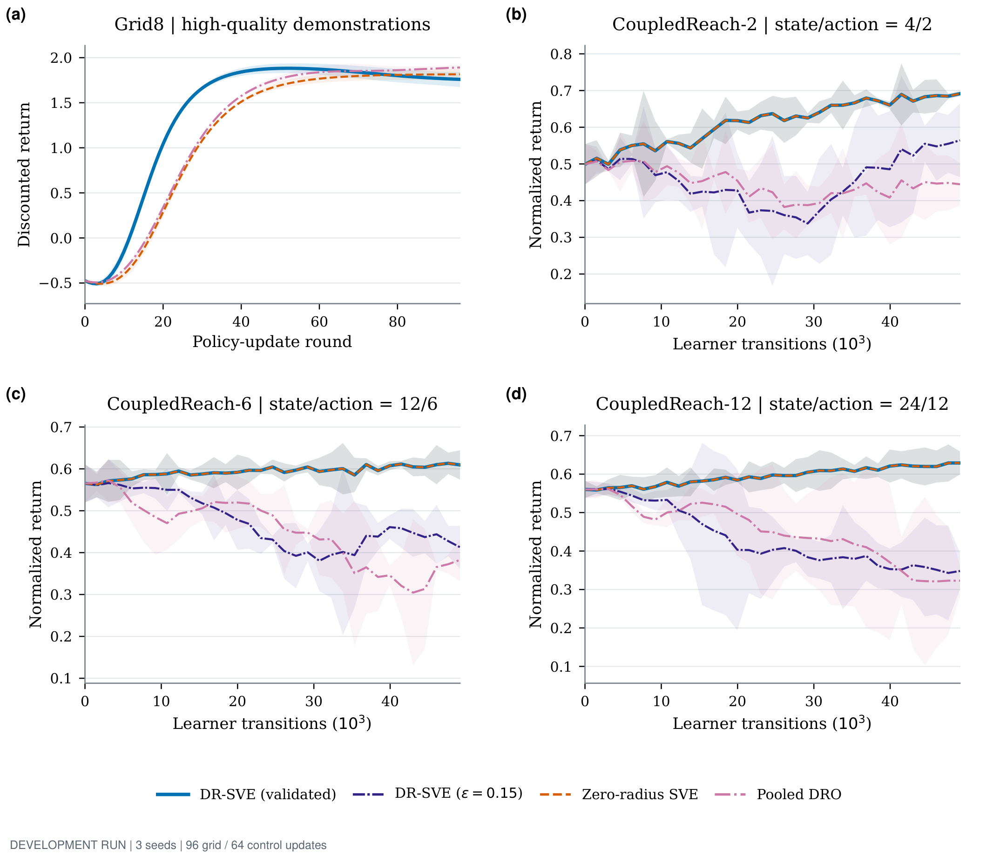

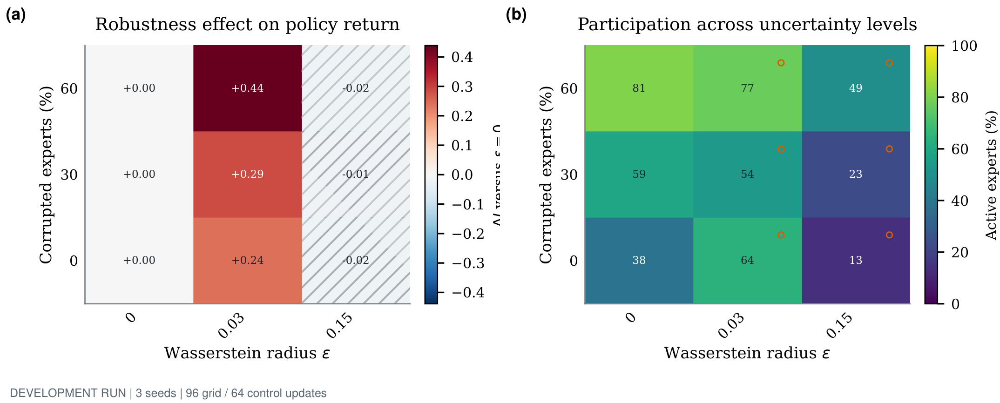

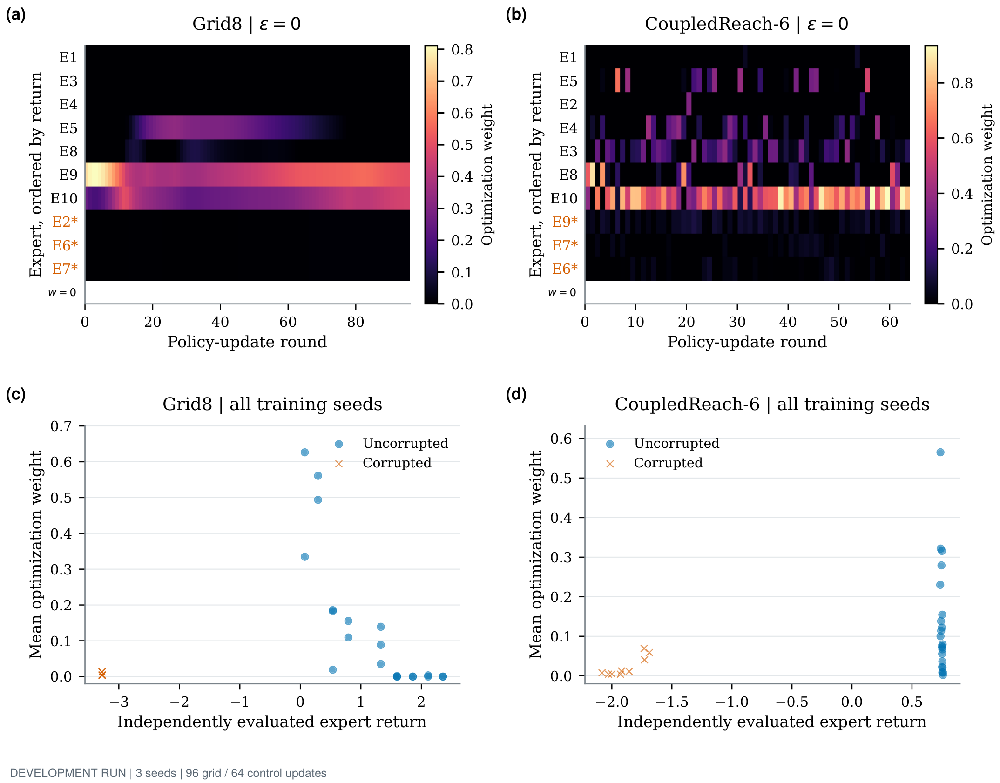

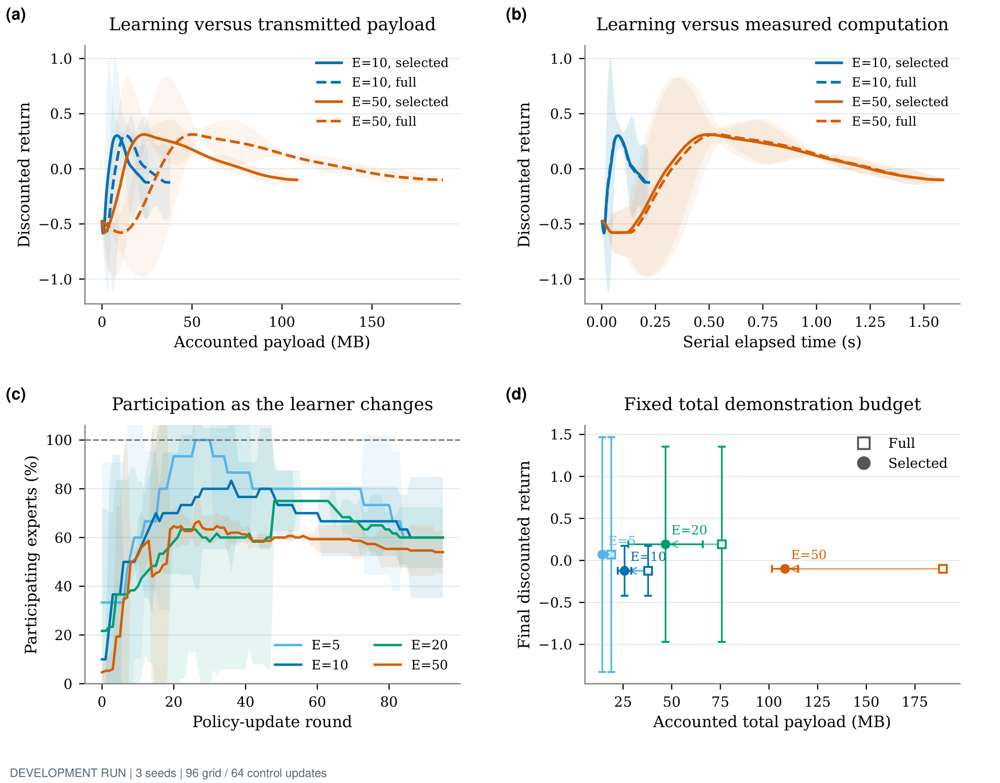

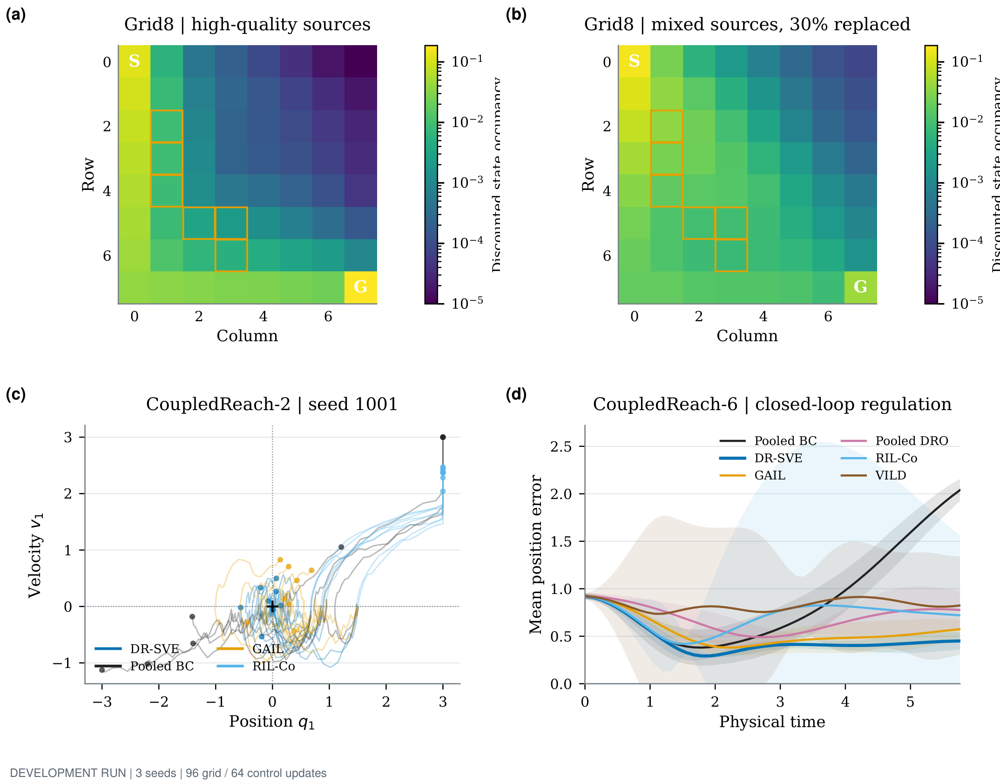

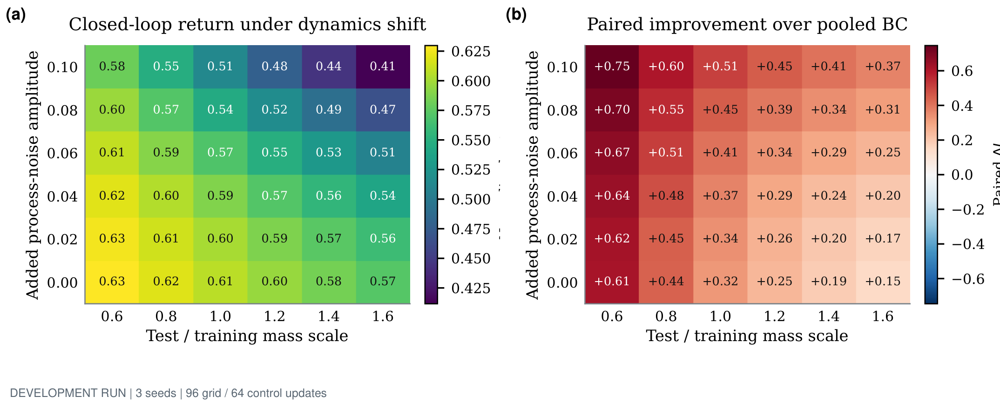

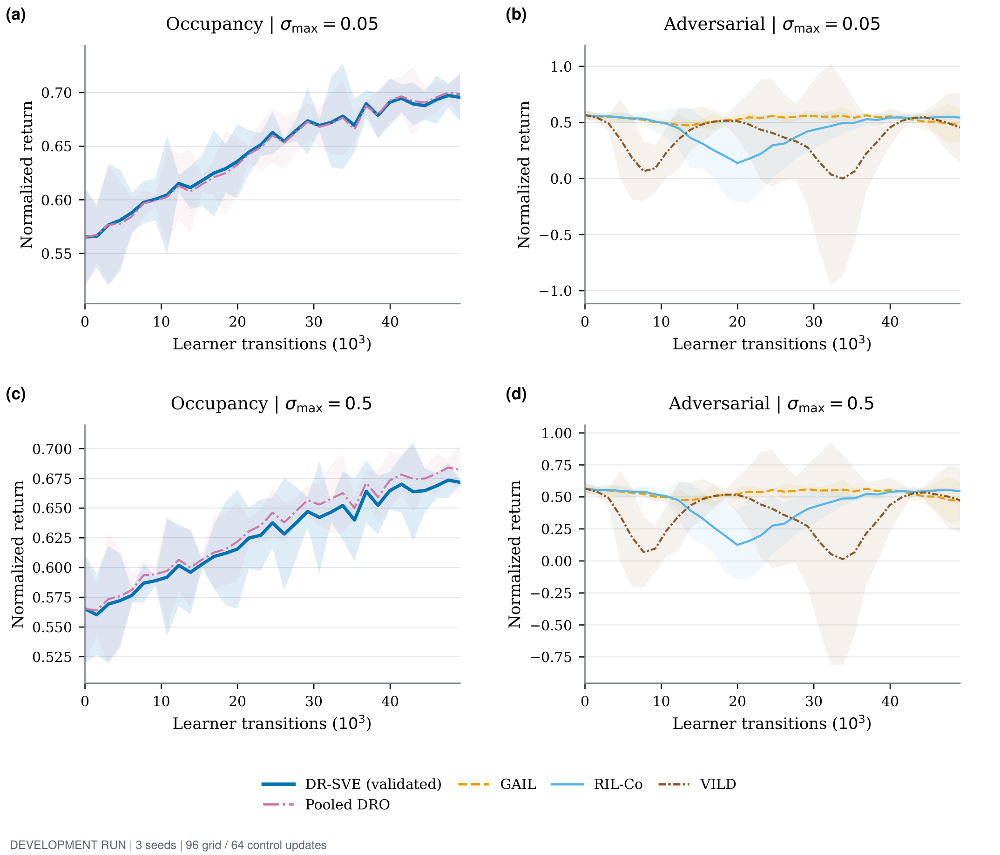

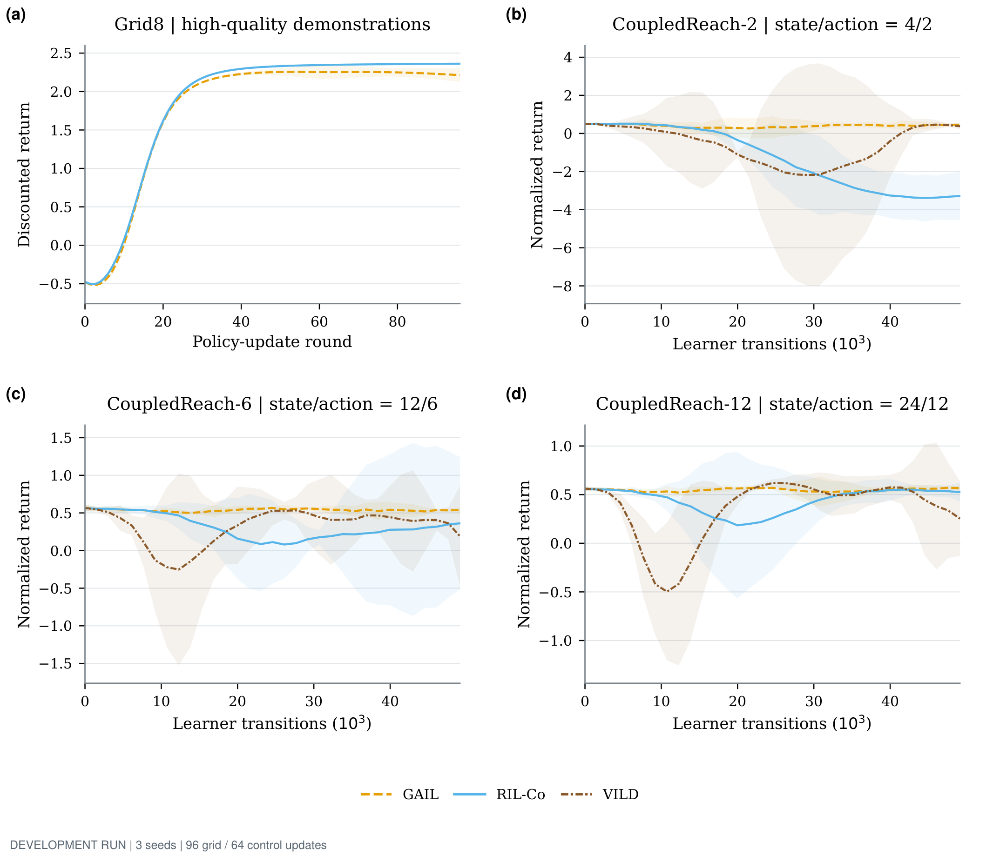

In [29]:
if RUN_B:
    B_OUT=B_RUN/"results"/B_PROFILE
    figure_files=sorted((B_OUT/"figures/main").glob("Fig*.png"))
    table_files=sorted((B_OUT/"tables").glob("Table0[1-4]*.html"))
else:
    figure_files=sorted((WORK/"saved_outputs/B").glob("figure_*.png"))
    table_files=sorted((WORK/"saved_outputs/B").glob("table_*.html"))
for path in figure_files: display(Image(filename=str(path)))
for path in table_files: display(HTML(path.read_text()))


## 5. Source identity and sharing
This check compares the written original modules against their source versions. Intentional edits are listed rather than forbidden. Both suites are runnable from this notebook, but their scientific settings differ; do not pool estimates or claim final convergence from the development outputs.

To share, send **this .ipynb**. In Colab, use File > Download > Download .ipynb. It includes all visible modules, supporting data/documentation and the saved outputs. No ZIP or previous notebook is required.

In [30]:
expected=json.loads((WORK/"ORIGINAL_SOURCE_HASHES.json").read_text())
changed=[name for name,digest in expected.items() if hashlib.sha256((WORK/name).read_bytes()).hexdigest()!=digest]
print("Original source modules:",len(expected))
print("Intentional edits:",changed if changed else "None; all original modules match exactly.")
print("Run settings:",{"A":RUN_A,"A_profile":A_PROFILE,"B":RUN_B,"B_profile":B_PROFILE})


Original source modules: 22
Intentional edits: None; all original modules match exactly.
Run settings: {'A': False, 'A_profile': 'review', 'B': False, 'B_profile': 'review'}
